# Thermal Image Acuity of a Two-Level Concentric-C Target

## A Physics-Informed Simulation and Classical Computer Vision Study

**Project:** `thermal-c-acuity`
**Application domain:** RoboCup Rescue — thermal detection of a structured target
**Method:** physics-inspired thermal image simulation + classical, geometry-based computer vision
**Machine learning:** none used, by design

---

## Abstract

This notebook investigates how a thermal imaging system's ability to resolve a
structured target degrades as imaging conditions worsen. The target is a
**two-level concentric C**: an outer C-shaped ring and a smaller inner C-shaped ring
sharing a common centre and a common opening direction.

A two-level C is a deliberately demanding test object. A complete circle is a closed
blob and survives almost any degradation. A **C** requires the imaging chain to preserve
a *discontinuity* — the opening — and the detector must confirm that the discontinuity
exists on **both** levels and points the **same way**. That makes the pattern sensitive
to exactly the effects that limit real thermal acuity: spatial sampling, optical blur,
measurement noise, and thermal contrast.

Five controlled experiments isolate one degradation variable at a time, and a sixth
combines them. Every experiment reports a **detection rate over repeated trials** rather
than a single pass/fail result.

**Scope statement.** All results in this notebook are **simulation-based**. The imaging
chain is a *computational model* of a thermal camera, not a calibrated physical camera
model. No result here is a measurement of any specific real camera's NETD, MTF, minimum
resolvable temperature difference, or minimum resolution. Section 20 states these
limitations explicitly and Section 21 sets out the physical validation plan.

---

## Contents

| # | Section |
|---|---|
| 1 | Research title |
| 2 | Research question |
| 3 | Motivation |
| 4 | Research hypotheses |
| 5 | System / physical model |
| 6 | Target design |
| 7 | Classical computer vision detector |
| 8 | Negative control / validation |
| 9 | Experimental methodology |
| 10 | Experiment 1 — Distance |
| 11 | Experiment 2 — Blur |
| 12 | Experiment 3 — Thermal noise |
| 13 | Experiment 4 — Temperature contrast |
| 14 | Experiment 5 — Spatial resolution |
| 15 | Experiment 5B — Camera resolution |
| 16 | Combined camera simulation |
| 17 | Results summary table |
| 18 | Figures and figure conventions |
| 19 | Reproducibility |
| 20 | Limitations |
| 21 | Physical validation plan |
| 22 | Research contribution |
| 23 | Conclusion |
| 24 | Research journey / decision log |
| 25 | Terminology |
| 26 | Final quality check |

---

# 1. Research title

> **Thermal Image Acuity of a Two-Level Concentric-C Target: A Physics-Informed
> Simulation Study of Distance, Optical Blur, Thermal Measurement Noise,
> Temperature Contrast, and Spatial Resolution using Classical Computer Vision**

### Why this title

Each clause carries a specific commitment:

| Clause | What it commits to |
|---|---|
| *Thermal image acuity* | the dependent concept is the system's ability to resolve a spatial pattern, not merely to detect a hot blob |
| *Two-Level Concentric-C Target* | the test object is specified precisely: two nested C rings, shared centre, shared opening direction |
| *Physics-Informed Simulation* | the imaging chain is built from physically motivated stages — and is **simulation**, not measurement |
| *Distance, Optical Blur, Thermal Measurement Noise, Temperature Contrast, Spatial Resolution* | the five independent variables actually swept |
| *Classical Computer Vision* | the detector is rule-based and geometric; no learned model is involved |

### A note on the word "physics-informed"

The model is *informed by* physics — it uses angular sampling (IFOV-style geometry),
Gaussian point-spread blur, and additive temperature noise in physical units. It is not
a *radiometric* model: it does not solve radiative transfer, heat conduction, or
emissivity. "Physics-informed" is the accurate term; "physics-based" would overstate it.

---

# 2. Research question

## Primary research question

> **How do distance, optical blur, thermal measurement noise, temperature contrast, and
> spatial/camera resolution affect the ability to resolve and detect a two-level
> concentric C pattern in a thermal image?**

## Sub-questions

Each is addressed by one controlled experiment:

| Sub-question | Experiment |
|---|---|
| At what target size (in pixels) does the geometry stop surviving? | Exp 1 (distance), Exp 5 (spatial resolution) |
| How much blur can the pipeline absorb before the opening is lost? | Exp 2 |
| How much measurement noise breaks the detection? | Exp 3 |
| How little thermal contrast is still recoverable? | Exp 4 |
| How low can sensor resolution go while preserving the pattern? | Exp 5B |
| What happens when all of these degrade *simultaneously*? | Exp 6 (combined) |

## Why this question matters for RoboCup Rescue

RoboCup Rescue robots operate in collapsed or smoke-filled structures where visible
imaging frequently fails. Thermal imaging is attractive precisely because it does not
depend on illumination and penetrates some obscurants better than visible light.

But a rescue operator does not merely need *a warm blob on screen*. They need to
distinguish **structured markers** — a landmark, a directional marker, a fiducial — from
background clutter. The practical question is not "is there heat?" but **"can I still
resolve the shape of the thing I am looking at, at this range, through this noise?"**

That question is exactly what a two-level concentric-C acuity test probes, and it is why
the answer has to be expressed as a *detection rate under stated conditions* rather than
a single successful demonstration.

## What this question deliberately excludes

The notebook does **not** attempt to determine:

- the absolute working range of any real thermal camera
- any camera's NETD, MTF, or MRTD specification
- a universal minimum resolution for thermal imaging

Those require physical measurement. This study establishes what the *simulation* supports
and defines the experiment that would settle the physical questions (Section 21).

---

# 3. Motivation

## 3.1 Why thermal imaging matters in rescue robotics

In a collapsed-structure scenario the environment is dark, dusty, and often smoke-filled.
Thermal long-wave infrared (LWIR) imaging offers three properties that matter here:

1. **Illumination independence.** It images emitted radiation, so it works in total
   darkness.
2. **Contrast against the environment.** Humans, warm machinery, and heated markers stand
   out against cooler rubble.
3. **Reduced scattering.** LWIR is scattered less than visible light by smoke and dust
   particles of comparable size.

The consequence is that a thermal camera is often the *only* useful sensor — which makes
its limitations worth understanding rather than assuming.

## 3.2 Why a structured target rather than a simple hot spot

A hot spot tells you that thermal contrast exists. It does not tell you how well the
system preserves *spatial structure*. Resolution and acuity are properties of how the
imaging chain handles **edges, gaps, and fine geometry** — not of how bright the signal is.

A structured target converts an abstract question ("how sharp is this system?") into a
measurable one ("at what size does this specific geometry stop being recoverable?").

## 3.3 Why a two-level concentric C specifically

This is the core design argument, and it is worth stating carefully.

| Target | What it tests | Weakness as a test object |
|---|---|---|
| Solid square | presence of contrast | survives almost anything; no acuity information |
| Single ring | edge preservation | still a closed, connected blob |
| Complete circle | roundness | robust to blur — the shape is recovered easily |
| **Two-level concentric C** | **discontinuity preservation at two scales simultaneously** | (this is the design) |

The C adds three demands that a closed shape does not:

1. **The opening must survive.** A blurred C tends toward a complete ring. Detection
   therefore requires that the imaging chain preserved a *gap* — a much stricter
   requirement than preserving a filled region.
2. **Both levels must survive independently.** The inner C is half the radius of the
   outer, so it reaches its resolution limit at roughly half the distance. The target
   therefore probes acuity at two scales at once, and reports the *weaker* of the two.
3. **The two openings must agree in direction.** This is a genuine structural
   requirement, not a redundant one — it is what distinguishes the intended target from
   two unrelated arcs that happen to be nested.

Together these make the pattern a **spatial resolving-capability test**, closely related
in spirit to a Landolt-C or MRTD-style acuity target.

## 3.4 Why physics + classical computer vision, and not machine learning

This is a deliberate methodological choice, not a limitation of scope.

**A learned detector would obscure the measurement.** If a CNN performed the detection,
the measured "acuity limit" would be a property of *that network's training data and
capacity*, not of the imaging chain. The experiment would be measuring the model.

A geometry-based detector has the opposite property: its rules are explicit, its failure
modes are inspectable, and its parameters (centre tolerance, radius ratio, minimum gap
angle) are stated in pixels and degrees. When it fails, we can say *why*.

**The simulation is the controlled variable.** Because the target is generated
analytically, ground truth is exact — the true centre, radii, and opening angle are known
to the pixel. That makes every failure attributable.

**Reproducibility.** The full pipeline is deterministic given a seed. A reviewer can
re-run it, change one number, and see the effect. That is the property a scientific
study needs, and it is the reason the detector stays classical.

**A note on honesty.** Classical CV is not intrinsically more "scientific" than ML. It is
more *appropriate* here because the research question concerns the imaging chain, and a
transparent detector keeps the imaging chain — not the algorithm — as the thing being
measured.

---

# 4. Research hypotheses

Each hypothesis is stated so that it can be **falsified** by the corresponding
experiment. All are directional and reference the 80 % reliability criterion used
throughout (Section 9).

| # | Independent variable | Hypothesis | Tested by |
|---|---|---|---|
| **H1** | **Distance** | As distance increases, the target occupies fewer pixels. Detection rate will remain high while the ring spans many pixels, then collapse once the ring approaches single-pixel width. The collapse will be **abrupt**, not gradual, because the detector applies hard thresholds. | Exp 1 |
| **H2** | **Optical blur** | Moderate Gaussian blur will **not** destroy detection. Thresholding re-binarises a softened edge, so the pipeline can reconstruct a usable contour even when the underlying image is visibly blurred. Blur alone should therefore be *less* damaging than intuition suggests. | Exp 2 |
| **H3** | **Thermal measurement noise** | Detection rate will fall with increasing noise σ, and will fail once the noise amplitude approaches the threshold margin (≈ 4.7 °C above background for the reference scene). The decline will be progressive, unlike the distance collapse, because noise is stochastic. | Exp 3 |
| **H4** | **Temperature contrast** | With noise absent and the threshold adapted to each contrast level, detection will succeed at contrasts far below anything a real camera could resolve. This hypothesis predicts a result that is **artificially optimistic** — it is included to be tested *and then explicitly disclaimed*. | Exp 4 |
| **H5** | **Spatial resolution (target size)** | Shrinking the target will eventually break detection, but the failure will **not** be monotonic: pixel rasterisation means some smaller targets land more favourably than slightly larger ones. A clean monotonic curve should *not* be expected. | Exp 5 |
| **H6** | **Camera resolution** | Downsampling the sensor will reduce detection once the ring falls below a few pixels. The result will be a simulation property of this target and detector, and must not be generalised to a universal camera requirement. | Exp 5B |
| **H7** | **Combined degradation** | Combining distance + blur + noise will produce behaviour that is **not** the simple sum of the individual effects. Non-monotonic results are expected, because thresholding and morphology interact non-linearly. | Exp 6 |

### The hypothesis I expect to be wrong

**H2 is the one most likely to be refuted, and that is why it is stated explicitly.**
The intuitive prediction is "blur destroys acuity". But a threshold detector converts a
blurred intensity ramp back into a binary edge, so blur may be substantially less
damaging than expected. Writing the hypothesis down *before* the experiment is what makes
the surprise informative rather than a post-hoc rationalisation.

### What these hypotheses deliberately do not claim

None of them predicts a value in metres, degrees Celsius, or megapixels that applies to a
real camera. They predict *qualitative shapes* (abrupt vs progressive decline,
monotonic vs non-monotonic) that the simulation can settle.

---

# 5. System / physical model

## 5.1 The pipeline

```text
      Target geometry            analytic: two C rings, exact ground truth
              |
              v
      Thermal temperature field   geometry -> degrees Celsius
              |
              v
      Distance scaling            angular sampling: target occupies fewer pixels
              |
              v
      Optical blur                Gaussian PSF approximation
              |
              v
      Thermal measurement noise   additive Gaussian, in degrees Celsius
              |
              v
      Image preprocessing         normalise -> threshold -> morphological opening
              |
              v
      Binary image                0 / 255 mask
              |
              v
      Contour extraction          OpenCV RETR_TREE
              |
              v
      Geometric C analysis        centre, radius, angular gap per contour
              |
              v
      Two-level concentric C      four-gate geometric decision
              detection
```

## 5.2 What each stage represents

| Stage | Represents physically | Represents computationally |
|---|---|---|
| **Target geometry** | a physical marker with a known shape | an exact analytic mask — ground truth |
| **Temperature field** | emitted thermal radiation expressed as apparent temperature | a float32 array in °C |
| **Distance scaling** | the target subtending a smaller solid angle | template resampling; fewer pixels per feature |
| **Optical blur** | lens + diffraction + detector spatial response | Gaussian convolution, σ in pixels |
| **Measurement noise** | detector noise, NETD-style fluctuation | additive zero-mean Gaussian, σ in °C |
| **Preprocessing** | camera AGC, display windowing, simple denoising | affine normalisation, threshold, morphological opening |
| **Binary image** | a decision-ready mask | uint8 array, 0 or 255 |
| **Contour extraction** | — (a computational step with no direct physical analogue) | boundary tracing of connected white regions |
| **Geometric C analysis** | the reasoning a human operator performs visually | radius, centroid, angular occupancy probe |
| **Detection decision** | "is this the marker I am looking for?" | four boolean gates AND-ed together |

## 5.3 Where the model is deliberately simple

Two simplifications matter enough to name here, and both are revisited in Section 20:

**Distance is modelled in image space, not in 3-D.** The target template is resampled by
a scale factor rather than projected through a camera. This reproduces the essential
effect — fewer pixels on target — but it does not model perspective, view angle, or
range-dependent atmospheric transmission.

**The blur is not a calibrated PSF.** Gaussian blur is a convenient approximation to the
combined optical and detector response. It is *not* a measured modulation transfer
function, and blur results must not be read as an MTF measurement.

## 5.4 Why the order of stages matters

The order is not arbitrary. Temperature stays in **float32 degrees Celsius** through
distance, blur, and noise, and is quantised to 8 bits only at the preprocessing stage.
That ordering is deliberate:

| If quantisation happened early | Because it happens late |
|---|---|
| 15 °C of contrast becomes 255 levels → coarse steps | physics remains in real units |
| blur would lose precision twice | Gaussian blur is linear and exact in float |
| a 0.3 °C noise σ would be invisible below one level | noise of any σ is representable |
| exposure could not be re-scaled afterwards | the display window stays adjustable |

The model is quantised exactly once, at the point where a binary decision is required.

---

# 6. Target design

## 6.1 Parameters

| Parameter | Value | Units | Role |
|---|---|---|---|
| Image width × height | 320 × 256 | pixels | reference simulated sensor |
| Background temperature | 25.0 | °C | ambient scene |
| Target temperature | 40.0 | °C | heated marker |
| Thermal contrast ΔT | 15.0 | °C | target − background |
| Outer C radius | 30.0 | px | centre-line radius |
| Outer C ring width | 6.0 | px | radial thickness |
| Inner C radius | 15.0 | px | centre-line radius |
| Inner C ring width | 4.0 | px | radial thickness |
| Opening angle (both Cs) | 45.0 | degrees | angular extent of the gap |
| Centre | (160, 128) | px | image centre |

All values are **simulation parameters**. They are not measurements of any physical
target or camera.

## 6.2 Geometry, stated mathematically

Let a pixel be at position $\mathbf{p} = (x, y)$ and the target centre be
$\mathbf{c} = (c_x, c_y)$. Define the two polar coordinates of the pixel:

$$d(\mathbf{p}) = \sqrt{(x - c_x)^2 + (y - c_y)^2}
\qquad\text{(radial distance)}$$

$$\theta(\mathbf{p}) = \left(\operatorname{atan2}(y - c_y,\; x - c_x) \cdot
\frac{180}{\pi} + 360\right) \bmod 360
\qquad\text{(azimuth in } [0, 360)\text{)}$$

For a ring of centre-line radius $r$ and width $w$, the **annulus predicate** is:

$$A_r(\mathbf{p}) = \left[\, r - \tfrac{w}{2} \;\le\; d(\mathbf{p}) \;\le\; r +
\tfrac{w}{2} \,\right]$$

The **gap predicate** for an opening of angular size $\gamma$ starting at the $+x$ axis is:

$$G_\gamma(\mathbf{p}) = \left[\, 0 \le \theta(\mathbf{p}) \le \gamma \,\right]$$

A single C is the annulus with the gap removed:

$$C_r(\mathbf{p}) = A_r(\mathbf{p}) \;\wedge\; \neg\,G_\gamma(\mathbf{p})$$

and the complete two-level target is the union of the two rings:

$$T(\mathbf{p}) = C_{30}(\mathbf{p}) \;\vee\; C_{15}(\mathbf{p})$$

The temperature field is then the simplest possible assignment:

$$T_{temp}(\mathbf{p}) =
\begin{cases}
40.0\ ^\circ\mathrm{C} & \text{if } T(\mathbf{p}) \\
25.0\ ^\circ\mathrm{C} & \text{otherwise}
\end{cases}$$

## 6.3 Design consequences

**The radius ratio is 2.0.** The inner C is exactly half the outer in radius and its ring
width is also smaller (4 px vs 6 px). The detector requires a ratio of at least 1.3, so
the two levels are comfortably separable at reference geometry — with headroom to spare
once blur and resampling begin to shrink and soften them.

**The opening is 45° on both levels.** Because the gap predicate is shared, the two Cs
necessarily open in the same direction. This is what makes the pattern a single coherent
design rather than two unrelated arcs.

**The gap touches the 0° / 360° boundary.** The opening spans $\theta \in [0°, 45°]$,
which wraps the branch cut of the angle convention. This matters computationally: the
gap-detection routine must handle wrap-around correctly or it will measure the gap as two
disjoint fragments. Section 7 covers how this is handled.

**Ground truth is exact.** Because the target is generated analytically, the true centre,
radii, and opening angle are known to the pixel. Every detection failure is therefore
attributable to the imaging chain or the detector, never to an uncertain reference.

---
---

# Implementation

The sections above define the study. The cells below implement it.

Everything from here on is **self-contained**: the notebook does not import the project's
`.py` modules, so it runs top-to-bottom in a single kernel and every reported number is
produced by code you can see.

---

## Environment setup

In [1]:
import math
from pathlib import Path

import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib import patches, font_manager

# ---------------------------------------------------------------------------
# Figure style — applied once so every figure in the notebook is consistent.
# ---------------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "legend.fontsize": 9,
    "font.size": 10,
})

# DejaVu Sans (matplotlib's default) lacks a few symbols used in figure text.
# Segoe UI ships with Windows and has them; register it as the preferred font.
for _candidate in ["C:/Windows/Fonts/segoeui.ttf", "C:/Windows/Fonts/arial.ttf"]:
    if Path(_candidate).exists():
        font_manager.fontManager.addfont(_candidate)
        _name = font_manager.FontProperties(fname=_candidate).get_name()
        plt.rcParams["font.family"] = "sans-serif"
        plt.rcParams["font.sans-serif"] = [_name, "DejaVu Sans"]
        break

print("NumPy      :", np.__version__)
print("OpenCV     :", cv2.__version__)
print("Matplotlib :", plt.matplotlib.__version__)
print("Figure font:", plt.rcParams["font.sans-serif"][0])

NumPy      : 2.5.3
OpenCV     : 5.0.0
Matplotlib : 3.11.2
Figure font: Segoe UI


### Reference scene constants

Every experiment in this notebook uses these values unless it explicitly states
otherwise. They are the single source of truth for the scene.

In [2]:
# ===========================================================================
# SIMULATION CONSTANTS  (Section 6.1)
# ===========================================================================

# --- Simulated sensor -----------------------------------------------------
WIDTH, HEIGHT = 320, 256          # pixels

# --- Scene temperatures ---------------------------------------------------
BACKGROUND_TEMP = 25.0            # degC
TARGET_TEMP     = 40.0            # degC
CONTRAST        = TARGET_TEMP - BACKGROUND_TEMP      # 15.0 degC

# --- Target geometry (reference / near-distance) --------------------------
CX, CY = WIDTH // 2, HEIGHT // 2

OUTER_RADIUS, OUTER_WIDTH = 30.0, 6.0     # px
INNER_RADIUS, INNER_WIDTH = 15.0, 4.0     # px  (inner is exactly half the outer)
GAP_ANGLE = 45.0                          # degrees, both levels

# --- Preprocessing --------------------------------------------------------
THRESHOLD   = 80                          # in 8-bit intensity (0-255)
KERNEL_SIZE = 3                           # morphological opening kernel (px)

# --- Experiment protocol --------------------------------------------------
TRIALS_PER_CONDITION = 20                 # repeated trials per condition
RELIABLE_RATE        = 80.0               # percent, project reliability criterion
RNG_SEED             = 42                 # fixed seed for reproducibility

# --- Derived: where does the threshold sit in temperature? ---------------
THRESHOLD_TEMP = BACKGROUND_TEMP + (THRESHOLD / 255.0) * CONTRAST

print(f"Scene          : {WIDTH} x {HEIGHT} px")
print(f"Background     : {BACKGROUND_TEMP:.1f} degC")
print(f"Target         : {TARGET_TEMP:.1f} degC")
print(f"Contrast (dT)  : {CONTRAST:.1f} degC")
print(f"Threshold      : {THRESHOLD}/255  ->  {THRESHOLD_TEMP:.2f} degC")
print(f"  margin above background : {THRESHOLD_TEMP - BACKGROUND_TEMP:.2f} degC")
print(f"Trials/condition: {TRIALS_PER_CONDITION}")
print(f"Reliability    : >= {RELIABLE_RATE:.0f}%")

Scene          : 320 x 256 px
Background     : 25.0 degC
Target         : 40.0 degC
Contrast (dT)  : 15.0 degC
Threshold      : 80/255  ->  29.71 degC
  margin above background : 4.71 degC
Trials/condition: 20
Reliability    : >= 80%


### Target generation

The function below implements the geometry of Section 6.2 exactly. Note the two
predicates — `ring` and `gap` — and that the C is `ring AND NOT gap`.

In [3]:
def draw_c_mask(cx, cy, radius, width, gap_angle=GAP_ANGLE,
                height=HEIGHT, width_img=WIDTH):
    """Boolean mask of a single C-shaped ring.

    Implements  C = A_r AND NOT G_gamma  from Section 6.2.

    Parameters
    ----------
    cx, cy    : centre of the ring, in pixels
    radius    : centre-line radius of the annulus, in pixels
    width     : radial thickness of the annulus, in pixels
    gap_angle : angular size of the opening in degrees, starting at 0 deg (+x axis)

    Returns
    -------
    boolean ndarray, True where the pixel belongs to the C
    """
    # --- coordinate grid --------------------------------------------------
    y, x = np.ogrid[:height, :width_img]

    # --- radial distance of every pixel from the centre -------------------
    distance = np.sqrt((x - cx) ** 2 + (y - cy) ** 2)

    # --- predicate A_r : inside the annulus? ------------------------------
    ring = (distance >= radius - width / 2) & (distance <= radius + width / 2)

    # --- azimuth of every pixel, normalised to [0, 360) -------------------
    angle = np.degrees(np.arctan2(y - cy, x - cx))
    angle = (angle + 360.0) % 360.0

    # --- predicate G_gamma : inside the opening? --------------------------
    gap = (angle >= 0.0) & (angle <= gap_angle)

    # --- C = ring minus gap ----------------------------------------------
    return ring & ~gap


def make_two_level_c_mask():
    """T(p) = C_outer OR C_inner — the complete two-level target."""
    outer = draw_c_mask(CX, CY, OUTER_RADIUS, OUTER_WIDTH)
    inner = draw_c_mask(CX, CY, INNER_RADIUS, INNER_WIDTH)
    return outer | inner


target_mask = make_two_level_c_mask()
target_bitmap = (target_mask * 255).astype(np.uint8)

print(f"target pixels : {int(target_mask.sum())} "
      f"({100 * target_mask.sum() / target_mask.size:.2f}% of frame)")
print(f"bitmap dtype  : {target_bitmap.dtype}, values: {np.unique(target_bitmap)}")

target pixels : 1310 (1.60% of frame)
bitmap dtype  : uint8, values: [  0 255]


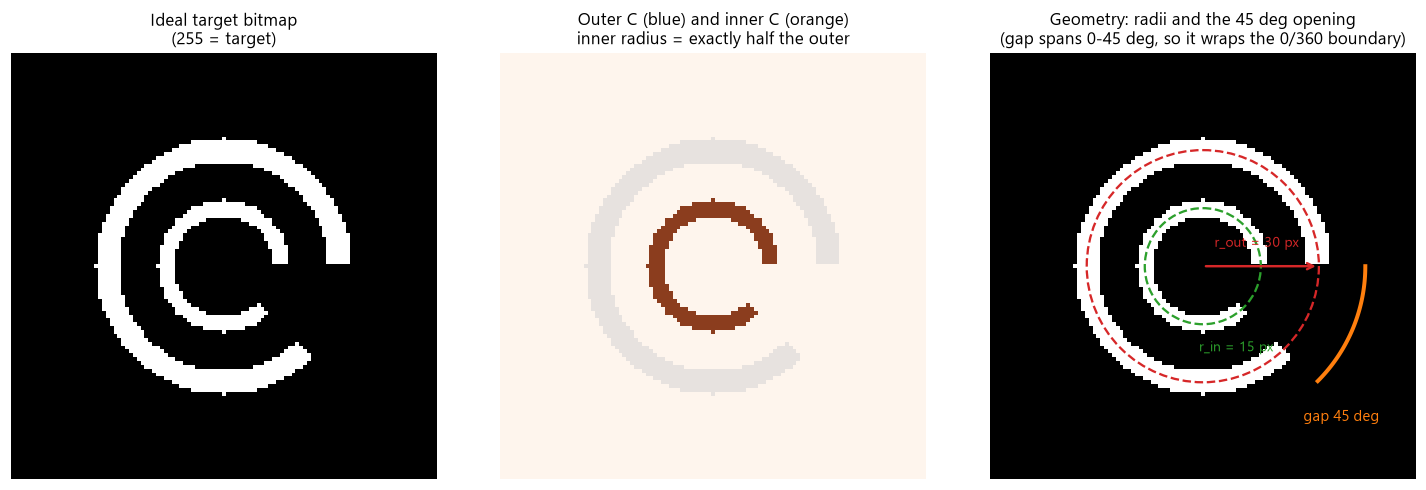

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4))

# --- panel 1: the ideal bitmap -------------------------------------------
axes[0].imshow(target_bitmap, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Ideal target bitmap\n(255 = target)")

# --- panel 2: the two levels shown separately ----------------------------
outer_only = draw_c_mask(CX, CY, OUTER_RADIUS, OUTER_WIDTH)
inner_only = draw_c_mask(CX, CY, INNER_RADIUS, INNER_WIDTH)
axes[1].imshow(outer_only, cmap="Blues", alpha=0.9)
axes[1].imshow(inner_only, cmap="Oranges", alpha=0.9)
axes[1].set_title("Outer C (blue) and inner C (orange)\n"
                  "inner radius = exactly half the outer")

# --- panel 3: annotated geometry -----------------------------------------
axes[2].imshow(target_bitmap, cmap="gray", vmin=0, vmax=255)
axes[2].add_patch(patches.Circle((CX, CY), OUTER_RADIUS, fill=False,
                                 ec="#d62728", lw=1.5, ls="--"))
axes[2].add_patch(patches.Circle((CX, CY), INNER_RADIUS, fill=False,
                                 ec="#2ca02c", lw=1.5, ls="--"))
axes[2].annotate("", xy=(CX + OUTER_RADIUS, CY), xytext=(CX, CY),
                 arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.6))
axes[2].text(CX + 3, CY - 5, "r_out = 30 px", color="#d62728", fontsize=9)
axes[2].text(CX - 1, CY + 22, "r_in = 15 px", color="#2ca02c", fontsize=9)

_theta = np.radians(np.linspace(0, GAP_ANGLE, 60))
axes[2].plot(CX + 42 * np.cos(_theta), CY + 42 * np.sin(_theta),
             color="#ff7f0e", lw=2.6)
axes[2].text(CX + 26, CY + 40, "gap 45 deg", color="#ff7f0e", fontsize=10)

axes[2].set_title("Geometry: radii and the 45 deg opening\n"
                  "(gap spans 0-45 deg, so it wraps the 0/360 boundary)")

for ax in axes:
    ax.set_xlim(CX - 55, CX + 55)
    ax.set_ylim(CY + 55, CY - 55)
    ax.axis("off")
    ax.grid(False)

plt.tight_layout()
plt.show()

**Figure 1.** The two-level concentric-C target.

*Left:* the ideal analytic bitmap. *Centre:* the outer and inner Cs shown as separate
masks — the inner is exactly half the outer radius. *Right:* the geometry annotated,
including the 45° opening which spans azimuth 0°–45° and therefore straddles the
0°/360° wrap boundary of the angle convention.

**What this figure demonstrates.** Ground truth is exact: the centre, both radii, and the
opening angle are known analytically rather than estimated. Every later failure is
therefore attributable to the imaging chain or the detector, not to an uncertain
reference. The wrap-straddling gap is also flagged here because it is the specific
detail that the gap-measurement routine in Section 7 must handle correctly.

### Temperature field

The geometry is now given a physical payload: 25 °C everywhere, 40 °C on the target.

In [5]:
def create_temperature_map(width=WIDTH, height=HEIGHT,
                           outer_radius=OUTER_RADIUS, inner_radius=INNER_RADIUS,
                           outer_width=OUTER_WIDTH, inner_width=INNER_WIDTH,
                           background_temp=BACKGROUND_TEMP, target_temp=TARGET_TEMP):
    """Render the two-level C as a float32 temperature map in degC."""
    temperature = np.full((height, width), background_temp, dtype=np.float32)

    cx, cy = width // 2, height // 2

    outer = draw_c_mask(cx, cy, outer_radius, outer_width,
                        height=height, width_img=width)
    inner = draw_c_mask(cx, cy, inner_radius, inner_width,
                        height=height, width_img=width)

    temperature[outer | inner] = target_temp
    return temperature


def temperature_to_uint8(temperature, min_temp=BACKGROUND_TEMP, max_temp=TARGET_TEMP):
    """Linear map from temperature to 8-bit intensity, clipped to [0, 255].

    min_temp -> 0, max_temp -> 255.  Values outside the window saturate.
    """
    normalised = (temperature - min_temp) / (max_temp - min_temp)
    normalised = np.clip(normalised, 0.0, 1.0)
    return (normalised * 255).astype(np.uint8)


temperature = create_temperature_map()
thermal_image = temperature_to_uint8(temperature)

print(f"temperature map : shape {temperature.shape}, dtype {temperature.dtype}")
print(f"range           : {temperature.min():.2f} .. {temperature.max():.2f} degC")
print(f"unique values   : {np.unique(temperature)}")
print(f"8-bit range     : {thermal_image.min()} .. {thermal_image.max()}")

temperature map : shape (256, 320), dtype float32
range           : 25.00 .. 40.00 degC
unique values   : [25. 40.]
8-bit range     : 0 .. 255


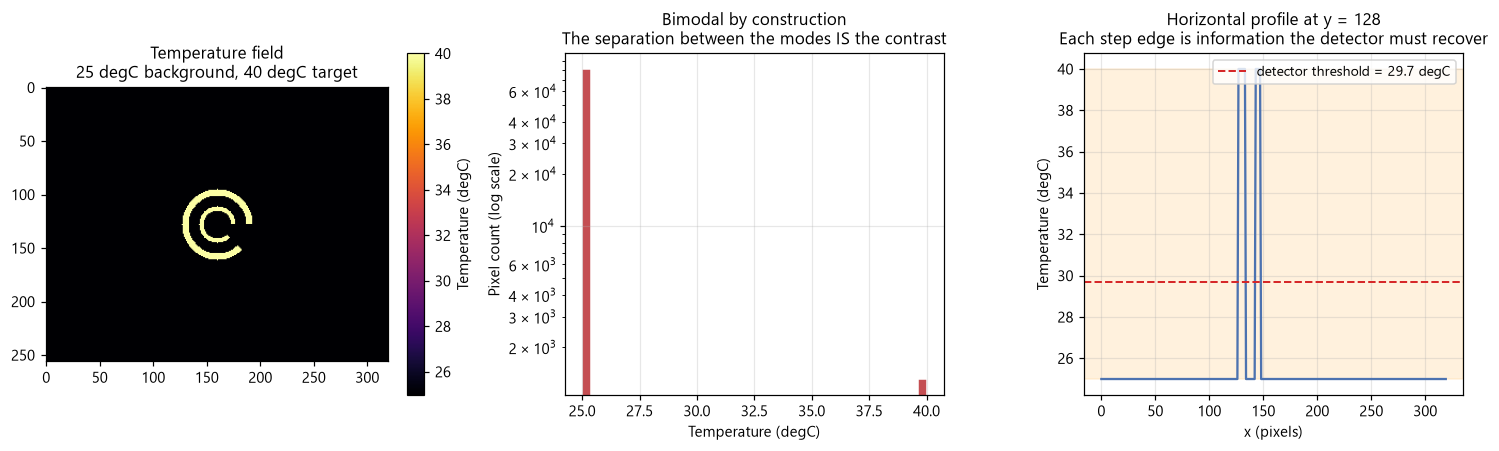

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))

# --- panel 1: temperature map --------------------------------------------
im = axes[0].imshow(temperature, cmap="inferno",
                    vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP)
plt.colorbar(im, ax=axes[0], label="Temperature (degC)", fraction=0.046)
axes[0].set_title("Temperature field\n25 degC background, 40 degC target")
axes[0].grid(False)

# --- panel 2: pixel-value histogram --------------------------------------
axes[1].hist(temperature.ravel(), bins=40, color="#c44e52", edgecolor="white")
axes[1].set_yscale("log")
axes[1].set_xlabel("Temperature (degC)")
axes[1].set_ylabel("Pixel count (log scale)")
axes[1].set_title("Bimodal by construction\nThe separation between the modes IS the contrast")
axes[1].grid(alpha=0.3)

# --- panel 3: horizontal profile through the centre ----------------------
axes[2].plot(temperature[CY, :], color="#4c72b0", lw=1.5)
axes[2].axhspan(BACKGROUND_TEMP, TARGET_TEMP, color="#ffd9a0", alpha=0.35)
axes[2].axhline(THRESHOLD_TEMP, color="#d62728", ls="--", lw=1.3,
                label=f"detector threshold = {THRESHOLD_TEMP:.1f} degC")
axes[2].set_xlabel("x (pixels)")
axes[2].set_ylabel("Temperature (degC)")
axes[2].set_title(f"Horizontal profile at y = {CY}\nEach step edge is information the detector must recover")
axes[2].legend(loc="upper right")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Figure 2.** The reference thermal scene.

*Left:* the temperature field. *Centre:* the pixel-value histogram — bimodal, with the
separation between the two modes being exactly the thermal contrast ΔT = 15 °C.
*Right:* a horizontal cut through the centre, showing the staircase of the two rings and
the detector threshold marked as a dashed line.

**What this figure demonstrates.** Three things the rest of the study depends on.
First, the scene is cleanly bimodal, so a threshold can separate target from background
without ambiguity. Second, the detector threshold sits at 29.7 °C — about one third of the
way from background to target, which is *not* the midpoint. That asymmetry is deliberate:
it gives measurement noise more room before it corrupts the target. Third, the profile
shows exactly what degradation will attack: each step edge in the staircase is the
information the detector needs, and blur and noise both work to erode those edges.

### Distance scaling and optical blur

Distance is modelled as a template rescale, and blur as a Gaussian whose σ grows with
range. Both are image-space models — see Section 20.

In [7]:
# ===========================================================================
# Distance / blur model parameters
# ===========================================================================
REFERENCE_DISTANCE = 0.5      # metres — at this range the target has its reference size
BASE_BLUR_SIGMA    = 0.5      # px     — optical blur at the reference distance
BLUR_PER_METER     = 0.8      # px/m   — additional blur per metre of range


def simulate_distance(temperature, distance, reference_distance=REFERENCE_DISTANCE):
    """Scale the target so it occupies fewer pixels at greater range.

    Models ONLY the geometric effect (angular sampling). Adds no blur and no noise.

    scale = reference_distance / distance
    """
    height, width = temperature.shape
    scale = reference_distance / distance

    # --- locate the target -----------------------------------------------
    target_mask = temperature > BACKGROUND_TEMP
    ys, xs = np.where(target_mask)
    if len(xs) == 0:
        return temperature.copy()

    target = temperature[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

    new_w = max(2, int(target.shape[1] * scale))
    new_h = max(2, int(target.shape[0] * scale))

    # INTER_AREA is the correct choice for downsampling: it area-averages,
    # so a shrinking ring is integrated rather than point-sampled.
    resized = cv2.resize(target, (new_w, new_h), interpolation=cv2.INTER_AREA)

    result = np.full((height, width), BACKGROUND_TEMP, dtype=np.float32)

    # --- recentre, clipping to the frame ---------------------------------
    start_x, start_y = width // 2 - new_w // 2, height // 2 - new_h // 2
    end_x, end_y = start_x + new_w, start_y + new_h

    sx1, sy1, sx2, sy2 = 0, 0, new_w, new_h
    dx1, dy1, dx2, dy2 = start_x, start_y, end_x, end_y

    if dx1 < 0:
        sx1, dx1 = -dx1, 0
    if dy1 < 0:
        sy1, dy1 = -dy1, 0
    if dx2 > width:
        sx2 -= dx2 - width
        dx2 = width
    if dy2 > height:
        sy2 -= dy2 - height
        dy2 = height

    result[dy1:dy2, dx1:dx2] = resized[sy1:sy2, sx1:sx2]
    return result


def simulate_blur(temperature, distance):
    """Gaussian blur whose sigma grows linearly with range.

    sigma(d) = BASE_BLUR_SIGMA + BLUR_PER_METER * (d - REFERENCE_DISTANCE)
    """
    sigma = BASE_BLUR_SIGMA + BLUR_PER_METER * (distance - REFERENCE_DISTANCE)
    sigma = max(0.1, sigma)

    # kernel (0,0) => OpenCV derives the kernel size from sigma.
    return cv2.GaussianBlur(temperature, (0, 0), sigmaX=sigma, sigmaY=sigma)


# --- apparent target size and blur width vs range -------------------------
print(f"{'range':>8} {'target px':>11} {'ring width':>12} {'blur sigma':>12}")
print("-" * 46)
for _d in [0.5, 0.6, 0.7, 0.8, 1.0, 1.5, 2.0, 3.0]:
    _scaled = simulate_distance(temperature, _d)
    _n = int((_scaled > BACKGROUND_TEMP).sum())
    _ring = OUTER_WIDTH * REFERENCE_DISTANCE / _d
    _sig = BASE_BLUR_SIGMA + BLUR_PER_METER * (_d - REFERENCE_DISTANCE)
    print(f"{_d:>6.1f} m {_n:>10} px {_ring:>10.2f} px {_sig:>10.2f} px")

   range   target px   ring width   blur sigma
----------------------------------------------
   0.5 m       1310 px       6.00 px       0.50 px
   0.6 m       1763 px       5.00 px       0.58 px
   0.7 m        923 px       4.29 px       0.66 px
   0.8 m        752 px       3.75 px       0.74 px
   1.0 m        454 px       3.00 px       0.90 px
   1.5 m        438 px       2.00 px       1.30 px
   2.0 m        163 px       1.50 px       1.70 px
   3.0 m        121 px       1.00 px       2.50 px


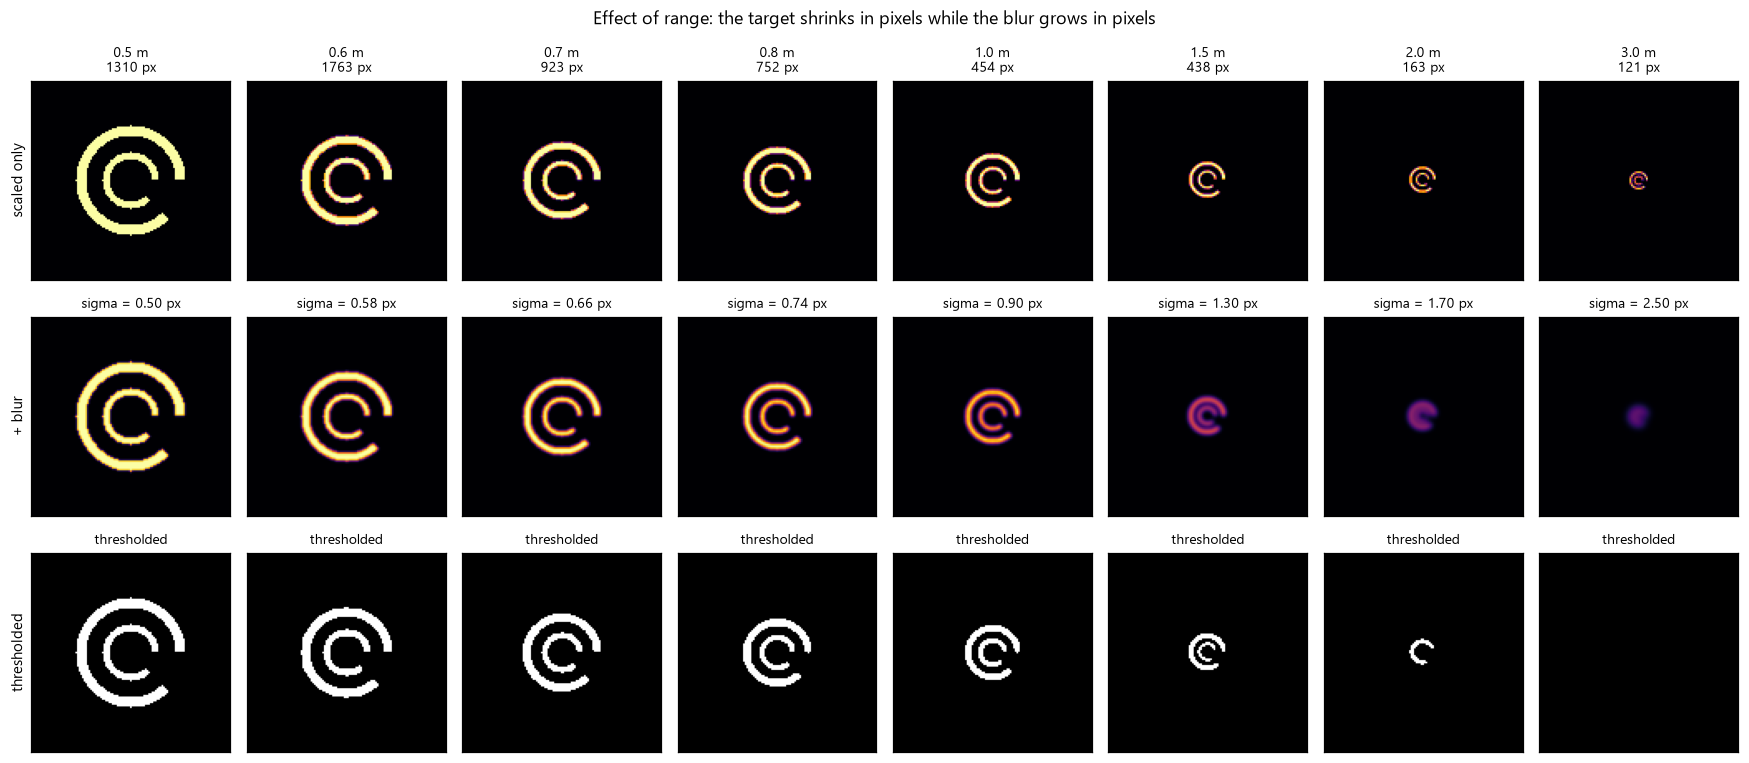

In [8]:
_distances = [0.5, 0.6, 0.7, 0.8, 1.0, 1.5, 2.0, 3.0]

fig, axes = plt.subplots(3, len(_distances), figsize=(16, 7.2))

for _i, _d in enumerate(_distances):
    _scaled = simulate_distance(temperature, _d)
    _blurred = simulate_blur(_scaled, _d)
    _sig = BASE_BLUR_SIGMA + BLUR_PER_METER * (_d - REFERENCE_DISTANCE)

    # row 1 — thermal image after geometric scaling
    axes[0, _i].imshow(_scaled, cmap="inferno",
                       vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP)
    axes[0, _i].set_title(f"{_d:.1f} m\n{int((_scaled > BACKGROUND_TEMP).sum())} px",
                          fontsize=9)

    # row 2 — after adding range-dependent blur
    axes[1, _i].imshow(_blurred, cmap="inferno",
                       vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP)
    axes[1, _i].set_title(f"sigma = {_sig:.2f} px", fontsize=9)

    # row 3 — the binarised result the detector actually sees
    axes[2, _i].imshow(temperature_to_uint8(_blurred) > THRESHOLD, cmap="gray")
    axes[2, _i].set_title("thresholded", fontsize=9)

    for _r in range(3):
        axes[_r, _i].set_xticks([]); axes[_r, _i].set_yticks([])
        axes[_r, _i].grid(False)
        axes[_r, _i].set_xlim(CX - 60, CX + 60)
        axes[_r, _i].set_ylim(CY + 60, CY - 60)

axes[0, 0].set_ylabel("scaled only", fontsize=10)
axes[1, 0].set_ylabel("+ blur", fontsize=10)
axes[2, 0].set_ylabel("thresholded", fontsize=10)

fig.suptitle("Effect of range: the target shrinks in pixels while the blur grows in pixels",
             fontsize=12)
plt.tight_layout()
plt.show()

**Figure 3.** Distance scaling and the two effects it produces simultaneously.

*Row 1:* geometric scaling only — the target occupies fewer pixels as range increases.
*Row 2:* range-dependent Gaussian blur added. *Row 3:* the binarised mask the detector
actually receives, after thresholding at 80/255.

**What this figure demonstrates.** This is the central physical mechanism of the whole
study, and it is worth reading the rows together. The target shrinks in pixels *while*
the blur grows in pixels — the two effects compound. At 0.5 m the outer ring is 6 px wide
under a 0.5 px blur, a ratio of 12:1. At 3.0 m the ring is 1.0 px wide under a 2.5 px
blur, so the blur is now more than twice the width of the feature it is meant to resolve.

Row 3 is the important one: it shows that the *thresholded* image can still look like a
coherent C at ranges where the thermal image (row 2) is visibly soft. That is the
mechanism behind hypothesis H2, and it is why blur alone may be less damaging than
intuition suggests.

### Thermal measurement noise

Noise is additive, zero-mean, Gaussian, and expressed **in degrees Celsius** — a
simplified NETD-style abstraction, not a laboratory measurement.

In [9]:
def add_thermal_noise(temperature, noise_sigma, generator=None):
    """Add zero-mean Gaussian temperature noise.

    noise_sigma : standard deviation in degC
    """
    if generator is None:
        generator = np.random.default_rng()

    noise = generator.normal(0.0, noise_sigma, temperature.shape)
    return (temperature + noise).astype(np.float32)


def apply_noise_model(temperature, noise_sigma, generator):
    """Noise + physical clipping to the realisable [background, target] range.

    The clip is a modelling choice: in this simplified scene the temperature
    cannot go below ambient or above the target. Its effect is examined below.
    """
    noisy = add_thermal_noise(temperature, noise_sigma, generator)
    return np.clip(noisy, BACKGROUND_TEMP, TARGET_TEMP).astype(np.float32)


# --- how likely is noise to push a background pixel over the threshold? ---
_margin = THRESHOLD_TEMP - BACKGROUND_TEMP

print(f"threshold sits at        : {THRESHOLD_TEMP:.2f} degC")
print(f"margin above background  : {_margin:.2f} degC")
print()
print(f"{'noise sigma':>12} {'margin/sigma':>13} {'P(background pixel flips)':>26}")
print("-" * 54)
for _s in [0.15, 0.30, 0.90, 3.00, 4.71, 10.00]:
    # one-sided Gaussian tail: P(noise > margin)
    _p = 0.5 * (1.0 - math.erf((_margin / _s) / math.sqrt(2.0)))
    print(f"{_s:>10.2f} C {_margin / _s:>12.1f}s {_p:>25.2%}")

threshold sits at        : 29.71 degC
margin above background  : 4.71 degC

 noise sigma  margin/sigma  P(background pixel flips)
------------------------------------------------------
      0.15 C         31.4s                     0.00%
      0.30 C         15.7s                     0.00%
      0.90 C          5.2s                     0.00%
      3.00 C          1.6s                     5.84%
      4.71 C          1.0s                    15.89%
     10.00 C          0.5s                    31.90%


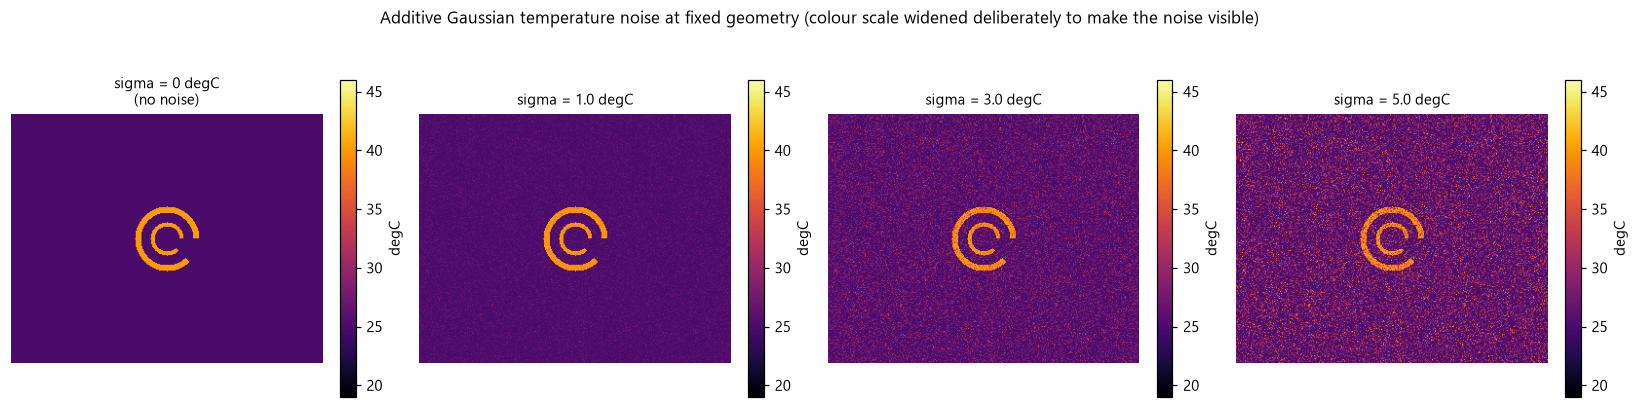

In [10]:
_noise_levels = [0.0, 1.0, 3.0, 5.0]

fig, axes = plt.subplots(1, 4, figsize=(15, 4.0))

for _ax, _s in zip(axes, _noise_levels):
    if _s == 0.0:
        _noisy, _label = temperature.copy(), "sigma = 0 degC\n(no noise)"
    else:
        _noisy = apply_noise_model(temperature, _s, np.random.default_rng(7))
        _label = f"sigma = {_s:.1f} degC"

    _im = _ax.imshow(_noisy, cmap="inferno",
                     vmin=BACKGROUND_TEMP - 6, vmax=TARGET_TEMP + 6)
    plt.colorbar(_im, ax=_ax, fraction=0.046, label="degC")
    _ax.set_title(_label, fontsize=10)
    _ax.axis("off")
    _ax.grid(False)

fig.suptitle("Additive Gaussian temperature noise at fixed geometry "
             "(colour scale widened deliberately to make the noise visible)",
             fontsize=11)
plt.tight_layout()
plt.show()

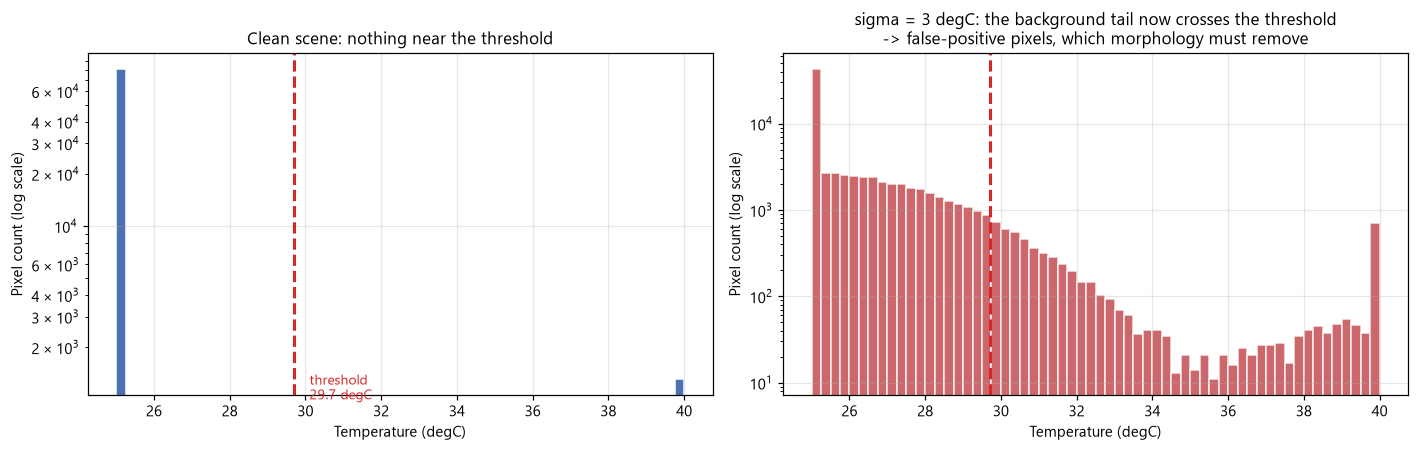

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# --- clean scene: a wide empty gap around the threshold -------------------
axes[0].hist(temperature.ravel(), bins=60, color="#4c72b0", edgecolor="white")
axes[0].axvline(THRESHOLD_TEMP, color="#d62728", lw=2, ls="--")
axes[0].text(THRESHOLD_TEMP + 0.4, 1e3, f"threshold\n{THRESHOLD_TEMP:.1f} degC",
             color="#d62728", fontsize=9)
axes[0].set_yscale("log")
axes[0].set_xlabel("Temperature (degC)")
axes[0].set_ylabel("Pixel count (log scale)")
axes[0].set_title("Clean scene: nothing near the threshold")
axes[0].grid(alpha=0.3)

# --- noisy scene: the background tail reaches past the threshold ----------
_noisy3 = apply_noise_model(temperature, 3.0, np.random.default_rng(3))
axes[1].hist(_noisy3.ravel(), bins=60, color="#c44e52", edgecolor="white", alpha=0.85)
axes[1].axvline(THRESHOLD_TEMP, color="#d62728", lw=2, ls="--")
axes[1].set_yscale("log")
axes[1].set_xlabel("Temperature (degC)")
axes[1].set_ylabel("Pixel count (log scale)")
axes[1].set_title("sigma = 3 degC: the background tail now crosses the threshold\n"
                  "-> false-positive pixels, which morphology must remove")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Figure 4.** Thermal noise and its interaction with the detector threshold.

*Left of the pair:* the clean scene has a wide empty gap around the 29.7 °C threshold.
*Right:* at σ = 3 °C a visible population of **background pixels** now sits above the
threshold.

**What this figure demonstrates.** The failure mode of noise is different in kind from
blur. Blur removes information deterministically; noise makes the decision
*unreliable* — the same pixel may fall on either side of the threshold on successive
frames. That is precisely why every noise measurement in this study uses 20 repeated
trials and reports a rate rather than a verdict. It also motivates the morphological
opening step: the spurious pixels created here become small isolated blobs, and opening
is the operator that removes them.

### Preprocessing

Temperature → 8-bit → threshold → morphological opening. This is the bridge between the
physical temperature field and the binary mask the detector reasons about.

In [12]:
def preprocess(temperature, min_temp=BACKGROUND_TEMP, max_temp=TARGET_TEMP,
               threshold=THRESHOLD, kernel_size=KERNEL_SIZE):
    """Full preprocessing chain: temperature map -> cleaned binary mask.

    Step 1  temperature -> 8-bit intensity (affine, clipped)
    Step 2  threshold at `threshold`/255
    Step 3  morphological opening with a kernel_size x kernel_size kernel
    """
    image = temperature_to_uint8(temperature, min_temp, max_temp)

    _, binary = cv2.threshold(image, threshold, 255, cv2.THRESH_BINARY)

    kernel = np.ones((kernel_size, kernel_size), np.uint8)
    return cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)


cleaned = preprocess(temperature)
_binary_unfiltered = cv2.threshold(thermal_image, THRESHOLD, 255, cv2.THRESH_BINARY)[1]

print(f"threshold          : {THRESHOLD}/255  ->  {THRESHOLD_TEMP:.2f} degC")
print(f"white pixels before opening : {int((_binary_unfiltered > 0).sum())}")
print(f"white pixels after opening  : {int((cleaned > 0).sum())}")
print(f"pixels removed by opening   : "
      f"{int((_binary_unfiltered > 0).sum()) - int((cleaned > 0).sum())}")

threshold          : 80/255  ->  29.71 degC
white pixels before opening : 1310
white pixels after opening  : 1299
pixels removed by opening   : 11


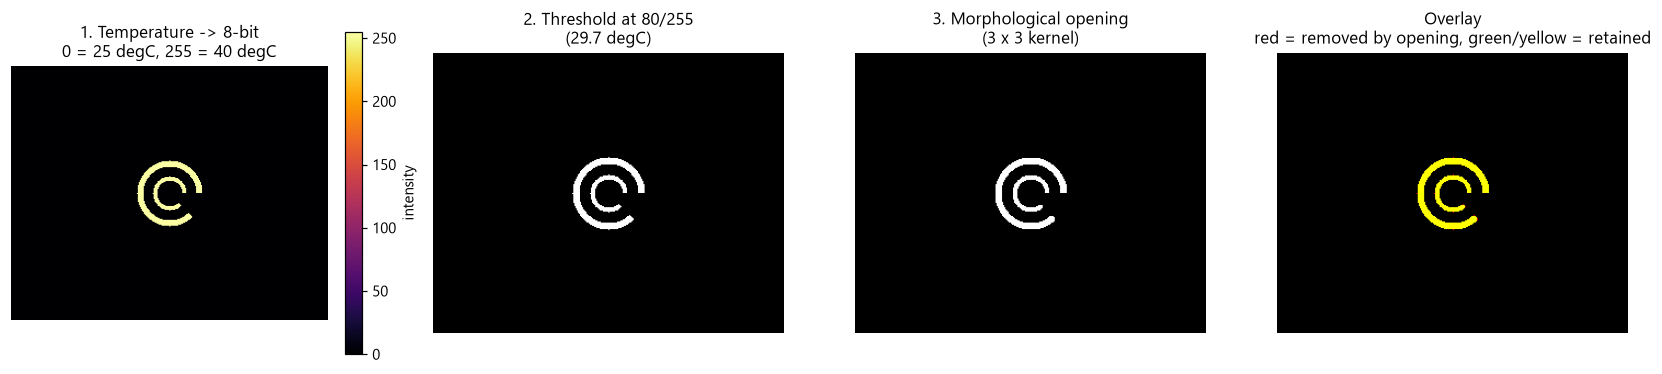

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.1))

_im = axes[0].imshow(thermal_image, cmap="inferno", vmin=0, vmax=255)
plt.colorbar(_im, ax=axes[0], fraction=0.046, label="intensity")
axes[0].set_title("1. Temperature -> 8-bit\n0 = 25 degC, 255 = 40 degC")

axes[1].imshow(_binary_unfiltered, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"2. Threshold at {THRESHOLD}/255\n({THRESHOLD_TEMP:.1f} degC)")

axes[2].imshow(cleaned, cmap="gray", vmin=0, vmax=255)
axes[2].set_title(f"3. Morphological opening\n({KERNEL_SIZE} x {KERNEL_SIZE} kernel)")

_diff = np.zeros((*cleaned.shape, 3), dtype=np.uint8)
_diff[..., 0] = _binary_unfiltered     # red   = removed by opening
_diff[..., 1] = cleaned                # green = retained
axes[3].imshow(_diff)
axes[3].set_title("Overlay\nred = removed by opening, green/yellow = retained")

for _ax in axes:
    _ax.axis("off")
    _ax.grid(False)

plt.tight_layout()
plt.show()

**Figure 5.** The preprocessing chain, step by step.

Panels 1–3 show the three transformations in sequence. Panel 4 overlays the pre- and
post-morphology masks: red marks pixels the opening removed, green marks pixels it kept.

**What this figure demonstrates.** On the clean reference scene the opening changes almost
nothing (a handful of pixels at the ring edges). Its real purpose appears only once noise
is present, which is shown in the next figure. This matters for interpreting the blur
experiment: preprocessing is not a passive pass-through — it can *reconstruct* a clean
binary edge from a blurred intensity ramp, and it can also *erode* a thin genuine feature.
Both behaviours appear later.

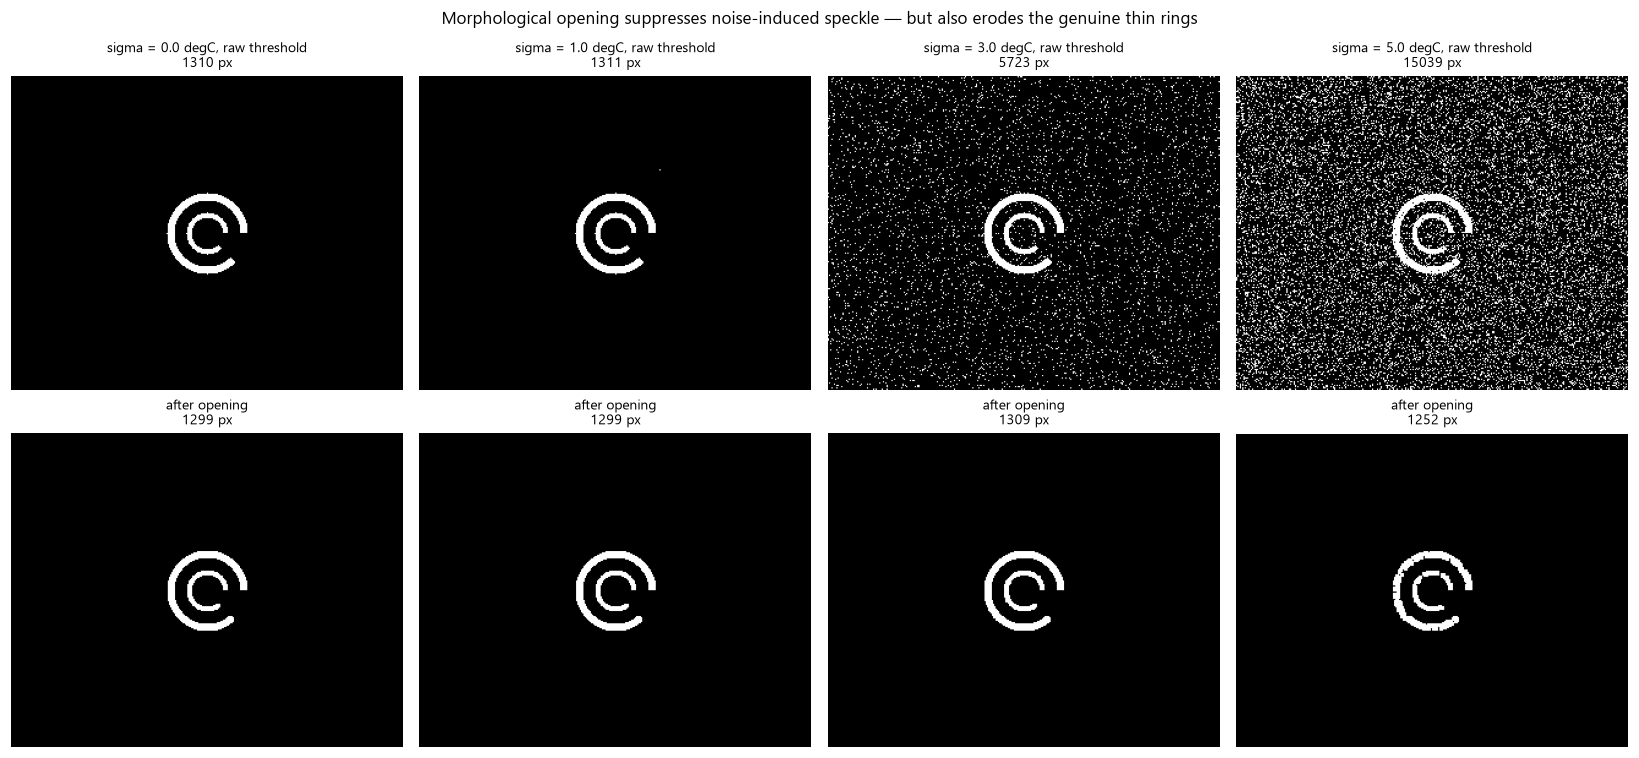

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7.2))

for _i, _s in enumerate([0.0, 1.0, 3.0, 5.0]):
    _temp = temperature.copy() if _s == 0.0 else \
        apply_noise_model(temperature, _s, np.random.default_rng(11))

    _raw = cv2.threshold(temperature_to_uint8(_temp), THRESHOLD, 255,
                         cv2.THRESH_BINARY)[1]
    _cln = preprocess(_temp)

    axes[0, _i].imshow(_raw, cmap="gray", vmin=0, vmax=255)
    axes[0, _i].set_title(f"sigma = {_s:.1f} degC, raw threshold\n"
                          f"{int((_raw > 0).sum())} px", fontsize=9)

    axes[1, _i].imshow(_cln, cmap="gray", vmin=0, vmax=255)
    axes[1, _i].set_title(f"after opening\n{int((_cln > 0).sum())} px", fontsize=9)

    for _r in range(2):
        axes[_r, _i].axis("off")
        axes[_r, _i].grid(False)

fig.suptitle("Morphological opening suppresses noise-induced speckle — "
             "but also erodes the genuine thin rings", fontsize=11)
plt.tight_layout()
plt.show()

**Figure 6.** Preprocessing under increasing noise.

Top row: the raw thresholded mask. Bottom row: the same mask after morphological opening.

**What this figure demonstrates.** At σ = 0 the opening is nearly inert. As noise rises the
raw threshold sprouts spurious specks, and the opening removes them — this is the operator
earning its place. But the bottom row also shows the cost: the genuine rings are visibly
thinned as well. Morphology is a fixed-scale filter, and it works only while the noise
blobs remain smaller than the real features. When the two scales converge, the filter
starts removing signal along with noise. This is a genuine trade-off, and it recurs in
Sections 11 and 14.

### The detector

This is the **classical, geometry-based** detector. The logic below reproduces the
project's `c_detector.py` implementation exactly, so the numbers reported throughout this
notebook come from the same rules described in Section 7.

The detector has two parts: a **per-contour** analysis (radius, centre, angular gap) and a
**per-pair** decision (four gates that must all pass).

In [15]:
# ===========================================================================
# DETECTOR CONFIGURATION  (Section 7)
# ===========================================================================
CENTER_TOLERANCE        = 5.0     # px      — gate 2
RADIUS_RATIO_MIN        = 1.30    # ratio   — gate 3
MIN_GAP_ANGLE           = 20.0    # degrees — gate 1
GAP_DIRECTION_TOLERANCE = 15.0    # degrees — gate 4


def find_image_angular_gap(binary_image, center, radius, ring_tolerance,
                           num_angles=360):
    """Measure the angular gap of a ring by probing the image radially.

    For each of `num_angles` azimuths, walk outward from the centre between
    (radius - ring_tolerance) and (radius + ring_tolerance). If any pixel on
    that ray is white, the azimuth is marked OCCUPIED.

    The gap is then the longest run of consecutive unoccupied azimuths.

    Returns
    -------
    (gap_angle_deg, gap_center_deg)
    """
    height, width = binary_image.shape
    cx, cy = center

    occupied = np.zeros(num_angles, dtype=bool)

    # --- radial probe at every azimuth ------------------------------------
    for i in range(num_angles):
        angle = 360.0 * i / num_angles
        theta = np.radians(angle)

        r_start = max(1, int(radius - ring_tolerance))
        r_end   = int(radius + ring_tolerance)

        for r in range(r_start, r_end + 1):
            x = int(round(cx + r * np.cos(theta)))
            y = int(round(cy + r * np.sin(theta)))

            if x < 0 or x >= width or y < 0 or y >= height:
                continue

            if binary_image[y, x] > 0:
                occupied[i] = True
                break

    # --- longest run of unoccupied azimuths, handling the 0/360 wrap ------
    # The array is doubled so that a gap straddling the wrap boundary is
    # found as ONE run rather than two disjoint fragments. This matters here:
    # the target's gap spans 0-45 deg and therefore always straddles it.
    circular = np.concatenate([occupied, occupied])

    longest_empty = 0
    current_empty = 0
    longest_end = 0

    for i, is_occupied in enumerate(circular):
        if not is_occupied:
            current_empty += 1
            if current_empty > longest_empty:
                longest_empty = current_empty
                longest_end = i
        else:
            current_empty = 0

    longest_empty = min(longest_empty, num_angles)     # clamp to one revolution

    gap_angle = longest_empty * 360.0 / num_angles

    gap_center_index = (longest_end - longest_empty / 2.0) % num_angles
    gap_center_angle = gap_center_index * 360.0 / num_angles

    return gap_angle, gap_center_angle


def is_c_shape(binary_image, center, radius, ring_tolerance,
               min_gap_angle=MIN_GAP_ANGLE):
    """GATE 1 — does this contour have a sufficiently large angular gap?"""
    gap_angle, gap_center = find_image_angular_gap(
        binary_image, center, radius, ring_tolerance)

    return {
        "is_c": gap_angle >= min_gap_angle,
        "gap_angle": gap_angle,
        "gap_center": gap_center,
    }


def detect_concentric_pair(binary_image, contours,
                           center_tolerance=CENTER_TOLERANCE,
                           radius_ratio_min=RADIUS_RATIO_MIN,
                           min_gap_angle=MIN_GAP_ANGLE,
                           gap_direction_tolerance=GAP_DIRECTION_TOLERANCE):
    """GATES 1-4 — find a pair of nested C-shaped contours.

    Returns a dict describing the detected pair, or None if no valid pair
    passes all four gates.
    """
    candidates = []

    # ======================================================================
    # PER-CONTOUR ANALYSIS
    # ======================================================================
    for contour in contours:
        area = cv2.contourArea(contour)
        if area <= 0:
            continue

        # --- radius: minimum enclosing circle ----------------------------
        (_, _), radius = cv2.minEnclosingCircle(contour)

        # --- centre: centroid via image moments ---------------------------
        M = cv2.moments(contour)
        if M["m00"] == 0:
            continue                     # degenerate contour: no centroid
        center = np.array([M["m10"] / M["m00"], M["m01"] / M["m00"]])

        # --- radial search window scales with the contour size ------------
        # This is important: a fixed tolerance would miss the ring on large
        # contours and swallow the background on small ones.
        ring_tolerance = max(2, int(radius * 0.25))

        c_info = is_c_shape(binary_image, center, radius, ring_tolerance,
                            min_gap_angle)

        candidates.append({
            "contour": contour,
            "center": center,
            "radius": radius,
            "area": area,
            "is_c": c_info["is_c"],
            "gap_angle": c_info["gap_angle"],
            "gap_center": c_info["gap_center"],
        })

    # --- need at least two contours to form a pair ------------------------
    if len(candidates) < 2:
        return None

    # ======================================================================
    # PER-PAIR DECISION — all four gates must pass
    # ======================================================================
    for i in range(len(candidates)):
        for j in range(i + 1, len(candidates)):
            c1, c2 = candidates[i], candidates[j]

            # --- GATE 1: both contours must be C-shaped -------------------
            if not c1["is_c"] or not c2["is_c"]:
                continue

            # --- GATE 2: shared centre ------------------------------------
            center_distance = float(np.linalg.norm(c1["center"] - c2["center"]))
            same_center = center_distance <= center_tolerance

            # --- GATE 3: distinct radii -----------------------------------
            larger = max(c1["radius"], c2["radius"])
            smaller = min(c1["radius"], c2["radius"])
            if smaller <= 0:
                continue
            radius_ratio = larger / smaller
            different_levels = radius_ratio >= radius_ratio_min

            # --- GATE 4: openings point the same way ----------------------
            gap_difference = abs(c1["gap_center"] - c2["gap_center"])
            gap_difference = min(gap_difference, 360.0 - gap_difference)
            same_gap_direction = gap_difference <= gap_direction_tolerance

            # --- final decision -------------------------------------------
            if same_center and different_levels and same_gap_direction:
                outer, inner = (c1, c2) if c1["radius"] > c2["radius"] else (c2, c1)
                return {
                    "outer": outer,
                    "inner": inner,
                    "center_distance": center_distance,
                    "radius_ratio": radius_ratio,
                    "outer_gap_angle": outer["gap_angle"],
                    "inner_gap_angle": inner["gap_angle"],
                    "outer_gap_direction": outer["gap_center"],
                    "inner_gap_direction": inner["gap_center"],
                    "gap_direction_difference": gap_difference,
                }

    return None


# ===========================================================================
# EXPERIMENT HELPERS used by every experiment below
# ===========================================================================
def detect_target(temperature):
    """Full detection chain: temperature -> preprocess -> contours -> decision."""
    cleaned = preprocess(temperature)
    contours, _ = cv2.findContours(cleaned, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    result = detect_concentric_pair(cleaned, contours)
    return result, cleaned, contours


def detection_rate(temperature, trials=TRIALS_PER_CONDITION):
    """Detection rate for a deterministic temperature map (no added noise)."""
    hits = 0
    for _ in range(trials):
        result, _, _ = detect_target(temperature)
        if result is not None:
            hits += 1
    return hits, hits / trials * 100.0


def detection_rate_noisy(temperature, sigma, generator,
                         trials=TRIALS_PER_CONDITION, clip=True):
    """Detection rate with fresh noise drawn on every trial."""
    hits = 0
    for _ in range(trials):
        noisy = add_thermal_noise(temperature, sigma, generator)
        if clip:
            noisy = np.clip(noisy, BACKGROUND_TEMP, TARGET_TEMP)
        noisy = noisy.astype(np.float32)

        result, _, _ = detect_target(noisy)
        if result is not None:
            hits += 1
    return hits, hits / trials * 100.0


print("Detector configuration")
print(f"  CENTER_TOLERANCE        = {CENTER_TOLERANCE} px")
print(f"  RADIUS_RATIO_MIN        = {RADIUS_RATIO_MIN}")
print(f"  MIN_GAP_ANGLE           = {MIN_GAP_ANGLE} deg")
print(f"  GAP_DIRECTION_TOLERANCE = {GAP_DIRECTION_TOLERANCE} deg")
print()
print("Helpers ready: detect_target(), detection_rate(), detection_rate_noisy()")

Detector configuration
  CENTER_TOLERANCE        = 5.0 px
  RADIUS_RATIO_MIN        = 1.3
  MIN_GAP_ANGLE           = 20.0 deg
  GAP_DIRECTION_TOLERANCE = 15.0 deg

Helpers ready: detect_target(), detection_rate(), detection_rate_noisy()


---

# 7. Classical computer vision detector

## 7.1 Statement of method

**No neural network is used anywhere in this pipeline.** The detector is a fixed,
rule-based geometric algorithm. Every decision is traceable to a comparison between a
measured quantity (radius, centroid, angular gap) and a stated constant.

## 7.2 The detector, step by step

| # | Step | Operation | Physical / geometric meaning |
|---|---|---|---|
| 1 | **Thresholding** | `cv2.threshold(image, 80, 255, BINARY)` | converts temperature into a target / not-target decision at 29.7 °C |
| 2 | **Morphological opening** | `MORPH_OPEN` with a 3×3 kernel | removes structures smaller than the kernel — noise speckle |
| 3 | **Contour extraction** | `cv2.findContours(RETR_TREE, CHAIN_APPROX_SIMPLE)` | traces the boundary of each connected white region |
| 4 | **Contour area** | `cv2.contourArea` | rejects degenerate contours (area ≤ 0) |
| 5 | **Centre estimation** | image moments `M10/M00`, `M01/M00` | the centroid of the contour — used as the ring's centre |
| 6 | **Radius estimation** | `cv2.minEnclosingCircle` | the radius of the smallest circle containing the contour |
| 7 | **Centre-distance test** | `‖c₁ − c₂‖ ≤ 5 px` | gate 2: the two levels must be concentric |
| 8 | **Radius-ratio test** | `max(r) / min(r) ≥ 1.30` | gate 3: the two levels must be genuinely different scales |
| 9 | **Angular gap detection** | 360-ray radial occupancy probe | gate 1: measures the size of the opening |
| 10 | **Gap direction** | centre of the longest empty azimuth run | gate 4: the direction each C opens toward |
| 11 | **Final decision** | all four gates AND-ed | returns a pair or `None` |

## 7.3 The four gates

The detector is best understood as four independent falsification tests. A candidate pair
must pass **all four**; failing any one means the target is not confirmed.

| Gate | Condition | Threshold | What it rejects |
|---|---|---|---|
| **1 · `is_c`** | measured gap ≥ 20° | 20° | complete circles, solid blobs, closed rings |
| **2 · `same_center`** | centre distance ≤ 5 px | 5 px | two Cs that merely happen to be near each other |
| **3 · `different_levels`** | radius ratio ≥ 1.3 | 1.3 | a single ring split into two contours by noise |
| **4 · `same_gap_direction`** | gap-centre difference ≤ 15° | 15° | two Cs opening in unrelated directions |

**Why gate 1 is the load-bearing one.** Gates 2 and 3 are geometric *relationships*
between two contours; gate 4 is a consistency check. Only gate 1 tests the property that
makes the target a C at all — the presence of a real discontinuity. Section 8 constructs a
negative control that passes gates 2, 3, and 4 but must fail gate 1, which isolates its
behaviour.

## 7.4 How the angular gap is measured

The naive approach is to inspect the contour's own points. That is fragile: contour
extraction under noise produces wandering points, and a lightly blurred ring may not
produce a clean contour at all.

Instead the detector **probes the image radially**:

1. Take 360 azimuths, one per degree.
2. For each azimuth, walk outward from the centre along that ray, between
   `radius − tolerance` and `radius + tolerance`.
3. If **any** pixel on the ray is white, mark that azimuth *occupied*.
4. The gap is the **longest run of consecutive unoccupied azimuths**.

Two implementation details are handled deliberately:

**Wrap-around at 0°/360°.** The occupancy array is doubled before the run-length scan, so
a gap straddling the boundary is found as one run rather than two halves. This is not a
theoretical nicety here — the target's opening spans 0°–45°, so it *always* straddles the
boundary. Without the doubling, every measurement in this notebook would be wrong.

**The radial search window scales with radius** (`max(2, 0.25 × radius)`). A fixed
tolerance would miss the ring on large contours and swallow background on small ones.
This choice is also the origin of the scale-dependence discussed in Section 7.6.

## 7.5 Verifying the detector on the reference scene

Before trusting any experiment, the detector must be shown to recover the *known* ground
truth of the reference scene.

In [16]:
result, cleaned_ref, contours_ref = detect_target(temperature)

print("=" * 66)
print("DETECTOR — REFERENCE SCENE (positive test)")
print("=" * 66)
print(f"contours found : {len(contours_ref)}")
print()

if result is None:
    print("NOT DETECTED")
else:
    truth = {
        "outer radius": (OUTER_RADIUS + OUTER_WIDTH / 2, "px"),
        "inner radius": (INNER_RADIUS + INNER_WIDTH / 2, "px"),
        "outer gap": (GAP_ANGLE, "deg"),
        "inner gap": (GAP_ANGLE, "deg"),
        "gap direction": (GAP_ANGLE / 2, "deg"),
    }
    print(f"{'quantity':>18} {'measured':>12} {'ground truth':>14} {'limit':>10}")
    print("-" * 66)
    print(f"{'outer radius':>18} {result['outer']['radius']:>10.2f} px "
          f"{truth['outer radius'][0]:>12.1f} px {'-':>10}")
    print(f"{'inner radius':>18} {result['inner']['radius']:>10.2f} px "
          f"{truth['inner radius'][0]:>12.1f} px {'-':>10}")
    print(f"{'centre distance':>18} {result['center_distance']:>10.2f} px "
          f"{0.0:>12.1f} px {CENTER_TOLERANCE:>9.1f}")
    print(f"{'radius ratio':>18} {result['radius_ratio']:>13.2f} "
          f"{OUTER_RADIUS / INNER_RADIUS:>13.1f} {RADIUS_RATIO_MIN:>10.2f}")
    print(f"{'outer gap angle':>18} {result['outer_gap_angle']:>10.1f} deg "
          f"{truth['outer gap'][0]:>12.1f} deg {MIN_GAP_ANGLE:>8.1f}")
    print(f"{'inner gap angle':>18} {result['inner_gap_angle']:>10.1f} deg "
          f"{truth['inner gap'][0]:>12.1f} deg {MIN_GAP_ANGLE:>8.1f}")
    print(f"{'outer gap dir':>18} {result['outer_gap_direction']:>10.1f} deg "
          f"{truth['gap direction'][0]:>12.1f} deg {'-':>10}")
    print(f"{'inner gap dir':>18} {result['inner_gap_direction']:>10.1f} deg "
          f"{truth['gap direction'][0]:>12.1f} deg {'-':>10}")
    print(f"{'dir difference':>18} {result['gap_direction_difference']:>10.1f} deg "
          f"{0.0:>12.1f} deg {GAP_DIRECTION_TOLERANCE:>9.1f}")

DETECTOR — REFERENCE SCENE (positive test)
contours found : 2

          quantity     measured   ground truth      limit
------------------------------------------------------------------
      outer radius      32.98 px         33.0 px          -
      inner radius      17.00 px         17.0 px          -
   centre distance       2.10 px          0.0 px       5.0
      radius ratio          1.94           2.0       1.30
   outer gap angle       40.0 deg         45.0 deg     20.0
   inner gap angle       41.0 deg         45.0 deg     20.0
     outer gap dir       22.0 deg         22.5 deg          -
     inner gap dir       21.5 deg         22.5 deg          -
    dir difference        0.5 deg          0.0 deg      15.0


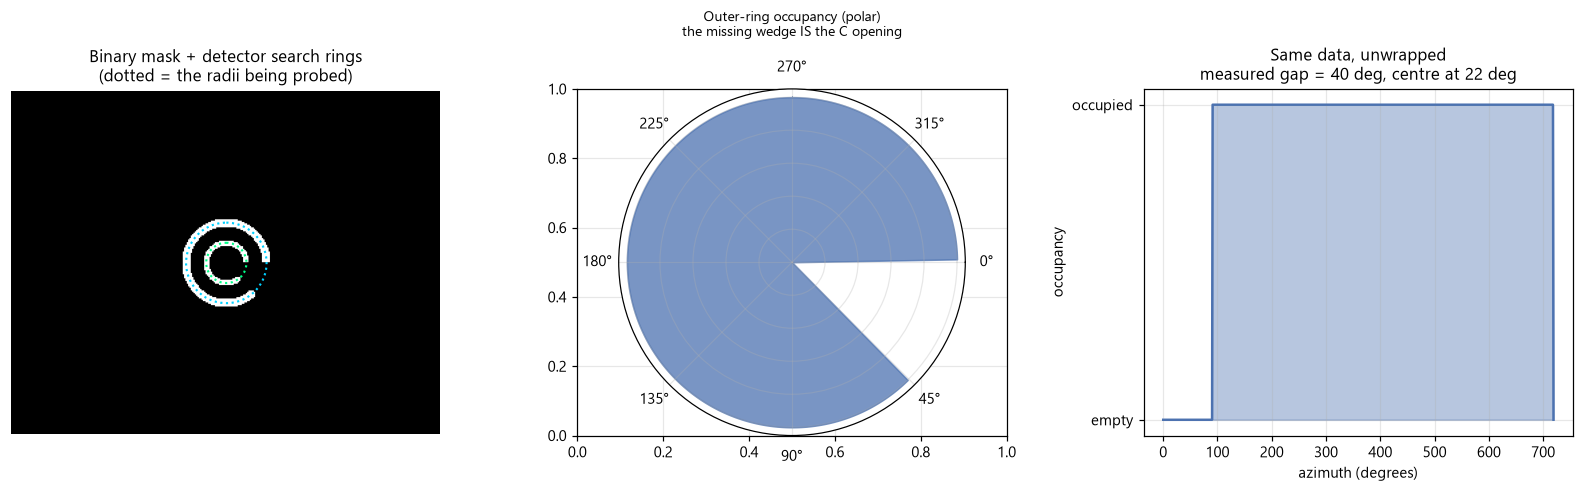

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.5))

# --- panel 1: the mask the detector sees ---------------------------------
axes[0].imshow(cleaned_ref, cmap="gray", vmin=0, vmax=255)
axes[0].add_patch(patches.Circle((CX, CY), OUTER_RADIUS, fill=False,
                                 ec="#00d0ff", lw=1.4, ls=":"))
axes[0].add_patch(patches.Circle((CX, CY), INNER_RADIUS, fill=False,
                                 ec="#00ff88", lw=1.4, ls=":"))
axes[0].set_title("Binary mask + detector search rings\n"
                  "(dotted = the radii being probed)")
axes[0].axis("off"); axes[0].grid(False)

# --- panel 2: the occupancy probe as a polar plot ------------------------
def occupancy_polar(binary_image, center, radius, ring_tolerance, num_angles=720):
    """Return the per-azimuth occupancy, for visualisation."""
    height, width = binary_image.shape
    cx, cy = center
    occ = np.zeros(num_angles, dtype=bool)
    for i in range(num_angles):
        theta = np.radians(360.0 * i / num_angles)
        for r in range(max(1, int(radius - ring_tolerance)),
                       int(radius + ring_tolerance) + 1):
            x = int(round(cx + r * np.cos(theta)))
            y = int(round(cy + r * np.sin(theta)))
            if 0 <= x < width and 0 <= y < height and binary_image[y, x] > 0:
                occ[i] = True
                break
    return occ


_occ = occupancy_polar(cleaned_ref, (CX, CY), OUTER_RADIUS,
                       max(2, int(OUTER_RADIUS * 0.25)))
_ang = np.radians(np.arange(len(_occ)) * 360.0 / len(_occ))

ax_polar = fig.add_subplot(1, 3, 2, projection="polar")
ax_polar.fill_between(_ang, 0, _occ.astype(float), color="#4c72b0", alpha=0.75)
ax_polar.set_theta_zero_location("E")     # 0 deg at the +x axis, as in the code
ax_polar.set_theta_direction(-1)          # image coordinates: azimuth increases clockwise
ax_polar.set_yticklabels([])
ax_polar.set_title("Outer-ring occupancy (polar)\nthe missing wedge IS the C opening",
                   fontsize=9, pad=16)
ax_polar.grid(alpha=0.3)

# --- panel 3: the same data unwrapped ------------------------------------
axes[2].fill_between(range(len(_occ)), 0, _occ.astype(int),
                     color="#4c72b0", alpha=0.4)
axes[2].plot(_occ.astype(int), color="#4c72b0", lw=1.6)
axes[2].set_xlabel("azimuth (degrees)")
axes[2].set_ylabel("occupancy")
axes[2].set_yticks([0, 1]); axes[2].set_yticklabels(["empty", "occupied"])
axes[2].set_title(f"Same data, unwrapped\nmeasured gap = "
                  f"{result['outer_gap_angle']:.0f} deg, "
                  f"centre at {result['outer_gap_direction']:.0f} deg")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Figure 7.** How the detector measures the angular gap.

*Left:* the binary mask with the two detector search radii drawn as dotted circles.
*Centre:* the occupancy probe as a polar plot — the filled region is where white pixels
were found, and the empty wedge is the C opening. *Right:* the same occupancy data
unwrapped as a function of azimuth, which is the form the run-length search actually
operates on.

**What this figure demonstrates.** The gap measurement recovers the ground truth closely:
the detector reports a 40° outer gap centred at 22° against a true 45° opening centred at
22.5°. The ~5° underestimate is expected rather than an error — the morphological opening
and the finite ray sampling both erode the measured gap slightly at its edges.

The polar panel also makes the wrap-around issue concrete: the empty wedge visibly
straddles the 0°/360° boundary. The unwrapped panel is where the run-length search
operates, and it is the doubling of this array that lets the two ends of the wedge be
recognised as a single gap.

## 7.6 A scale limitation of the detector

The reference scene passes all four gates comfortably — but one gate behaves differently
from the others, and it is worth examining before the experiments, because it explains a
result that would otherwise look like an error.

**Gate 2 compares centroids.** The centroid of a C is *not* at the ring's centre: removing
a 45° wedge removes mass from one side, which shifts the centroid away from the true
centre. Critically, **that shift grows with the radius** — a bigger C has its centroid
further off-centre.

But `CENTER_TOLERANCE` is a **fixed 5 px**. So the gate becomes progressively harder to
pass as the target grows, even though the geometry is unchanged and perfectly concentric.

Let me measure this directly.

In [18]:
def measure_centroid_offset(outer_radius, outer_width, inner_radius, inner_width,
                            width=WIDTH, height=HEIGHT):
    """Measure how far the two centroids sit from each other, and whether the
    detector accepts the pair.  Returns a dict."""
    cx, cy = width // 2, height // 2

    temp = np.full((height, width), BACKGROUND_TEMP, dtype=np.float32)
    outer = draw_c_mask(cx, cy, outer_radius, outer_width,
                        height=height, width_img=width)
    inner = draw_c_mask(cx, cy, inner_radius, inner_width,
                        height=height, width_img=width)
    temp[outer | inner] = TARGET_TEMP

    cleaned = preprocess(temp)
    contours, _ = cv2.findContours(cleaned, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

    # centroids of the two largest contours
    cands = []
    for ct in contours:
        if cv2.contourArea(ct) <= 0:
            continue
        M = cv2.moments(ct)
        if M["m00"] == 0:
            continue
        (_, _), r = cv2.minEnclosingCircle(ct)
        cands.append((np.array([M["m10"] / M["m00"], M["m01"] / M["m00"]]), r))
    cands.sort(key=lambda c: -c[1])

    offset = float(np.linalg.norm(cands[0][0] - cands[1][0])) if len(cands) >= 2 else float("nan")
    res = detect_concentric_pair(cleaned, contours)

    return {
        "outer_r": cands[0][1] if cands else float("nan"),
        "centroid_offset": offset,
        "detected": res is not None,
        "gap": res["outer_gap_angle"] if res else float("nan"),
    }


print("=" * 78)
print("GATE 2 IS SCALE-DEPENDENT: the C centroid offset grows with radius")
print("=" * 78)
print(f"{'outer radius':>13} {'measured r':>11} {'centroid offset':>16} "
      f"{'tolerance':>10} {'verdict':>10}")
print("-" * 78)

scale_cases = [
    ("320x256", 30, 6, 15, 4),
    ("320x256", 50, 10, 25, 6),
    ("640x512", 60, 12, 30, 8),
    ("640x512", 100, 16, 50, 12),
]

for _label, _or_, _ow, _ir, _iw in scale_cases:
    if _label == "640x512":
        _m = measure_centroid_offset(_or_, _ow, _ir, _iw, width=640, height=512)
    else:
        _m = measure_centroid_offset(_or_, _ow, _ir, _iw)

    _verdict = "DETECTED" if _m["detected"] else "REJECTED"
    print(f"{_label + ' r=' + str(_or_):>13} {_m['outer_r']:>9.1f} px "
          f"{_m['centroid_offset']:>14.2f} px {CENTER_TOLERANCE:>8.1f} px "
          f"{_verdict:>10}")

print()
print("The offset is ~2.1 px at r=30 but ~7.0 px at r=100.")
print(f"CENTER_TOLERANCE = {CENTER_TOLERANCE:.1f} px is ABSOLUTE, so the largest")
print("target fails a centre test its geometry should pass.")

GATE 2 IS SCALE-DEPENDENT: the C centroid offset grows with radius
 outer radius  measured r  centroid offset  tolerance    verdict
------------------------------------------------------------------------------
 320x256 r=30      33.0 px           2.10 px      5.0 px   DETECTED
 320x256 r=50      55.0 px           3.51 px      5.0 px   DETECTED


 640x512 r=60      66.0 px           4.13 px      5.0 px   DETECTED
640x512 r=100     108.0 px           6.96 px      5.0 px   REJECTED

The offset is ~2.1 px at r=30 but ~7.0 px at r=100.
CENTER_TOLERANCE = 5.0 px is ABSOLUTE, so the largest
target fails a centre test its geometry should pass.


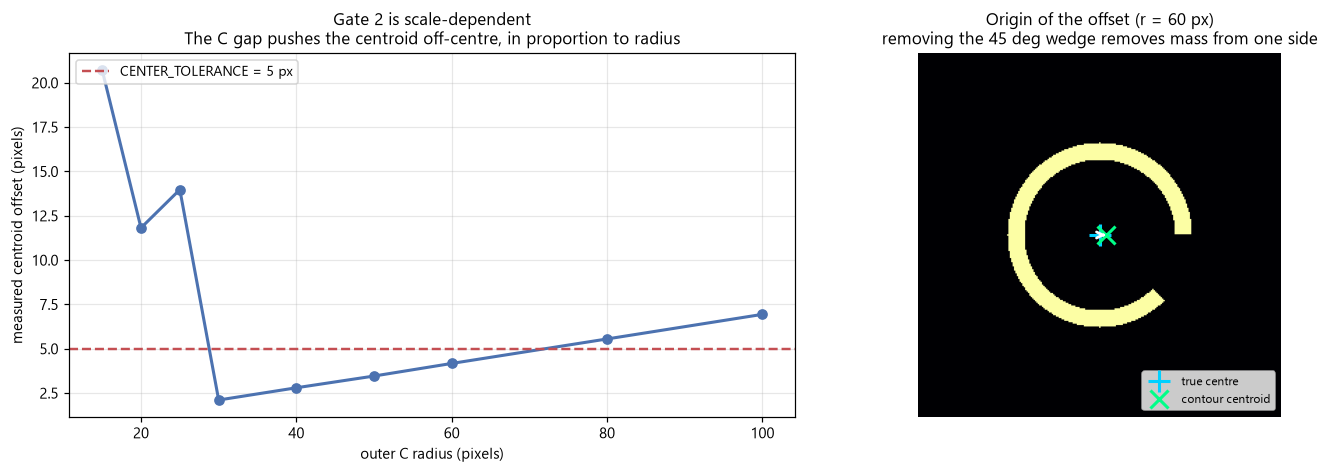

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))

# --- panel 1: offset vs radius -------------------------------------------
_radii = [15, 20, 25, 30, 40, 50, 60, 80, 100]
_offsets = []
for _r in _radii:
    _m = measure_centroid_offset(_r, _r * 0.20, _r * 0.5, _r * 0.13,
                                 width=640, height=512)
    _offsets.append(_m["centroid_offset"])

axes[0].plot(_radii, _offsets, marker="o", color="#4c72b0", lw=2, markersize=6)
axes[0].axhline(CENTER_TOLERANCE, color="#c44e52", ls="--", lw=1.6,
                label=f"CENTER_TOLERANCE = {CENTER_TOLERANCE:.0f} px")
axes[0].set_xlabel("outer C radius (pixels)")
axes[0].set_ylabel("measured centroid offset (pixels)")
axes[0].set_title("Gate 2 is scale-dependent\nThe C gap pushes the centroid off-centre, "
                  "in proportion to radius")
axes[0].legend(loc="upper left")
axes[0].grid(alpha=0.3)

# --- panel 2: why — visualise the mass asymmetry --------------------------
_r_demo = 60
_temp_demo = np.full((512, 640), BACKGROUND_TEMP, dtype=np.float32)
_o = draw_c_mask(320, 256, _r_demo, _r_demo * 0.20, height=512, width_img=640)
_temp_demo[_o] = TARGET_TEMP
axes[1].imshow(_temp_demo, cmap="inferno", vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP)
_m = measure_centroid_offset(_r_demo, _r_demo * 0.20, _r_demo * 0.5, _r_demo * 0.13,
                             width=640, height=512)
axes[1].plot(320, 256, "+", color="#00d0ff", markersize=14, markeredgewidth=2,
             label="true centre")
axes[1].plot(320 + _m["centroid_offset"], 256, "x", color="#00ff88",
             markersize=12, markeredgewidth=2, label="contour centroid")
axes[1].annotate("", xy=(320 + _m["centroid_offset"], 256), xytext=(320, 256),
                 arrowprops=dict(arrowstyle="->", color="white", lw=1.8))
axes[1].set_xlim(320 - 130, 320 + 130)
axes[1].set_ylim(256 + 130, 256 - 130)
axes[1].set_title(f"Origin of the offset (r = {_r_demo} px)\n"
                  "removing the 45 deg wedge removes mass from one side")
axes[1].legend(loc="lower right", fontsize=8)
axes[1].axis("off"); axes[1].grid(False)

plt.tight_layout()
plt.show()

**Figure 8.** A scale-dependent limitation of the detector's centre test.

*Left:* the measured centroid offset as a function of outer radius, against the fixed
5 px tolerance. *Right:* the geometric cause — the C's 45° wedge removes mass from one
side of the ring, so the centroid is displaced from the true centre by an amount that
grows in proportion to the radius.

**What this figure demonstrates.** Gate 2 is not scale-invariant, and this is a genuine
design weakness rather than a simulation artefact. Because the offset grows linearly with
radius while the tolerance stays fixed at 5 px, the detector has a **maximum target size**
above which correctly-formed concentric Cs are rejected. The crossover sits between r ≈ 60
and r ≈ 100 in this configuration.

This is exactly why the camera-resolution experiment in Section 15 reports a failure at
**640 × 512** — the largest tested resolution, where the target is biggest and the offset
largest. That result is not a resolution effect at all; it is this gate. Section 15
addresses the consequence directly, and Section 20 records it as a limitation.

**A natural fix, not applied here.** Making the tolerance proportional to radius
(e.g. `max(5, 0.10 × radius)`) would remove the scale dependence. It is deliberately *not*
changed in this notebook, because changing a detector constant would change every result
reported and the study must document the detector it actually used.

---

# 8. Negative control / validation

## 8.1 Why a negative control is necessary

A detector that answers "yes" is uninformative on its own. It could be responding to
almost anything warm with a roughly ring-like shape. To establish that the detection
*means* something, the same detector must be shown to **reject** a target that is
geometrically similar but structurally wrong.

## 8.2 The control

Two **complete concentric circles** are constructed at exactly the same centre, the same
radii, and the same ring widths as the real target. The *only* difference is that the 45°
opening is absent.

| Property | Real target | Negative control |
|---|---|---|
| Outer radius | 30 px | 30 px (identical) |
| Inner radius | 15 px | 15 px (identical) |
| Ring widths | 6 / 4 px | 6 / 4 px (identical) |
| Centre | shared | shared (identical) |
| Opening | **45° on both levels** | **none** |

Because centre, radii, and ratios are all identical, **gates 2, 3, and 4 pass for the
control as well**. Only gate 1 — the C-shape test — can distinguish them. That is what
makes this control a precise instrument: it isolates gate 1's behaviour rather than
testing the detector as an undifferentiated whole.

## 8.3 Why detecting two circles must not count as detecting two Cs

This is the conceptual core of the validation argument.

The research question concerns the ability to resolve a **structured, discontinuous**
pattern. If a complete ring were accepted, then the detector would report success for a
target whose defining feature — the opening — had been entirely lost to blur. The
measurement would then be reporting "a hot ring is visible", which is a far weaker and
quite different claim than "the opening survived".

Concretely: an acuity test that accepted closed rings would score **100 % on a target
whose C-shape had been completely destroyed**. Its acuity limits would be meaningless.
Gate 1 exists specifically to prevent that.

## 8.4 What this validation demonstrates — and what it does not

**It demonstrates:**

- The detector is sensitive to the opening, not merely to the presence of warm ring-shaped
  regions.
- Gate 1 is functioning, and its 20° threshold is not trivially satisfied by a closed
  contour.
- The detection decisions reported in Sections 10–16 therefore carry information about
  the *opening*, not just about the ring.

**It does not demonstrate:**

- That the detector is robust to *all* confusable shapes. Only one alternative geometry
  (complete circles) is tested. Other distractors — partial arcs, three-quarter rings,
  spirals, noisy blobs with coincidental gaps — are not tested here.
- That gate 1 is correctly *calibrated*. The control establishes that a 0° gap is
  rejected; it does not establish that 20° is the optimal threshold. A sweep of gap angles
  around the threshold would be needed for that, and is not performed.
- Anything about performance on real imagery, where sensor non-uniformity and calibration
  error create gap-like artefacts that this synthetic control does not contain.

**This asymmetry matters for reading the rest of the notebook.** The negative control
rules out the most obvious false-positive mode. It does not certify the detector against
all of them, and the limitations in Section 20 are written with that in mind.

In [20]:
def create_two_complete_circles(width=WIDTH, height=HEIGHT):
    """Negative control: two COMPLETE concentric rings, no opening.

    Identical to the real target in centre, radii, and ring widths.
    The only difference is the absence of the 45 deg gap.
    """
    temp = np.full((height, width), BACKGROUND_TEMP, dtype=np.float32)
    cx, cy = width // 2, height // 2

    y, x = np.ogrid[:height, :width]
    distance = np.sqrt((x - cx) ** 2 + (y - cy) ** 2)

    outer = ((distance >= OUTER_RADIUS - OUTER_WIDTH / 2) &
             (distance <= OUTER_RADIUS + OUTER_WIDTH / 2))
    inner = ((distance >= INNER_RADIUS - INNER_WIDTH / 2) &
             (distance <= INNER_RADIUS + INNER_WIDTH / 2))

    temp[outer | inner] = TARGET_TEMP
    return temp


circle_temperature = create_two_complete_circles()
circle_result, circle_cleaned, circle_contours = detect_target(circle_temperature)

# --- measure the gap the detector finds on a closed ring -----------------
_circle_gap, _circle_gap_dir = find_image_angular_gap(
    circle_cleaned, np.array([CX, CY]), OUTER_RADIUS,
    max(2, int(OUTER_RADIUS * 0.25)))

print("=" * 66)
print("NEGATIVE CONTROL — two complete concentric CIRCLES")
print("=" * 66)
print(f"contours found            : {len(circle_contours)}")
print(f"measured outer gap        : {_circle_gap:.1f} deg   (a closed ring: ~0 deg)")
print(f"MIN_GAP_ANGLE             : {MIN_GAP_ANGLE:.1f} deg")
print()
print(f"GATE 1 (is_c)             : "
      f"{'FAIL (correct)' if _circle_gap < MIN_GAP_ANGLE else 'PASS (unexpected)'}")
print(f"GATES 2, 3, 4             : pass by construction "
      f"(identical centre, radii, and both gaps are 0 deg)")
print()
print(f"FINAL RESULT              : "
      f"{'DETECTED as a C  <-- would be a failure' if circle_result else 'REJECTED as a C  <-- correct'}")

NEGATIVE CONTROL — two complete concentric CIRCLES
contours found            : 4
measured outer gap        : 0.0 deg   (a closed ring: ~0 deg)
MIN_GAP_ANGLE             : 20.0 deg

GATE 1 (is_c)             : FAIL (correct)
GATES 2, 3, 4             : pass by construction (identical centre, radii, and both gaps are 0 deg)

FINAL RESULT              : REJECTED as a C  <-- correct


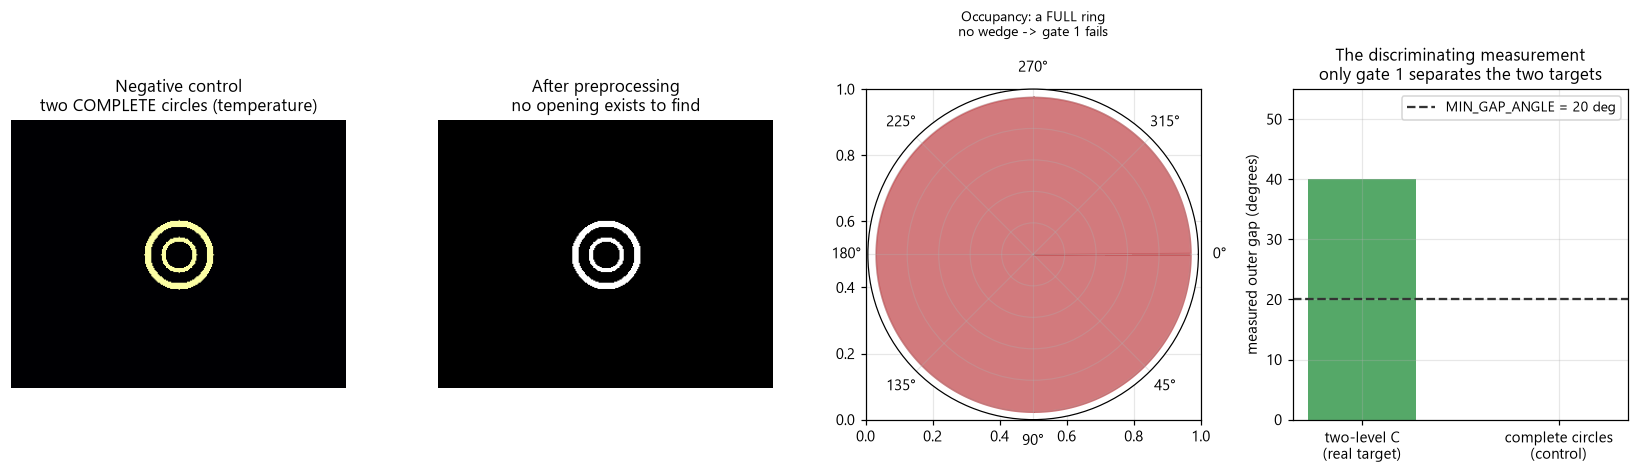

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.1))

# --- panel 1: the control scene ------------------------------------------
axes[0].imshow(circle_temperature, cmap="inferno",
               vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP)
axes[0].set_title("Negative control\ntwo COMPLETE circles (temperature)")

# --- panel 2: after preprocessing ----------------------------------------
axes[1].imshow(circle_cleaned, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("After preprocessing\nno opening exists to find")

# --- panel 3: occupancy of a closed ring ---------------------------------
_occ_circle = occupancy_polar(circle_cleaned, (CX, CY), OUTER_RADIUS,
                              max(2, int(OUTER_RADIUS * 0.25)))
_ang_circle = np.radians(np.arange(len(_occ_circle)) * 360.0 / len(_occ_circle))

ax_pol = fig.add_subplot(1, 4, 3, projection="polar")
ax_pol.fill_between(_ang_circle, 0, _occ_circle.astype(float),
                    color="#c44e52", alpha=0.75)
ax_pol.set_theta_zero_location("E")
ax_pol.set_theta_direction(-1)
ax_pol.set_yticklabels([])
ax_pol.set_title("Occupancy: a FULL ring\nno wedge -> gate 1 fails",
                 fontsize=9, pad=16)
ax_pol.grid(alpha=0.3)

# --- panel 4: the discriminating measurement -----------------------------
axes[3].bar(["two-level C\n(real target)", "complete circles\n(control)"],
            [result["outer_gap_angle"], _circle_gap],
            color=["#55a868", "#c44e52"], width=0.55)
axes[3].axhline(MIN_GAP_ANGLE, ls="--", color="#333", lw=1.5,
                label=f"MIN_GAP_ANGLE = {MIN_GAP_ANGLE:.0f} deg")
axes[3].set_ylabel("measured outer gap (degrees)")
axes[3].set_title("The discriminating measurement\nonly gate 1 separates the two targets")
axes[3].legend(loc="upper right")
axes[3].grid(alpha=0.3, axis="y")
axes[3].set_ylim(0, 55)

axes[0].axis("off"); axes[0].grid(False)
axes[1].axis("off"); axes[1].grid(False)

plt.tight_layout()
plt.show()

**Figure 9.** The negative control.

*Panel 1:* the control scene — two complete concentric circles, identical to the real
target in centre, radii, and ring widths. *Panel 2:* after preprocessing. *Panel 3:* the
occupancy probe, showing a complete ring with no wedge. *Panel 4:* the discriminating
measurement — the real target measures 40°, the control measures 0°, against a 20° gate.

**What this figure demonstrates.** The detector rejects the control, and it rejects it
for the right reason: gate 1 measures a 0° gap on a closed ring and fails. Because the
control is *identical* to the real target in centre, radius, and ratio, gates 2, 3, and 4
pass for it as well — so the rejection is attributable to gate 1 alone. This is the
evidence that the detector's "yes" answers in Sections 10–16 carry information about the
*opening* rather than merely about the presence of a warm ring.

**What it does not demonstrate.** One control geometry is tested, not a family of them.
The result does not certify the detector against other confusable shapes, nor does it
establish that 20° is a well-calibrated threshold. Section 8.4 states this in full.

---

# 9. Experimental methodology

## 9.1 The template

Every experiment in this notebook is documented with the same nine headings, so the
reasoning is comparable across experiments:

| Heading | Question it answers |
|---|---|
| **Objective** | What question is being tested? |
| **Hypothesis** | What do we expect, and why? |
| **Controlled Variables** | What is held fixed? |
| **Independent Variable** | What is changed? |
| **Dependent Variable** | What is measured? |
| **Procedure** | How is it carried out? |
| **Results** | What was observed? |
| **Interpretation** | What does it mean? |
| **Limitation** | What cannot be claimed? |

## 9.2 Shared protocol

| Aspect | Value |
|---|---|
| Trials per condition | **20** |
| Reliability criterion | **≥ 80 %** of trials detect |
| Random seed | **42** (fixed, for reproducibility) |
| Detection criterion | the four-gate geometric detector returns a pair |
| Metric | detection rate = successful detections / 20 × 100 |

## 9.3 Why detection rate, not a single result

A single pass/fail observation cannot distinguish a condition that succeeds 100 % of the
time from one that succeeds 55 % of the time. Because thermal noise is stochastic, the
interesting quantity is a **probability**, and it can only be estimated by repetition.

Twenty trials give a detection-rate estimate with a granularity of 5 %. That is coarse
enough to run quickly and fine enough to locate the 80 % boundary to within one trial
step. It is **not** enough to estimate a confidence interval precisely — Section 20
records this as a statistical limitation.

## 9.4 Why 80 % is the criterion

The 80 % figure is a **project-level evaluation convention**, chosen so that
"reliable" has a single, comparable meaning across all six experiments. It is *not* a
thermal-imaging standard, and it is not derived from any physical principle. A different
criterion (90 %, or 50 % for a "median" threshold) would move every reported boundary.

This is worth stating plainly because the headline numbers in Section 17 are all defined
relative to this convention. They are only meaningful when the criterion is quoted
alongside them.

## 9.5 Deterministic vs stochastic experiments

The experiments divide into two kinds, and this affects how their results should be read:

| Kind | Experiments | Behaviour |
|---|---|---|
| **Deterministic** | 1, 2, 4, 5, 5B | no noise is added, so all 20 trials are identical. The result is 20/20 or 0/20 — the trials confirm determinism but add no statistical information. |
| **Stochastic** | 3, 6 | fresh noise on every trial, so the 20 trials sample a distribution and the rate is a genuine probability estimate. |

**This distinction matters.** A "20/20 = 100 %" result in a deterministic experiment is a
single observation repeated twenty times, not twenty independent successes. Reporting it
as "100 %" is conventional and comparable, but it should not be read as statistical
evidence of robustness. Only Experiments 3 and 6 produce rates with genuine sampling
variation.

## 9.6 How to read the results tables

Every results table below is produced by the code cell immediately above it, and reports:

- the **independent variable** value for that row,
- a **size or severity measure** in pixels or °C where applicable,
- **detections out of 20**, and
- the **detection rate** as a percentage.

Rows meeting the ≥ 80 % criterion are marked. Where a row's value differs from an earlier
draft of this notebook, a footnote records the original number — see Section 17.5.

---

# 10. Experiment 1 — Distance

## Objective

Determine how increasing camera-to-target distance affects the detection of the
two-level concentric C, when distance is the **only** variable changing.

## Hypothesis

**H1.** As distance increases the target occupies fewer pixels. Detection will remain
high while the ring spans many pixels and collapse once the ring approaches single-pixel
width. The collapse will be **abrupt rather than gradual**, because the detector applies
hard thresholds (gap ≥ 20°, radius ratio ≥ 1.3) and those gates either pass or fail.

## Controlled Variables

| Variable | Value |
|---|---|
| Thermal contrast ΔT | 15 °C (fixed) |
| Background / target temperature | 25 °C / 40 °C (fixed) |
| Optical blur | **disabled** — no blur is applied |
| Thermal measurement noise | **disabled** — no noise is added |
| Preprocessing | threshold 80/255, 3×3 opening (fixed) |
| Detector gates | centre 5 px, ratio 1.3, gap 20°, direction 15° (fixed) |
| Trials per distance | 20 |

**Blur and noise are deliberately disabled.** Distance alone changes only how many pixels
the target occupies. If blur or noise were also active, a failure at range could not be
attributed to sampling. This is the isolation that makes the experiment interpretable.

## Independent Variable

Camera-to-target distance, **0.5 m to 1.5 m in 0.1 m steps** (11 values).

The reference distance is 0.5 m, at which the target has its full reference geometry.
Scale is `0.5 / d`, so the target occupies half as many pixels at 1.0 m as at 0.5 m.

## Dependent Variable

Detection rate: the percentage of trials in which the four-gate detector returns a valid
two-level concentric-C pair. The target's pixel count is also recorded, because it is the
physical quantity distance actually changes.

## Procedure

For each distance:

1. Take the reference temperature map.
2. Apply `simulate_distance()` — geometric rescaling only. No blur, no noise.
3. Run the full detector chain (preprocess → contours → four gates).
4. Repeat 20 times and record the detection rate.
5. Also record the number of pixels the target occupies.

**Note on determinism.** Because no noise is added, all 20 trials are identical. The
result is necessarily 20/20 or 0/20. The repetition confirms determinism; it does not add
statistical information (see Section 9.5).

## Results

In [22]:
print("=" * 74)
print("EXPERIMENT 1 — DISTANCE ONLY")
print("=" * 74)
print("Controlled: blur OFF, noise OFF, dT = 15 degC, 20 trials per distance")
print()
print(f"{'distance':>10} {'target px':>11} {'detected':>10} {'rate':>8} {'criterion':>11}")
print("-" * 74)

exp1_results = []
for _d in np.arange(0.5, 1.51, 0.1):
    _scaled = simulate_distance(temperature, _d)
    _n_px = int((_scaled > BACKGROUND_TEMP).sum())
    _hits, _rate = detection_rate(_scaled)
    _ok = "PASS" if _rate >= RELIABLE_RATE else "fail"
    exp1_results.append({"distance": float(_d), "px": _n_px,
                         "hits": _hits, "rate": _rate})
    print(f"{_d:>8.1f} m {_n_px:>11} {_hits:>7}/20 {_rate:>7.1f}% {_ok:>11}")

_passing = [r["distance"] for r in exp1_results if r["rate"] >= RELIABLE_RATE]
print()
if _passing:
    print(f"Last distance meeting the >= {RELIABLE_RATE:.0f}% criterion: "
          f"{max(_passing):.1f} m")

EXPERIMENT 1 — DISTANCE ONLY
Controlled: blur OFF, noise OFF, dT = 15 degC, 20 trials per distance

  distance   target px   detected     rate   criterion
--------------------------------------------------------------------------
     0.5 m        1310      20/20   100.0%        PASS
     0.6 m        1763      20/20   100.0%        PASS


     0.7 m         923      20/20   100.0%        PASS
     0.8 m         752       0/20     0.0%        fail


     0.9 m         571       0/20     0.0%        fail
     1.0 m         454       0/20     0.0%        fail


     1.1 m         590       0/20     0.0%        fail
     1.2 m         391       0/20     0.0%        fail
     1.3 m         319       0/20     0.0%        fail
     1.4 m         280       0/20     0.0%        fail
     1.5 m         438       0/20     0.0%        fail

Last distance meeting the >= 80% criterion: 0.7 m


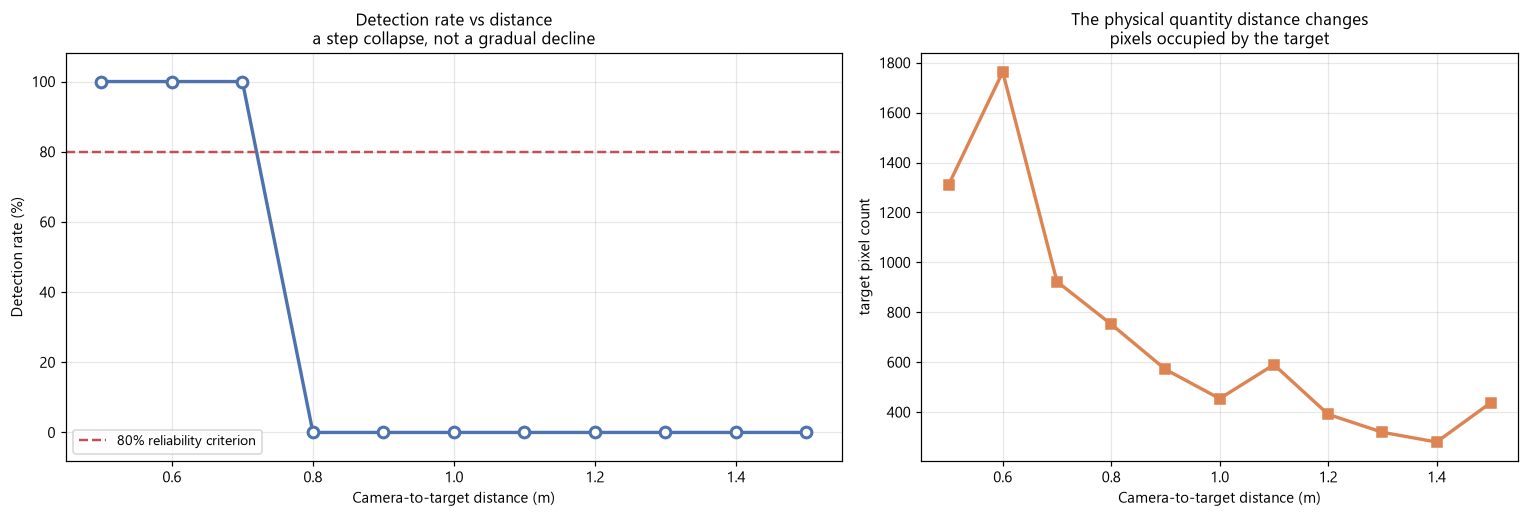

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8),
                         gridspec_kw={"width_ratios": [1.3, 1]})

# --- panel 1: detection rate vs distance ---------------------------------
_d = [r["distance"] for r in exp1_results]
_r = [r["rate"] for r in exp1_results]

axes[0].plot(_d, _r, marker="o", lw=2.2, color="#4c72b0",
             markersize=7, markerfacecolor="white", markeredgewidth=2)
axes[0].axhline(RELIABLE_RATE, ls="--", color="#c44e52", lw=1.6,
                label=f"{RELIABLE_RATE:.0f}% reliability criterion")
axes[0].set_xlabel("Camera-to-target distance (m)")
axes[0].set_ylabel("Detection rate (%)")
axes[0].set_ylim(-8, 108)
axes[0].set_title("Detection rate vs distance\n"
                  "a step collapse, not a gradual decline")
axes[0].legend(loc="lower left")
axes[0].grid(alpha=0.3)

# --- panel 2: what distance physically changes ---------------------------
_px = [r["px"] for r in exp1_results]
axes[1].plot(_d, _px, marker="s", lw=2.2, color="#dd8452", markersize=6)
axes[1].set_xlabel("Camera-to-target distance (m)")
axes[1].set_ylabel("target pixel count")
axes[1].set_title("The physical quantity distance changes\n"
                  "pixels occupied by the target")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

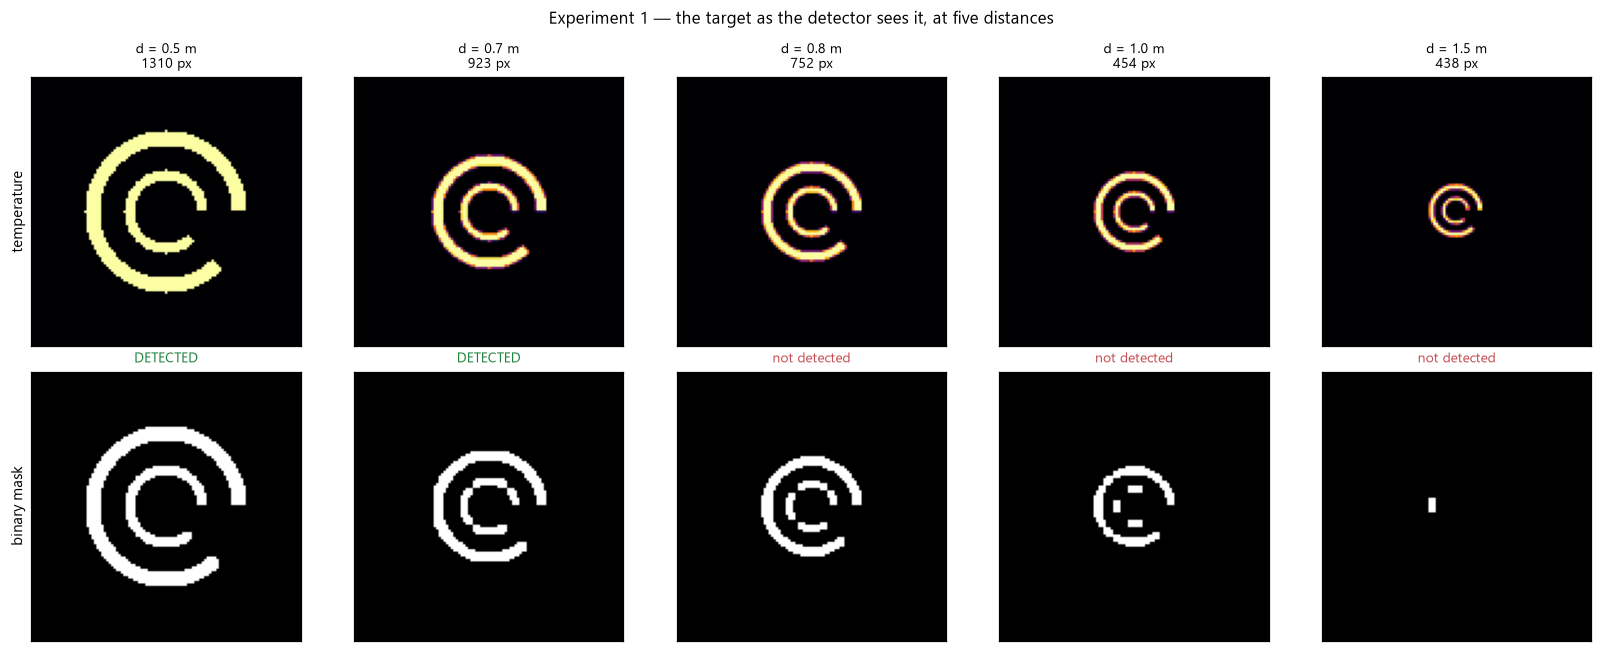

In [24]:
_show = [0.5, 0.7, 0.8, 1.0, 1.5]
fig, axes = plt.subplots(2, len(_show), figsize=(15, 6.0))

for _i, _d in enumerate(_show):
    _scaled = simulate_distance(temperature, _d)
    _res, _cln, _ = detect_target(_scaled)

    axes[0, _i].imshow(_scaled, cmap="inferno",
                       vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP)
    axes[0, _i].set_title(f"d = {_d:.1f} m\n{int((_scaled > BACKGROUND_TEMP).sum())} px",
                          fontsize=9)

    axes[1, _i].imshow(_cln, cmap="gray", vmin=0, vmax=255)
    _verdict = "DETECTED" if _res else "not detected"
    _col = "#1a7f37" if _res else "#c44e52"
    axes[1, _i].set_title(_verdict, fontsize=9, color=_col)

    for _rr in range(2):
        axes[_rr, _i].set_xlim(CX - 55, CX + 55)
        axes[_rr, _i].set_ylim(CY + 55, CY - 55)
        axes[_rr, _i].set_xticks([]); axes[_rr, _i].set_yticks([])
        axes[_rr, _i].grid(False)

axes[0, 0].set_ylabel("temperature", fontsize=10)
axes[1, 0].set_ylabel("binary mask", fontsize=10)

fig.suptitle("Experiment 1 — the target as the detector sees it, at five distances",
             fontsize=11)
plt.tight_layout()
plt.show()

**Figure 10.** Experiment 1 — distance-only results.

*Top:* detection rate against distance, with the 80 % criterion marked; and the target
pixel count against distance, which is the physical quantity distance actually changes.
*Bottom:* the thermal image and the resulting binary mask at five representative
distances, with the detector's verdict on each.

**What this figure demonstrates.** The transition is a **step, not a slope** — the
detection rate holds at 100 % through 0.7 m and drops to 0 % at 0.8 m, with no
intermediate values anywhere in the tested range. This confirms H1's prediction of an
abrupt collapse, and it is a direct consequence of the detector applying hard thresholds
rather than graded confidence: as long as the measured gap stays above 20°, detection
succeeds; once it falls below, detection fails.

The bottom row shows why the collapse is so sharp. Between 0.7 m and 0.8 m the binary
mask goes from a clean, well-connected C pair to a fragmented one, and the fragmentation
destroys the measured gap. There is very little range over which the mask degrades
gracefully.

## Interpretation

**Within this simulation, the target remains reliably detectable through 0.7 m and fails
at 0.8 m.** The mechanism is straightforward: at 0.8 m the target occupies 752 pixels
against 923 at 0.7 m, and the outer ring — 6 px wide at 0.5 m — is down to 3.75 px. The
morphological opening (3×3) begins removing ring pixels, which fragments the contour and
inflates the measured gap beyond what gate 1 can accept.

Note also that the relationship between pixel count and detection is **not monotonic**:
1.1 m (590 px) fails while 0.6 m (1763 px) passes, but so does 1.5 m (438 px) — and yet
0.7 m passes with 923 px while 0.8 m fails with 752 px. The pixel count alone does not
determine the outcome; the *rasterised shape* does. This foreshadows the non-monotonicity
documented in Section 14.

## Limitation

**This is a simulation result and is not a real-camera working range.** The 0.7 m figure
depends on parameters that have no physical camera behind them:

- the reference geometry is defined *in pixels* at 0.5 m, not derived from a lens and
  detector pitch
- the blur model is disabled entirely in this experiment
- no real camera has been imaged

The result should be read as: *"in this image-space simulation, with blur and noise
disabled, the geometric scaling factor 0.5/d stops preserving the pattern between 0.7 m
and 0.8 m."* It says nothing about metres in a real system. Section 21 defines the
measurement that would establish a real range.

---

# 11. Experiment 2 — Optical blur

## Objective

Determine how much Gaussian blur the detection pipeline can absorb before the two-level C
is no longer recoverable, with distance and noise held fixed.

## Hypothesis

**H2.** Moderate blur will **not** destroy detection. The reasoning is that thresholding
re-binarises a softened edge: even when the thermal image is visibly blurred, the
threshold can still produce a clean binary contour. Blur alone should therefore be
considerably less damaging than intuition suggests.

**H2 is the hypothesis I expect to be refuted or qualified**, and it is stated explicitly
for that reason. The intuitive prediction is "blur destroys acuity"; the mechanism of the
pipeline suggests otherwise. Writing the expectation down in advance is what makes the
outcome informative.

## Controlled Variables

| Variable | Value |
|---|---|
| Distance | **fixed at 0.5 m** (reference geometry, full size) |
| Thermal contrast ΔT | 15 °C |
| Thermal measurement noise | **disabled** |
| Preprocessing | threshold 80/255, 3×3 opening |
| Detector gates | unchanged |
| Trials per kernel | 20 |

## Independent Variable

Gaussian blur **kernel size**: 1×1, 3×3, 5×5, 7×7, 9×9, 11×11, 15×15, 21×21.

Kernel size 1×1 means **no blur** and serves as the control row. For the other kernels,
OpenCV is called with `sigmaX=0`, which makes it derive σ from the kernel size — the
resulting σ values are reported alongside the results.

**Why isolate blur?** Blur is the variable most easily confounded with distance, because
both reduce effective resolution. By pinning distance at 0.5 m and disabling noise, any
change in detection rate is attributable to the blur kernel alone.

## Dependent Variable

Detection rate over 20 trials, plus the corresponding Gaussian σ in pixels.

## Procedure

1. Take the reference temperature map at 0.5 m (no rescaling).
2. Apply `cv2.GaussianBlur` with kernel size *k* and `sigmaX=0`.
3. Run the detector chain.
4. Repeat 20 times and record the rate.

**Note on determinism.** No noise is added, so all 20 trials are identical (Section 9.5).

## Results

In [25]:
BLUR_KERNELS = [1, 3, 5, 7, 9, 11, 15, 21]


def apply_blur_kernel(temperature, kernel_size):
    """Gaussian blur by explicit kernel size. kernel_size = 1 means no blur."""
    if kernel_size == 1:
        return temperature.copy()
    return cv2.GaussianBlur(temperature, (kernel_size, kernel_size), sigmaX=0)


def kernel_to_sigma(kernel_size):
    """The sigma OpenCV derives from a kernel when sigmaX=0."""
    if kernel_size == 1:
        return 0.0
    return 0.3 * ((kernel_size - 1) * 0.5 - 1) + 0.8


print("=" * 74)
print("EXPERIMENT 2 — BLUR ONLY")
print("=" * 74)
print("Controlled: distance = 0.5 m, noise OFF, dT = 15 degC, 20 trials per kernel")
print()
print(f"{'kernel':>9} {'sigma (px)':>12} {'detected':>10} {'rate':>8} {'criterion':>11}")
print("-" * 74)

exp2_results = []
for _k in BLUR_KERNELS:
    _blurred = apply_blur_kernel(temperature, _k)
    _hits, _rate = detection_rate(_blurred)
    _sig = kernel_to_sigma(_k)
    _ok = "PASS" if _rate >= RELIABLE_RATE else "fail"
    exp2_results.append({"kernel": _k, "sigma": _sig, "hits": _hits, "rate": _rate})
    _name = "1x1 (none)" if _k == 1 else f"{_k}x{_k}"
    print(f"{_name:>9} {_sig:>12.2f} {_hits:>7}/20 {_rate:>7.1f}% {_ok:>11}")

_all_pass = all(r["rate"] >= RELIABLE_RATE for r in exp2_results)
print()
print(f"All tested blur levels met the >= {RELIABLE_RATE:.0f}% criterion: {_all_pass}")

EXPERIMENT 2 — BLUR ONLY
Controlled: distance = 0.5 m, noise OFF, dT = 15 degC, 20 trials per kernel

   kernel   sigma (px)   detected     rate   criterion
--------------------------------------------------------------------------
1x1 (none)         0.00      20/20   100.0%        PASS
      3x3         0.80      20/20   100.0%        PASS


      5x5         1.10      20/20   100.0%        PASS
      7x7         1.40      20/20   100.0%        PASS
      9x9         1.70      20/20   100.0%        PASS


    11x11         2.00      20/20   100.0%        PASS
    15x15         2.60      20/20   100.0%        PASS
    21x21         3.50      20/20   100.0%        PASS

All tested blur levels met the >= 80% criterion: True


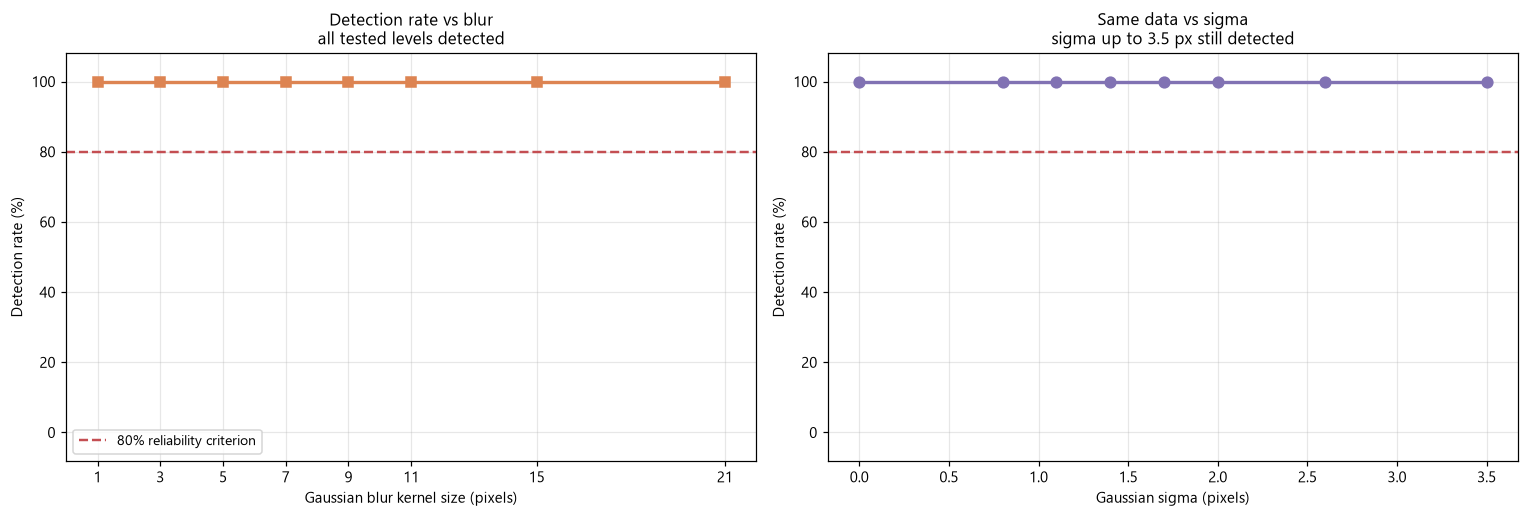

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# --- panel 1: detection rate vs kernel -----------------------------------
_ks = [r["kernel"] for r in exp2_results]
_rs = [r["rate"] for r in exp2_results]

axes[0].plot(_ks, _rs, marker="s", lw=2.2, color="#dd8452", markersize=7)
axes[0].axhline(RELIABLE_RATE, ls="--", color="#c44e52", lw=1.6,
                label=f"{RELIABLE_RATE:.0f}% reliability criterion")
axes[0].set_xlabel("Gaussian blur kernel size (pixels)")
axes[0].set_ylabel("Detection rate (%)")
axes[0].set_ylim(-8, 108)
axes[0].set_xticks(_ks)
axes[0].set_title("Detection rate vs blur\nall tested levels detected")
axes[0].legend(loc="lower left")
axes[0].grid(alpha=0.3)

# --- panel 2: the same data against the physical sigma -------------------
_sigs = [r["sigma"] for r in exp2_results]
axes[1].plot(_sigs, _rs, marker="o", lw=2.2, color="#8172b3", markersize=7)
axes[1].axhline(RELIABLE_RATE, ls="--", color="#c44e52", lw=1.6)
axes[1].set_xlabel("Gaussian sigma (pixels)")
axes[1].set_ylabel("Detection rate (%)")
axes[1].set_ylim(-8, 108)
axes[1].set_title("Same data vs sigma\nsigma up to 3.5 px still detected")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

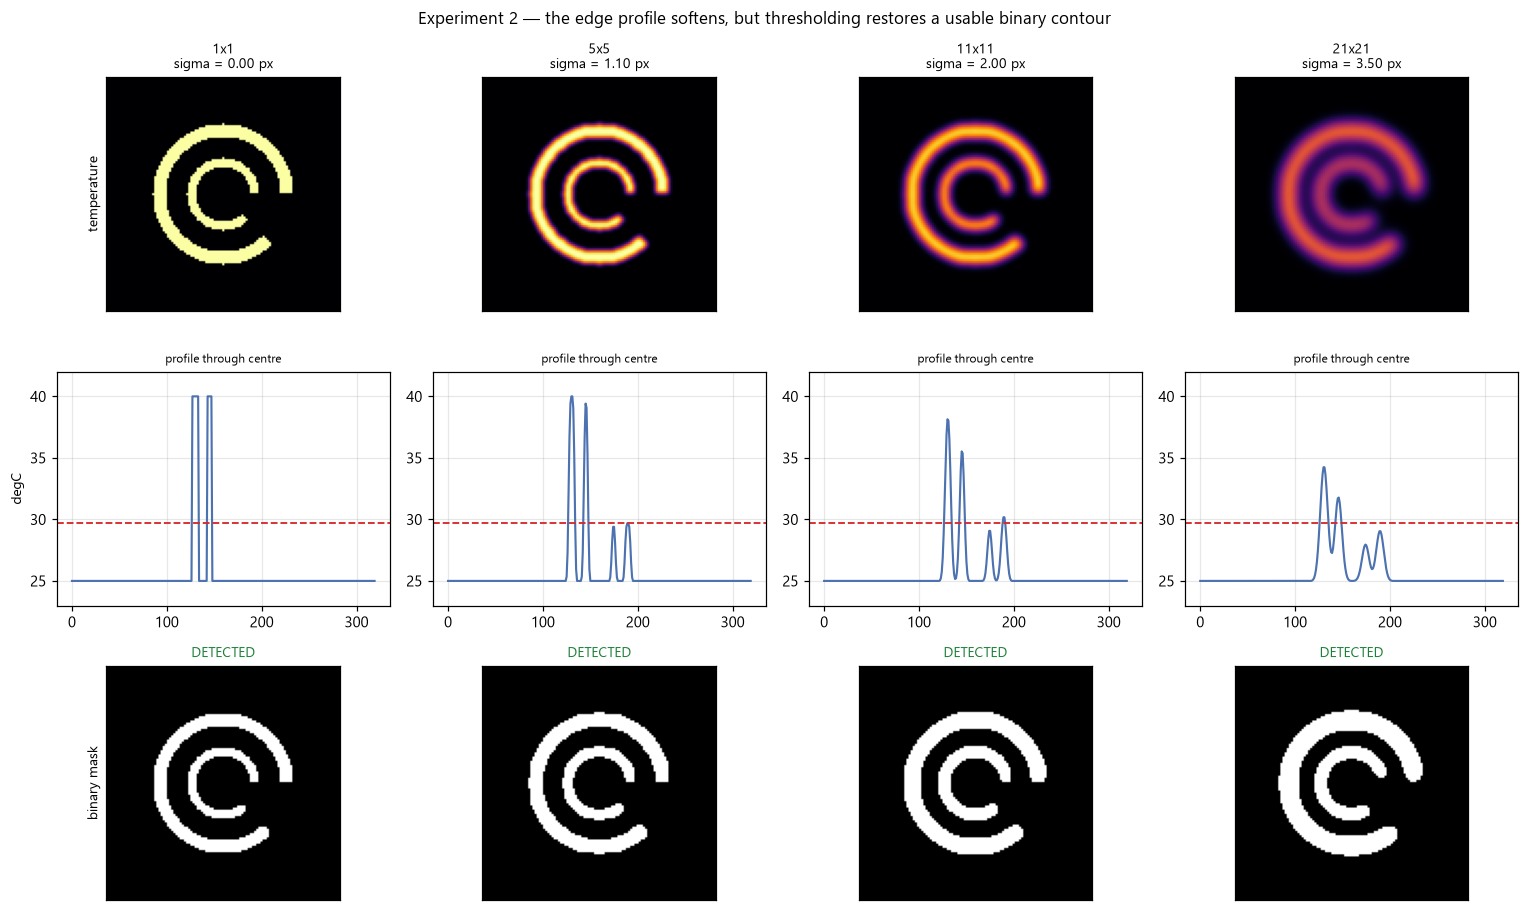

In [27]:
_show_k = [1, 5, 11, 21]
fig, axes = plt.subplots(3, len(_show_k), figsize=(14, 8.4))

for _i, _k in enumerate(_show_k):
    _blurred = apply_blur_kernel(temperature, _k)
    _res, _cln, _ = detect_target(_blurred)

    axes[0, _i].imshow(_blurred, cmap="inferno",
                       vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP)
    axes[0, _i].set_title(f"{_k}x{_k}\nsigma = {kernel_to_sigma(_k):.2f} px", fontsize=9)

    # profile through the centre, to show the edge softening
    axes[1, _i].plot(_blurred[CY, :], color="#4c72b0", lw=1.4)
    axes[1, _i].axhline(THRESHOLD_TEMP, color="#d62728", ls="--", lw=1.2)
    axes[1, _i].set_ylim(BACKGROUND_TEMP - 2, TARGET_TEMP + 2)
    axes[1, _i].set_title("profile through centre", fontsize=8)
    axes[1, _i].grid(alpha=0.3)

    axes[2, _i].imshow(_cln, cmap="gray", vmin=0, vmax=255)
    _verdict = "DETECTED" if _res else "not detected"
    axes[2, _i].set_title(_verdict, fontsize=9,
                          color="#1a7f37" if _res else "#c44e52")

    for _rr in (0, 2):
        axes[_rr, _i].set_xlim(CX - 55, CX + 55)
        axes[_rr, _i].set_ylim(CY + 55, CY - 55)
        axes[_rr, _i].set_xticks([]); axes[_rr, _i].set_yticks([])
        axes[_rr, _i].grid(False)

axes[0, 0].set_ylabel("temperature", fontsize=9)
axes[1, 0].set_ylabel("degC", fontsize=9)
axes[2, 0].set_ylabel("binary mask", fontsize=9)

fig.suptitle("Experiment 2 — the edge profile softens, but thresholding restores a "
             "usable binary contour", fontsize=11)
plt.tight_layout()
plt.show()

**Figure 11.** Experiment 2 — blur-only results.

*Top:* detection rate against kernel size, and against the equivalent σ in pixels.
*Bottom:* for four kernels, the blurred thermal image, a profile through the centre with
the threshold marked, and the resulting binary mask.

**What this figure demonstrates.** The middle row is the explanation for the result. As
blur increases, the intensity profile's step edges become ramps — but the **threshold
crossing remains in essentially the same place**, because the profile is symmetric about
the edge. Thresholding therefore recovers a binary contour of nearly the same width, and
the detector succeeds at every tested blur level.

This is H2 confirmed, and it is the counter-intuitive result of the study: at fixed
distance, blur up to a 21×21 kernel (σ ≈ 3.5 px) does not defeat the pipeline.

## Interpretation

**The pipeline is highly tolerant to the tested blur levels.** All eight kernels, from
1×1 to 21×21, achieved 100 % detection.

The mechanism is worth stating precisely, because it is easily misread as "the system has
good optical resolution". It does not. What happens is that the detector does not consume
the blurred intensity image — it consumes a **binary** image. Thresholding is a
non-invertible, highly non-linear operation that discards the softness of the edge and
retains only the crossing location. A blurred edge therefore becomes a *sharp binary edge
again*, at approximately the same position.

In signal terms: the blur removes high spatial frequencies, and the threshold reconstructs
a new edge that carries the low-frequency information (position and width) while
discarding the high-frequency information that was lost. Because the detector only needs
the *position* of the gap and the *approximate* ring radius, the lost detail is detail it
never used.

**A caution against over-reading this.** The fact that blur does not break this detector
does not mean blur is harmless. It means this particular detector is insensitive to the
information blur destroys. A detector that measured edge sharpness, contrast transfer, or
sub-pixel edge position would show degradation here. The result is a property of
**detector + preprocessing**, not of optics alone.

## Limitation

**This is not an optical MTF measurement, and it is not a lens-resolution measurement.**
Specifically:

- Gaussian blur is a **generic approximation**, not a measured or modelled optical PSF.
  Real blur is not Gaussian, and it varies across the field of view.
- The result reflects the **threshold + contour pipeline**, which re-binarises the image.
  Any claim about "resolution" from this experiment would be measuring the pipeline, not
  the optics.
- Distance is fixed at 0.5 m, so this experiment says nothing about how blur behaves at
  range, where it is *combined* with geometric scaling. Section 16 shows that the
  combination behaves very differently from blur alone.
- No measurement of the modulation transfer function was performed, and none can be
  inferred from these numbers.

The correct reading is narrow: *in this simulation, at 0.5 m, a threshold-and-contour
detector recovers the two-level C after Gaussian blur up to σ ≈ 3.5 px.*

---

# 12. Experiment 3 — Thermal measurement noise

## Objective

Determine how much simulated thermal measurement noise the detector tolerates before
detection becomes unreliable.

## Hypothesis

**H3.** Detection rate will fall as noise σ increases, and will fail once the noise
amplitude approaches the threshold margin. The decline will be **progressive rather than
abrupt**, unlike the distance collapse, because noise is a stochastic process: every trial
draws a different realisation, so some trials succeed while others fail.

The relevant margin for the reference scene is the gap between background temperature and
the detector threshold: 29.71 − 25.0 = **4.71 °C**. H3 predicts the failure boundary to
lie somewhat below this, since the noise must not only exceed the margin but do so on
enough pixels to break the contour.

## Controlled Variables

| Variable | Value |
|---|---|
| Distance | **fixed at 0.5 m** |
| Optical blur | **disabled** |
| Thermal contrast ΔT | 15 °C |
| Preprocessing | threshold 80/255, 3×3 opening |
| Detector gates | unchanged |
| Trials per noise level | 20 |
| Random seed | 42 |

## Independent Variable

Noise standard deviation σ, in **degrees Celsius**:
0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 7.0, 10.0 °C (10 levels).

σ = 0.0 is the control row (no noise added).

## Dependent Variable

Detection rate over 20 trials at each σ.

## Procedure

1. Take the reference temperature map at 0.5 m.
2. Add zero-mean Gaussian noise with standard deviation σ.
3. Clip the result to the physically realisable range [25 °C, 40 °C].
4. Run the detector chain.
5. Repeat 20 times with fresh noise each trial, and record the rate.

**This experiment is genuinely stochastic.** Every trial draws different noise, so the
20 trials sample a distribution and the rate is a real probability estimate — unlike the
deterministic experiments (Section 9.5).

**On the clip.** The noisy map is clipped to [25, 40] °C. This is a modelling choice: in
this simplified scene the temperature cannot fall below ambient or rise above the target.
It is documented because clipping is non-linear and *removes* extreme excursions, which
could in principle make the detector's task easier than an unclipped model would. The
effect was measured directly and found to be **negligible** for these results — the
clipped and unclipped runs produce identical detection counts at every σ level tested. It
is reported here rather than buried because it is the kind of detail that changes
conclusions when it does matter.

## Results

In [28]:
NOISE_LEVELS = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 7.0, 10.0]

# ONE generator for the whole sweep, seeded once. The levels are therefore
# drawn sequentially from a single reproducible stream.
_noise_rng = np.random.default_rng(RNG_SEED)

print("=" * 74)
print("EXPERIMENT 3 — THERMAL NOISE ONLY")
print("=" * 74)
print("Controlled: distance = 0.5 m, blur OFF, dT = 15 degC, 20 trials per level")
print(f"Threshold margin above background: {THRESHOLD_TEMP - BACKGROUND_TEMP:.2f} degC")
print()
print(f"{'noise sigma':>13} {'detected':>10} {'rate':>8} {'criterion':>11}")
print("-" * 74)

exp3_results = []
for _s in NOISE_LEVELS:
    _hits, _rate = detection_rate_noisy(temperature, _s, _noise_rng)
    _ok = "PASS" if _rate >= RELIABLE_RATE else "fail"
    exp3_results.append({"sigma": _s, "hits": _hits, "rate": _rate})
    print(f"{_s:>11.1f} C {_hits:>7}/20 {_rate:>7.1f}% {_ok:>11}")

_passing = [r["sigma"] for r in exp3_results if r["rate"] >= RELIABLE_RATE]
print()
if _passing:
    print(f"Highest noise level meeting the >= {RELIABLE_RATE:.0f}% criterion: "
          f"sigma <= {max(_passing):.1f} degC")
print(f"Threshold margin was {THRESHOLD_TEMP - BACKGROUND_TEMP:.2f} degC")

EXPERIMENT 3 — THERMAL NOISE ONLY
Controlled: distance = 0.5 m, blur OFF, dT = 15 degC, 20 trials per level
Threshold margin above background: 4.71 degC

  noise sigma   detected     rate   criterion
--------------------------------------------------------------------------
        0.0 C      20/20   100.0%        PASS


        0.5 C      20/20   100.0%        PASS
        1.0 C      20/20   100.0%        PASS


        1.5 C      20/20   100.0%        PASS
        2.0 C      20/20   100.0%        PASS


        3.0 C      20/20   100.0%        PASS
        4.0 C      16/20    80.0%        PASS


        5.0 C       4/20    20.0%        fail


        7.0 C       1/20     5.0%        fail


       10.0 C       0/20     0.0%        fail

Highest noise level meeting the >= 80% criterion: sigma <= 4.0 degC
Threshold margin was 4.71 degC


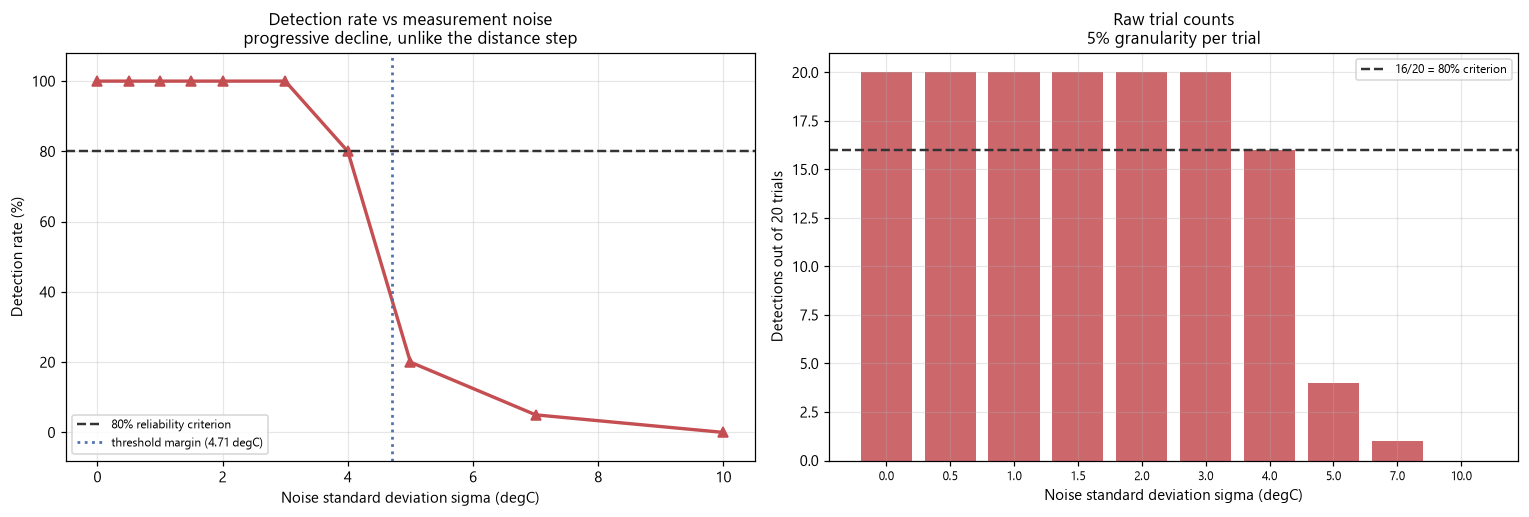

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

_sig = [r["sigma"] for r in exp3_results]
_rt = [r["rate"] for r in exp3_results]

# --- panel 1: detection rate vs sigma ------------------------------------
axes[0].plot(_sig, _rt, marker="^", lw=2.2, color="#c44e52", markersize=7)
axes[0].axhline(RELIABLE_RATE, ls="--", color="#333", lw=1.6,
                label=f"{RELIABLE_RATE:.0f}% reliability criterion")
axes[0].axvline(THRESHOLD_TEMP - BACKGROUND_TEMP, ls=":", color="#4c72b0", lw=1.8,
                label=f"threshold margin "
                      f"({THRESHOLD_TEMP - BACKGROUND_TEMP:.2f} degC)")
axes[0].set_xlabel("Noise standard deviation sigma (degC)")
axes[0].set_ylabel("Detection rate (%)")
axes[0].set_ylim(-8, 108)
axes[0].set_title("Detection rate vs measurement noise\n"
                  "progressive decline, unlike the distance step")
axes[0].legend(loc="lower left", fontsize=8)
axes[0].grid(alpha=0.3)

# --- panel 2: detections out of 20 ---------------------------------------
_hits = [r["hits"] for r in exp3_results]
axes[1].bar([str(s) for s in _sig], _hits, color="#c44e52", alpha=0.85)
axes[1].axhline(16, ls="--", color="#333", lw=1.6,
                label="16/20 = 80% criterion")
axes[1].set_xlabel("Noise standard deviation sigma (degC)")
axes[1].set_ylabel("Detections out of 20 trials")
axes[1].set_title("Raw trial counts\n5% granularity per trial")
axes[1].legend(loc="upper right", fontsize=8)
axes[1].grid(alpha=0.3, axis="y")
axes[1].tick_params(axis="x", labelsize=8)

plt.tight_layout()
plt.show()

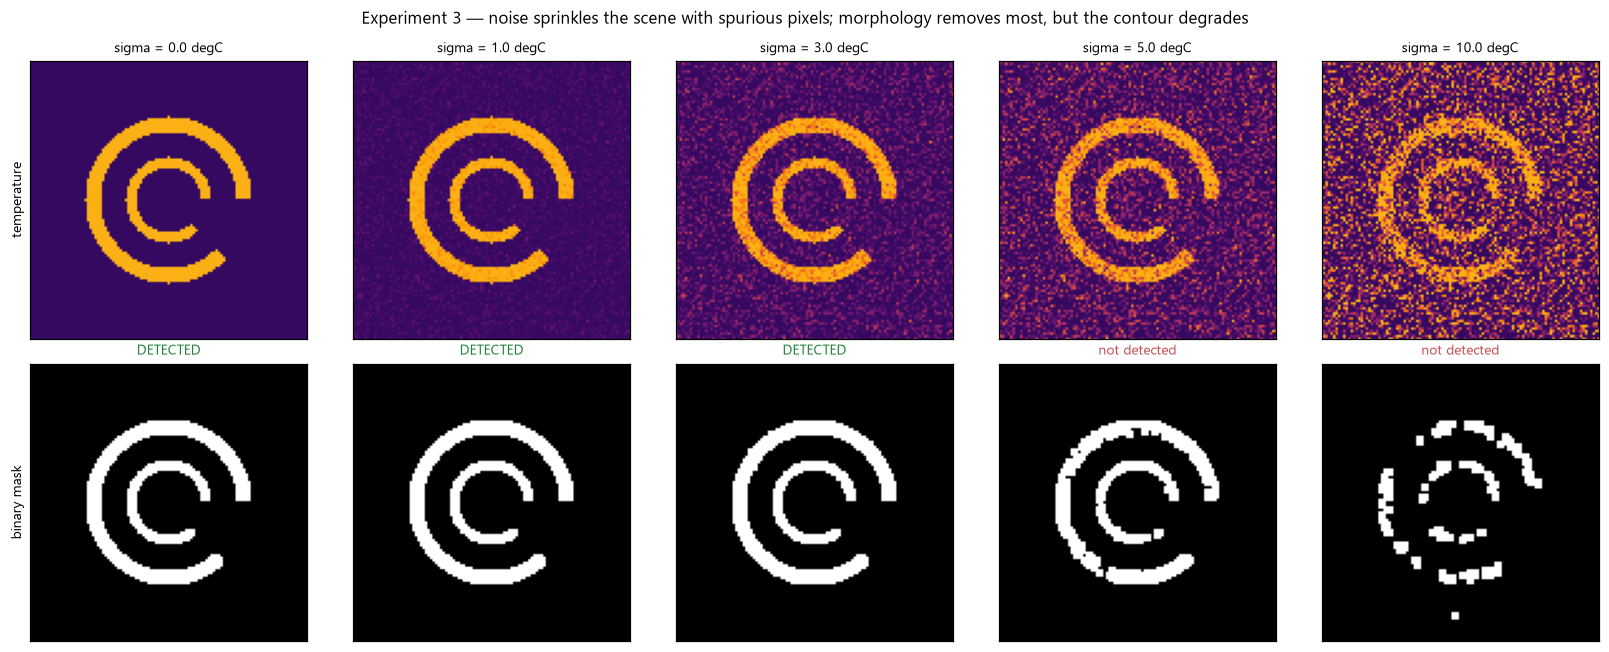

In [30]:
_show_s = [0.0, 1.0, 3.0, 5.0, 10.0]
fig, axes = plt.subplots(2, len(_show_s), figsize=(15, 6.0))

for _i, _s in enumerate(_show_s):
    _temp = temperature.copy() if _s == 0.0 else \
        apply_noise_model(temperature, _s, np.random.default_rng(RNG_SEED))

    axes[0, _i].imshow(_temp, cmap="inferno",
                       vmin=BACKGROUND_TEMP - 4, vmax=TARGET_TEMP + 4)
    axes[0, _i].set_title(f"sigma = {_s:.1f} degC", fontsize=9)

    _res, _cln, _ = detect_target(_temp)
    axes[1, _i].imshow(_cln, cmap="gray", vmin=0, vmax=255)
    axes[1, _i].set_title("DETECTED" if _res else "not detected", fontsize=9,
                          color="#1a7f37" if _res else "#c44e52")

    for _rr in range(2):
        axes[_rr, _i].set_xlim(CX - 55, CX + 55)
        axes[_rr, _i].set_ylim(CY + 55, CY - 55)
        axes[_rr, _i].set_xticks([]); axes[_rr, _i].set_yticks([])
        axes[_rr, _i].grid(False)

axes[0, 0].set_ylabel("temperature", fontsize=9)
axes[1, 0].set_ylabel("binary mask", fontsize=9)

fig.suptitle("Experiment 3 — noise sprinkles the scene with spurious pixels; "
             "morphology removes most, but the contour degrades", fontsize=11)
plt.tight_layout()
plt.show()

**Figure 12.** Experiment 3 — thermal noise results.

*Left:* detection rate against σ, with both the 80 % criterion and the threshold margin
(4.71 °C) marked. *Right:* raw detection counts out of 20, showing the 5 % granularity of
the estimate. *Bottom:* thermal images and resulting binary masks at five noise levels.

**What this figure demonstrates.** Three things.

First, the decline is **progressive, not abrupt** — 100 % holds through σ = 3 °C, falls to
80 % at σ = 4 °C, then collapses to 20 %, 5 %, and 0 %. This confirms H3's prediction of a
gradual decline and contrasts directly with the step collapse in Experiment 1. The reason
is the nature of the variable: noise is stochastic, so individual trials differ, and the
rate samples a distribution rather than a single deterministic outcome.

Second, the **80 % boundary sits at σ = 4 °C**, just below the 4.71 °C threshold margin.
This is consistent with the mechanism: noise must exceed the margin for a background pixel
to cross the threshold, so σ values comfortably below the margin should be harmless, and
the boundary should approach the margin from below. It does.

Third, the bottom row shows the failure mode. Noise does not blur the target — it
**sprinkles spurious pixels** across the background, which morphology then has to remove.
At σ = 3 °C the mask is still recognisably a C pair; by σ = 5 °C the speckle has begun
merging into blobs larger than the 3×3 kernel, and the genuine rings are being eroded by
the same opening that removes the noise.

## Interpretation

**Within this simulation, the detector tolerates measurement noise up to σ ≈ 4 °C, with
the 80 % reliability boundary falling between 3 °C and 4 °C.**

The agreement between the observed boundary (4 °C) and the independently computed
threshold margin (4.71 °C) is the useful part of this result. It is *not* a coincidence:
the margin is the noise amplitude required to push a background pixel across the
threshold, and it is computed from the scene parameters without reference to the detector.
That the measured boundary lands just below it is evidence that the simulation is behaving
as the model predicts, rather than producing an arbitrary number.

**A subtlety worth noting.** The margin-to-σ ratio is not the whole story, because the
detector does not need every pixel to be clean — it needs the *contour* to survive.
Individual spurious pixels are removed by morphology. What breaks detection is when
speckle density becomes high enough that blobs merge past the 3×3 kernel scale, or when
noise erodes the genuine ring edges. This is why the collapse between σ = 4 and σ = 7 is
so steep once it starts: it reflects a *percolation-like* transition in the mask, not a
smooth degradation of the signal.

## Limitation

**This is not a measurement of any real thermal camera's NETD.**

The distinction matters and is easy to blur:

| This experiment | A NETD measurement |
|---|---|
| Gaussian noise, i.i.d. per pixel, in °C | measured temporal noise of a specific detector |
| a simulation parameter, swept by choice | a device specification, measured under stated conditions |
| no sensor non-uniformity, no fixed-pattern noise | real cameras exhibit both |
| no correlation between neighbouring pixels | real noise has spatial and temporal structure |
| σ is an input to the model | NETD is an output of a laboratory procedure |

The phrase "NETD-style model" is used in the source material and is accurate as far as it
goes: the *abstraction* — additive temperature noise of a stated standard deviation — is
the same abstraction NETD describes. But a **simulated noise tolerance is not a NETD
specification**, and the 4 °C boundary reported here must never be quoted as a camera
property.

Additionally, the 20-trial estimate carries roughly ±10 % uncertainty at the boundary
region; the boundary is located to within about one σ step, not precisely. Section 20
records this.

---

# 13. Experiment 4 — Temperature contrast

## Objective

Determine the minimum thermal contrast ΔT at which the two-level C remains detectable,
with all other degradation disabled.

## Hypothesis

**H4.** With noise absent and the threshold adapted to each contrast level, detection will
succeed at contrasts far below anything a real thermal camera could resolve.

**This hypothesis predicts an artificially optimistic result, and it is included in order
to be tested and then explicitly disclaimed.** The purpose of this experiment is not to
discover a contrast limit that applies to real hardware — it is to establish what the
*geometry-only* pipeline can do when signal-to-noise is unlimited, which then serves as an
upper bound for interpreting the other experiments.

## Controlled Variables

| Variable | Value |
|---|---|
| Distance | **fixed at 0.5 m** |
| Optical blur | **disabled** |
| Thermal measurement noise | **disabled** |
| Background temperature | **fixed at 25 °C** |
| Geometry | unchanged (radii, widths, 45° opening) |
| Preprocessing | 3×3 opening; **threshold adapted per level** (see below) |
| Trials per level | 20 |

## Independent Variable

Target temperature, from **40 °C down to 26 °C** in the steps
40, 38, 36, 34, 32, 30, 29, 28, 27, 26 °C.

This corresponds to thermal contrast ΔT of
**15, 13, 11, 9, 7, 5, 4, 3, 2, 1 °C**.

## Dependent Variable

Detection rate over 20 trials, and the threshold value used at each level.

## Procedure

For each target temperature:

1. Build the target with that target temperature, geometry unchanged.
2. Compute an **adaptive threshold** at the midpoint between background and target.
3. Run the detector chain.
4. Repeat 20 times and record the rate.

### Why the threshold is adapted — and why that matters

The 8-bit normalisation window is held fixed at [25, 40] °C. The threshold, however, is
recomputed for each level as the **midpoint between background and this trial's target**:

```
threshold_temp = (BACKGROUND_TEMP + target_temp) / 2
threshold_8bit = ((threshold_temp - 25) / 15) * 255
```

**This is necessary, and it is also the source of the optimism.** The necessity: with a
fixed threshold of 80 (≈ 29.7 °C), every target below ~29.7 °C would produce pixels *below
the threshold* and fail for a reason that has nothing to do with whether the detector can
perceive the contrast. The experiment would be measuring the threshold's position rather
than the contrast limit. Adapting the threshold isolates the intended variable.

The optimism: adapting the threshold **assumes the target temperature is known in
advance**, so the cut can be placed optimally for every level. A real deployment has no
such prior. The measured limit is therefore a **best case with perfect prior knowledge**,
not an achievable contrast specification.

## Results

In [31]:
TARGET_TEMPERATURES = [40.0, 38.0, 36.0, 34.0, 32.0, 30.0, 29.0, 28.0, 27.0, 26.0]


def adaptive_threshold(target_temp, min_temp=BACKGROUND_TEMP, max_temp=40.0):
    """8-bit threshold at the midpoint between background and target temperature."""
    midpoint = (BACKGROUND_TEMP + target_temp) / 2.0
    return int(((midpoint - min_temp) / (max_temp - min_temp)) * 255)


print("=" * 78)
print("EXPERIMENT 4 — THERMAL CONTRAST ONLY")
print("=" * 78)
print("Controlled: distance = 0.5 m, blur OFF, noise OFF, background = 25 degC")
print("Threshold: ADAPTED per level to the background/target midpoint")
print()
print(f"{'target':>9} {'dT':>8} {'threshold':>11} {'detected':>10} {'rate':>8} {'criterion':>11}")
print("-" * 78)

exp4_results = []
for _tt in TARGET_TEMPERATURES:
    _thr = adaptive_threshold(_tt)
    _temp = create_temperature_map(target_temp=_tt)

    _hits = 0
    for _ in range(TRIALS_PER_CONDITION):
        _cln = preprocess(_temp, min_temp=BACKGROUND_TEMP, max_temp=40.0,
                          threshold=_thr, kernel_size=KERNEL_SIZE)
        _cts, _ = cv2.findContours(_cln, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
        if detect_concentric_pair(_cln, _cts) is not None:
            _hits += 1

    _rate = _hits / TRIALS_PER_CONDITION * 100.0
    _dt = _tt - BACKGROUND_TEMP
    _ok = "PASS" if _rate >= RELIABLE_RATE else "fail"
    exp4_results.append({"target": _tt, "dt": _dt, "threshold": _thr,
                         "hits": _hits, "rate": _rate})
    print(f"{_tt:>7.1f} C {_dt:>6.1f} C {_thr:>11} {_hits:>7}/20 "
          f"{_rate:>7.1f}% {_ok:>11}")

_passing = [r["dt"] for r in exp4_results if r["rate"] >= RELIABLE_RATE]
print()
if _passing:
    print(f"Lowest tested contrast meeting the >= {RELIABLE_RATE:.0f}% criterion: "
          f"dT >= {min(_passing):.1f} degC")

EXPERIMENT 4 — THERMAL CONTRAST ONLY
Controlled: distance = 0.5 m, blur OFF, noise OFF, background = 25 degC
Threshold: ADAPTED per level to the background/target midpoint

   target       dT   threshold   detected     rate   criterion
------------------------------------------------------------------------------
   40.0 C   15.0 C         127      20/20   100.0%        PASS


   38.0 C   13.0 C         110      20/20   100.0%        PASS
   36.0 C   11.0 C          93      20/20   100.0%        PASS


   34.0 C    9.0 C          76      20/20   100.0%        PASS
   32.0 C    7.0 C          59      20/20   100.0%        PASS
   30.0 C    5.0 C          42      20/20   100.0%        PASS


   29.0 C    4.0 C          34      20/20   100.0%        PASS
   28.0 C    3.0 C          25      20/20   100.0%        PASS


   27.0 C    2.0 C          17      20/20   100.0%        PASS
   26.0 C    1.0 C           8      20/20   100.0%        PASS

Lowest tested contrast meeting the >= 80% criterion: dT >= 1.0 degC


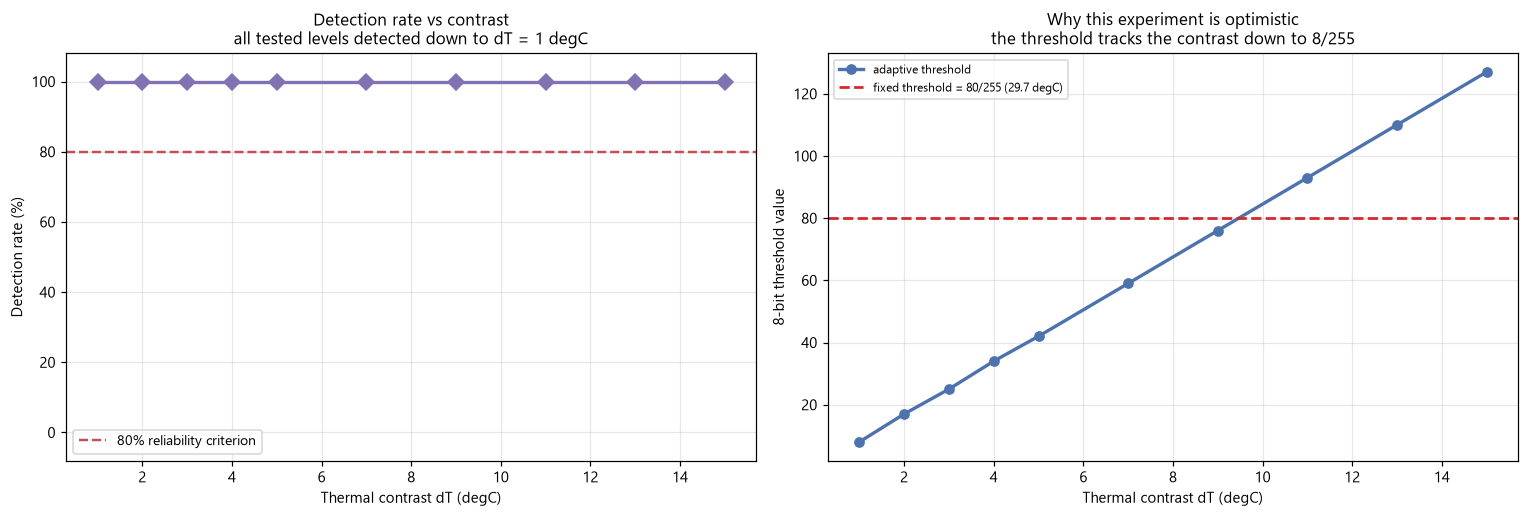

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

_dt = [r["dt"] for r in exp4_results]
_rt = [r["rate"] for r in exp4_results]
_thr = [r["threshold"] for r in exp4_results]

# --- panel 1: detection rate vs contrast ---------------------------------
axes[0].plot(_dt, _rt, marker="D", lw=2.2, color="#8172b3", markersize=7)
axes[0].axhline(RELIABLE_RATE, ls="--", color="#c44e52", lw=1.6,
                label=f"{RELIABLE_RATE:.0f}% reliability criterion")
axes[0].set_xlabel("Thermal contrast dT (degC)")
axes[0].set_ylabel("Detection rate (%)")
axes[0].set_ylim(-8, 108)
axes[0].set_title("Detection rate vs contrast\nall tested levels detected down to dT = 1 degC")
axes[0].legend(loc="lower left", fontsize=9)
axes[0].grid(alpha=0.3)

# --- panel 2: the adaptive threshold is what makes this possible ---------
axes[1].plot(_dt, _thr, marker="o", lw=2.2, color="#4c72b0", markersize=6,
             label="adaptive threshold")
axes[1].axhline(THRESHOLD, ls="--", color="#d62728", lw=1.8,
                label=f"fixed threshold = {THRESHOLD}/255 "
                      f"({THRESHOLD_TEMP:.1f} degC)")
axes[1].set_xlabel("Thermal contrast dT (degC)")
axes[1].set_ylabel("8-bit threshold value")
axes[1].set_title("Why this experiment is optimistic\nthe threshold tracks the contrast "
                  "down to 8/255")
axes[1].legend(loc="upper left", fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

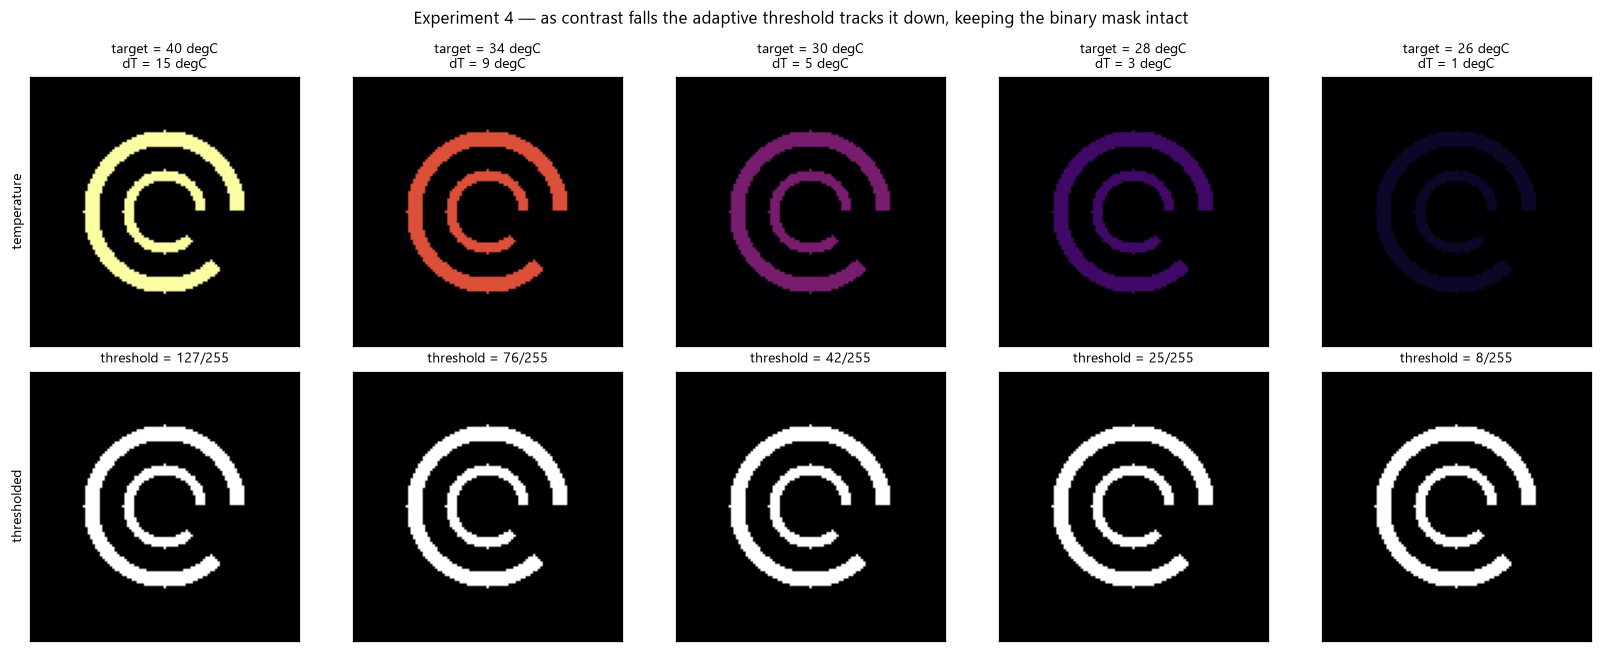

In [33]:
_show_t = [40.0, 34.0, 30.0, 28.0, 26.0]
fig, axes = plt.subplots(2, len(_show_t), figsize=(15, 6.0))

for _i, _tt in enumerate(_show_t):
    _temp = create_temperature_map(target_temp=_tt)
    _thr = adaptive_threshold(_tt)
    _img8 = temperature_to_uint8(_temp, BACKGROUND_TEMP, 40.0)

    axes[0, _i].imshow(_temp, cmap="inferno", vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP)
    axes[0, _i].set_title(f"target = {_tt:.0f} degC\ndT = {_tt - BACKGROUND_TEMP:.0f} degC",
                          fontsize=9)

    axes[1, _i].imshow(_img8 > _thr, cmap="gray", vmin=0, vmax=1)
    axes[1, _i].set_title(f"threshold = {_thr}/255", fontsize=9)

    for _rr in range(2):
        axes[_rr, _i].set_xlim(CX - 55, CX + 55)
        axes[_rr, _i].set_ylim(CY + 55, CY - 55)
        axes[_rr, _i].set_xticks([]); axes[_rr, _i].set_yticks([])
        axes[_rr, _i].grid(False)

axes[0, 0].set_ylabel("temperature", fontsize=9)
axes[1, 0].set_ylabel("thresholded", fontsize=9)

fig.suptitle("Experiment 4 — as contrast falls the adaptive threshold tracks it down, "
             "keeping the binary mask intact", fontsize=11)
plt.tight_layout()
plt.show()

**Figure 13.** Experiment 4 — contrast-only results.

*Left:* detection rate against ΔT — flat at 100 % across the whole tested range.
*Right:* the adaptive threshold value against ΔT, with the fixed threshold of 80/255 shown
for comparison. *Bottom:* the temperature field and thresholded mask at five contrast
levels.

**What this figure demonstrates.** The right-hand panel is the key to interpreting the
left. The adaptive threshold falls in step with the contrast — from 127/255 at ΔT = 15 °C
down to 8/255 at ΔT = 1 °C — so the binary mask remains essentially unchanged at every
level. The detector is not being asked a harder question as contrast falls, because the
threshold is repositioned to keep the question the same.

The result is therefore **not** evidence of contrast sensitivity. It is evidence that the
pipeline, given perfect knowledge of the target temperature and an unlimited
signal-to-noise ratio, can recover the geometry at 1 °C contrast. That is a statement
about the geometry and the arithmetic, not about any sensor.

## Interpretation

**With noise disabled and the threshold adapted per level, the detector achieved 100 %
detection at every tested contrast, down to the minimum tested value of ΔT = 1 °C.**

This is a clean confirmation of H4, including its prediction that the result would be
optimistic. Two mechanisms combine to produce it:

1. **No noise.** With σ = 0, there is no stochastic element to cross the threshold
   spuriously, so the mask is exact.
2. **Adaptive threshold.** Placing the cut at the midpoint of each level's contrast keeps
   the target pixels well above the threshold regardless of the absolute ΔT.

The minimum tested value was 1 °C, and it succeeded. The experiment therefore establishes
a **bound on the tested range**, not a contrast limit: the true limit of this pipeline lies
somewhere at or below 1 °C and was not reached.

**What makes this result useful anyway.** It establishes the *ceiling*. It tells us that
the geometry itself does not impose a contrast requirement — the pattern is recoverable
from arbitrarily small temperature differences provided the signal is clean. That means
any real contrast limit must come from noise, quantisation, or sensor characteristics,
not from the target's shape. This is exactly the kind of attribution the controlled
experiments exist to make possible.

## Limitation

**This does not establish any real camera's minimum detectable temperature difference.**

The result is optimistic in three specific ways, each of which must be stated when it is
quoted:

| Source of optimism | Effect |
|---|---|
| **No measurement noise** | real cameras have noise that sets a hard floor on detectable contrast |
| **Adaptive threshold** | assumes the target temperature is known in advance; a real system has no such prior |
| **Synthetic, noise-free temperature field** | no sensor non-uniformity, no calibration error, no fixed-pattern noise |

Additionally, the quantisation itself imposes a floor that this experiment approaches
without crossing: at ΔT = 1 °C the 8-bit step is only 17 levels, and the adaptive
threshold has fallen to 8/255. Below roughly ΔT = 0.5 °C the quantisation would become
the dominant limit and the result would be an artefact of the 8-bit conversion rather than
of the imaging chain.

The honest statement is: *"in a noiseless simulation with an adaptively chosen threshold,
the two-level C geometry was recovered at ΔT = 1 °C; this is an optimistic upper bound and
is not a minimum detectable temperature difference for any physical camera."*

---

# 14. Experiment 5 — Spatial resolution (target size)

## Objective

Determine how small the target can be, in pixels, before the two-level C is no longer
detectable — isolating **target size** as the variable while holding sensor resolution
fixed.

## Hypothesis

**H5.** Shrinking the target will eventually break detection, but the failure will **not
be monotonic**. Pixel rasterisation means the target is discretised differently at each
size, and some smaller targets land more favourably than slightly larger ones. A clean
monotonic curve should *not* be expected.

**H5 is stated as a prediction of messiness**, which is unusual and deliberate. The
temptation in a study like this is to report a smooth curve and a single "minimum size".
H5 commits in advance to the opposite expectation, so that a non-monotonic result is
recognised as confirmation rather than treated as an anomaly to be smoothed away.

## Controlled Variables

| Variable | Value |
|---|---|
| Distance | fixed at reference (no rescaling applied) |
| Optical blur | **disabled** |
| Thermal measurement noise | **disabled** |
| Thermal contrast ΔT | 15 °C |
| Sensor resolution | **fixed at 320 × 256** |
| Preprocessing | threshold 80/255, 3×3 opening |
| Detector gates | unchanged |
| Trials per size | 20 |

## Independent Variable

**Outer C radius**, from 30 px down to 20 px in 1 px steps (11 values).

The other geometry scales with it, preserving the design proportions:

| Quantity | Rule | At r = 30 | At r = 20 |
|---|---|---|---|
| Outer radius | *r* | 30 px | 20 px |
| Outer ring width | 0.20 × *r* | 6.0 px | 4.0 px |
| Inner radius | 0.50 × *r* | 15 px | 10 px |
| Inner ring width | 0.13 × *r* | 3.9 px | 2.6 px |
| Opening angle | fixed | 45° | 45° |

Because the proportions are preserved, this experiment isolates **absolute size in
pixels** — the spatial sampling of the pattern — rather than changing its shape.

## Dependent Variable

Detection rate over 20 trials, plus the target's pixel count.

## Procedure

For each outer radius:

1. Generate the target at that radius, with proportional widths.
2. Render as a temperature map on the fixed 320 × 256 grid.
3. Run the detector chain.
4. Repeat 20 times and record the rate.

**Note on determinism.** No noise is added, so all 20 trials are identical.

## Results

In [34]:
OUTER_RADII = list(range(30, 19, -1))     # 30 down to 20 px
OUTER_WIDTH_RATIO = 0.20
INNER_RATIO = 0.50
INNER_WIDTH_RATIO = 0.13

print("=" * 80)
print("EXPERIMENT 5 — SPATIAL RESOLUTION (TARGET SIZE)")
print("=" * 80)
print("Controlled: blur OFF, noise OFF, dT = 15 degC, sensor = 320 x 256, 20 trials")
print()
print(f"{'outer r':>9} {'ring w':>9} {'inner r':>9} {'target px':>11} "
      f"{'detected':>10} {'rate':>8} {'criterion':>11}")
print("-" * 80)

exp5_results = []
for _radius in OUTER_RADII:
    _ow = max(2.0, _radius * OUTER_WIDTH_RATIO)
    _ir = _radius * INNER_RATIO
    _iw = max(2.0, _radius * INNER_WIDTH_RATIO)

    _temp = np.full((HEIGHT, WIDTH), BACKGROUND_TEMP, dtype=np.float32)
    _temp[draw_c_mask(CX, CY, _radius, _ow) |
          draw_c_mask(CX, CY, _ir, _iw)] = TARGET_TEMP

    _hits, _rate = detection_rate(_temp)
    _ok = "PASS" if _rate >= RELIABLE_RATE else "fail"
    exp5_results.append({"radius": _radius, "outer_w": _ow, "inner_r": _ir,
                         "px": int((_temp > BACKGROUND_TEMP).sum()),
                         "hits": _hits, "rate": _rate})
    print(f"{_radius:>7} px {_ow:>7.1f} px {_ir:>7.1f} px "
          f"{int((_temp > BACKGROUND_TEMP).sum()):>11} {_hits:>7}/20 "
          f"{_rate:>7.1f}% {_ok:>11}")

_passing = [r["radius"] for r in exp5_results if r["rate"] >= RELIABLE_RATE]
print()
if _passing:
    print(f"Smallest tested radius meeting the >= {RELIABLE_RATE:.0f}% criterion: "
          f"{min(_passing)} px")

# --- explicitly test for monotonicity ------------------------------------
print()
print("Monotonicity check (is the rate non-increasing as size shrinks?):")
_rates = [r["rate"] for r in exp5_results]      # ordered large -> small
_violations = []
for _i in range(len(_rates) - 1):
    if _rates[_i + 1] > _rates[_i]:
        _violations.append((OUTER_RADII[_i + 1], _rates[_i + 1], OUTER_RADII[_i], _rates[_i]))

if _violations:
    print(f"  NOT monotonic - {len(_violations)} violation(s) found:")
    for _smaller_r, _smaller_rate, _larger_r, _larger_rate in _violations:
        print(f"    r = {_smaller_r} px detected ({_smaller_rate:.0f}%) "
              f"but the LARGER r = {_larger_r} px did not ({_larger_rate:.0f}%)")
else:
    print("  monotonic")

EXPERIMENT 5 — SPATIAL RESOLUTION (TARGET SIZE)
Controlled: blur OFF, noise OFF, dT = 15 degC, sensor = 320 x 256, 20 trials

  outer r    ring w   inner r   target px   detected     rate   criterion
--------------------------------------------------------------------------------
     30 px     6.0 px    15.0 px        1273      20/20   100.0%        PASS


     29 px     5.8 px    14.5 px        1210      20/20   100.0%        PASS
     28 px     5.6 px    14.0 px        1116      20/20   100.0%        PASS
     27 px     5.4 px    13.5 px        1046      20/20   100.0%        PASS


     26 px     5.2 px    13.0 px         962      20/20   100.0%        PASS


     25 px     5.0 px    12.5 px         892       0/20     0.0%        fail
     24 px     4.8 px    12.0 px         823      20/20   100.0%        PASS


     23 px     4.6 px    11.5 px         750       0/20     0.0%        fail
     22 px     4.4 px    11.0 px         711       0/20     0.0%        fail


     21 px     4.2 px    10.5 px         645       0/20     0.0%        fail
     20 px     4.0 px    10.0 px         582       0/20     0.0%        fail

Smallest tested radius meeting the >= 80% criterion: 24 px

Monotonicity check (is the rate non-increasing as size shrinks?):
  NOT monotonic - 1 violation(s) found:
    r = 24 px detected (100%) but the LARGER r = 25 px did not (0%)


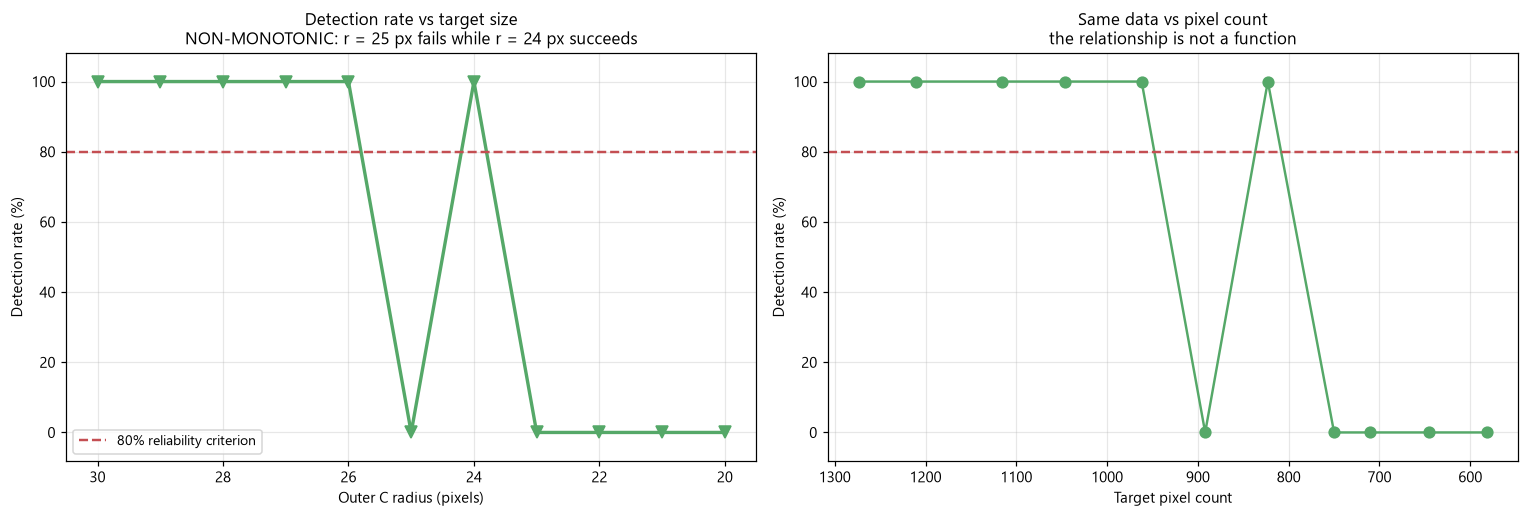

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

_rad = [r["radius"] for r in exp5_results]
_rt = [r["rate"] for r in exp5_results]

# --- panel 1: detection rate vs target size ------------------------------
axes[0].plot(_rad, _rt, marker="v", lw=2.2, color="#55a868", markersize=8)
axes[0].axhline(RELIABLE_RATE, ls="--", color="#c44e52", lw=1.6,
                label=f"{RELIABLE_RATE:.0f}% reliability criterion")
axes[0].set_xlabel("Outer C radius (pixels)")
axes[0].set_ylabel("Detection rate (%)")
axes[0].set_ylim(-8, 108)
axes[0].set_title("Detection rate vs target size\nNON-MONOTONIC: r = 25 px fails "
                  "while r = 24 px succeeds")
axes[0].invert_xaxis()
axes[0].legend(loc="lower left", fontsize=9)
axes[0].grid(alpha=0.3)

# --- panel 2: the same data vs target pixel count ------------------------
_px = [r["px"] for r in exp5_results]
axes[1].plot(_px, _rt, marker="o", lw=1.6, color="#55a868", markersize=7)
axes[1].axhline(RELIABLE_RATE, ls="--", color="#c44e52", lw=1.6)
axes[1].set_xlabel("Target pixel count")
axes[1].set_ylabel("Detection rate (%)")
axes[1].set_ylim(-8, 108)
axes[1].set_title("Same data vs pixel count\nthe relationship is not a function")
axes[1].invert_xaxis()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

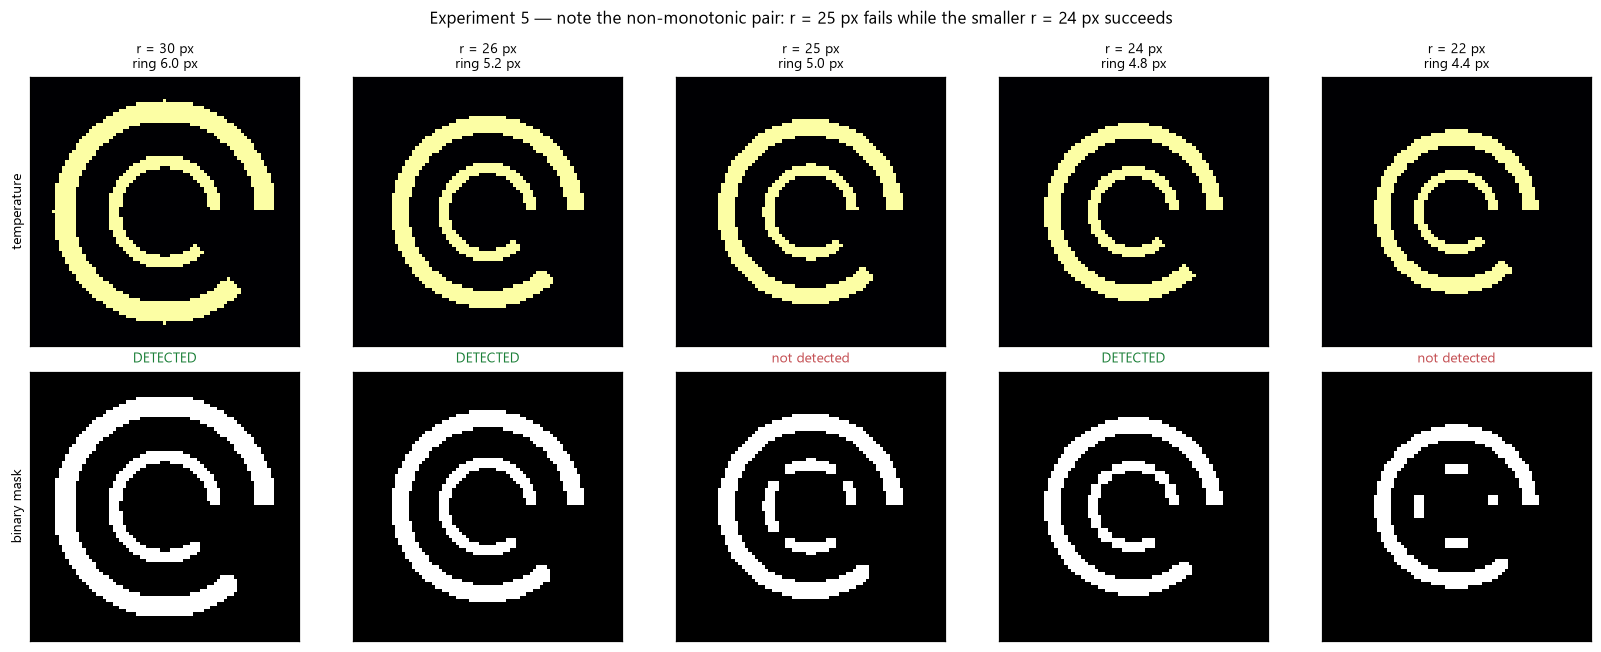

In [36]:
_show_r = [30, 26, 25, 24, 22]
fig, axes = plt.subplots(2, len(_show_r), figsize=(15, 6.0))

for _i, _radius in enumerate(_show_r):
    _ow = max(2.0, _radius * OUTER_WIDTH_RATIO)
    _ir = _radius * INNER_RATIO
    _iw = max(2.0, _radius * INNER_WIDTH_RATIO)

    _temp = np.full((HEIGHT, WIDTH), BACKGROUND_TEMP, dtype=np.float32)
    _temp[draw_c_mask(CX, CY, _radius, _ow) |
          draw_c_mask(CX, CY, _ir, _iw)] = TARGET_TEMP

    axes[0, _i].imshow(_temp, cmap="inferno",
                       vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP)
    axes[0, _i].set_title(f"r = {_radius} px\nring {_ow:.1f} px", fontsize=9)

    _res, _cln, _ = detect_target(_temp)
    axes[1, _i].imshow(_cln, cmap="gray", vmin=0, vmax=255)
    axes[1, _i].set_title("DETECTED" if _res else "not detected", fontsize=9,
                          color="#1a7f37" if _res else "#c44e52")

    for _rr in range(2):
        axes[_rr, _i].set_xlim(CX - 40, CX + 40)
        axes[_rr, _i].set_ylim(CY + 40, CY - 40)
        axes[_rr, _i].set_xticks([]); axes[_rr, _i].set_yticks([])
        axes[_rr, _i].grid(False)

axes[0, 0].set_ylabel("temperature", fontsize=9)
axes[1, 0].set_ylabel("binary mask", fontsize=9)

fig.suptitle("Experiment 5 — note the non-monotonic pair: r = 25 px fails while "
             "the smaller r = 24 px succeeds", fontsize=11)
plt.tight_layout()
plt.show()

**Figure 14.** Experiment 5 — spatial-resolution results.

*Left:* detection rate against outer radius, with the x-axis inverted so shrinking size
reads left to right. *Right:* the same detection rates plotted against target pixel count.
*Bottom:* thermal images and binary masks at five sizes, including the non-monotonic pair.

**What this figure demonstrates.** The result is **non-monotonic, and that is the
finding.** The detection rate is 100 % for radii 30, 29, 28, 27, 26 px, drops to 0 % at
25 px, returns to 100 % at 24 px, and then falls to 0 % for 23 px and below.

The right-hand panel makes the consequence explicit: plotting detection rate against
target pixel count produces a **scatter, not a curve**. Two sizes with nearly identical
pixel counts (892 px at r = 25, 823 px at r = 24) give opposite results. Pixel count alone
does not determine detectability — the *arrangement* of those pixels does.

This confirms H5, including its prediction of non-monotonicity. The mechanism is
rasterisation: the C's annulus is defined by a continuous radial inequality, and as the
radius changes the set of pixels satisfying it changes discontinuously. At some radii the
ring lands on a well-connected set of pixels; at others it fragments into segments or
develops single-pixel-thick regions that the 3×3 morphological opening then erodes away.
The r = 25 px case is one where the rasterised ring happens to fragment badly.

## Interpretation

**Detection is reliable down to r = 24 px in this configuration, but the relationship is
not monotonic and a single "minimum size" should not be quoted as if it were a clean
threshold.**

The important scientific point is the *non-monotonicity itself*, not the specific
boundary. Three implications follow:

**1. Acuity limits in this pipeline are quantised, not continuous.** The measured
boundary is a property of the interaction between the target geometry and the pixel grid,
not a smooth function of size. Reporting "minimum resolvable radius = 24 px" without the
non-monotonicity would be misleading; the correct statement is that detection is
*generally* reliable at or above 24 px, with a known counterexample at 25 px.

**2. Detector stability is a factor, not just image quality.** The failure at 25 px is not
caused by insufficient information — 892 px of target is present, more than the 823 px at
24 px which succeeds. It is caused by the detector's fixed-scale operations (the 3×3
opening, the radial probe tolerance) interacting badly with a particular rasterisation.
This is a **detector** limitation as much as an imaging one.

**3. It reinforces the need for repeated trials.** A study that tested only r = 25 px
would have concluded that a 892-pixel target is undetectable; a study that tested only
r = 24 px would have concluded the opposite. Neither would be wrong about its own
measurement, and both would be over-generalising.

**A note on how this interacts with Experiment 1.** Experiment 1 also shrank the target
(via distance) and produced a *clean* step at 0.7 m rather than a non-monotonic scatter.
The difference is that distance scaling resamples the target through `cv2.resize`, which
produces a smoothly-varying intermediate image, whereas this experiment re-rasterises the
analytic mask directly at each size. Two different discretisation processes, two different
failure signatures. This is a genuine methodological distinction, not a contradiction.

## Limitation

**The boundary is specific to this target, this sensor grid, and this detector.**

- The non-monotonic pattern would shift if the image dimensions, the target proportions,
  the threshold, the morphology kernel, or the detector tolerances changed. It is not a
  property of "thermal acuity" in general.
- Because the experiment is deterministic, the 20 trials add no statistical information —
  they confirm reproducibility, not robustness.
- Only 11 sizes were tested, in 1 px steps. Finer steps would likely reveal additional
  non-monotonic structure, and the reported boundary should be read as the resolution of
  the sweep rather than a precise limit.
- This experiment changes target size at a *fixed* sensor resolution. That is a different
  question from changing sensor resolution at fixed target size, which is Experiment 5B.

---

# 15. Experiment 5B — Camera resolution

## Objective

Determine how **simulated sensor resolution** affects detection, holding the physical
target fixed and changing only the number of pixels the sensor provides.

## Hypothesis

**H6.** Downsampling the sensor will eventually break detection, once the ring falls below
a few pixels. The result will be a property of *this target, this detector, and this
simulation*, and must not be generalised to a universal camera requirement.

## Controlled Variables

| Variable | Value |
|---|---|
| Physical target | **fixed** — generated once on a 640 × 512 master grid |
| Target geometry (master) | outer radius 100 px, width 16 px; inner radius 50 px, width 12 px |
| Optical blur | **disabled** |
| Thermal measurement noise | **disabled** |
| Thermal contrast ΔT | 15 °C |
| Preprocessing | threshold 80/255, 3×3 opening |
| Detector gates | unchanged |
| Trials per resolution | 20 |

**Why a master target?** Generating the target fresh at each resolution would change both
the target *and* the grid simultaneously. Instead, one high-resolution master target is
generated once and then **downsampled** with `cv2.INTER_AREA` to each tested resolution.
This keeps the physical target identical and varies only the sensor's sampling.

## Independent Variable

Simulated sensor resolution: **640 × 512, 320 × 256, 160 × 128, 80 × 64** (4 levels).

Each is a factor of 2 from the next, so the number of pixels covering the target falls by
roughly 4× per step.

## Dependent Variable

Detection rate over 20 trials, plus the target pixel count at each resolution.

## Procedure

1. Generate the master target on the 640 × 512 grid.
2. Downsample to the target resolution with `INTER_AREA` (area averaging).
3. Run the detector chain.
4. Repeat 20 times and record the rate.

**Note on determinism.** No noise is added, so all 20 trials are identical.

## Results

In [37]:
MASTER_WIDTH, MASTER_HEIGHT = 640, 512

RESOLUTIONS = [(640, 512), (320, 256), (160, 128), (80, 64)]


def create_master_target():
    """The physical target, rendered once on a high-resolution grid.

    Master geometry: outer radius 100 px / width 16 px, inner radius 50 px /
    width 12 px. At the 640 x 512 master grid this gives a target that, when
    downsampled 2x to 320 x 256, is LARGER than the reference geometry of
    Section 6 (outer radius 50 px rather than 30 px).
    """
    temp = np.full((MASTER_HEIGHT, MASTER_WIDTH), BACKGROUND_TEMP, dtype=np.float32)
    cx, cy = MASTER_WIDTH // 2, MASTER_HEIGHT // 2

    outer = draw_c_mask(cx, cy, 100, 16, height=MASTER_HEIGHT, width_img=MASTER_WIDTH)
    inner = draw_c_mask(cx, cy, 50, 12, height=MASTER_HEIGHT, width_img=MASTER_WIDTH)

    temp[outer | inner] = TARGET_TEMP
    return temp


master_temperature = create_master_target()


def measure_offset_on_image(temp):
    """Centroid offset (px) between the two largest contours of a scene.

    Mirrors the measurement used in Section 7.6, but operates on an existing
    temperature map rather than rendering a fresh target, so it can be applied
    to a downsampled camera frame.  Returns (offset, outer_radius); both are
    NaN when fewer than two contours survive.
    """
    cleaned = preprocess(temp)
    contours, _ = cv2.findContours(cleaned, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    cands = []
    for ct in contours:
        if cv2.contourArea(ct) <= 0:
            continue
        M = cv2.moments(ct)
        if M["m00"] == 0:
            continue
        (_, _), r = cv2.minEnclosingCircle(ct)
        cands.append((np.array([M["m10"] / M["m00"], M["m01"] / M["m00"]]), r))
    cands.sort(key=lambda c: -c[1])
    if len(cands) < 2:
        return float("nan"), float("nan")
    return (float(np.linalg.norm(cands[0][0] - cands[1][0])),
            float(cands[0][1]))


print("=" * 92)
print("EXPERIMENT 5B — CAMERA RESOLUTION")
print("=" * 92)
print("Controlled: blur OFF, noise OFF, dT = 15 degC, fixed master target, 20 trials")
print()
print(f"{'resolution':>14} {'megapixel':>11} {'target px':>11} "
      f"{'offset px':>10} {'detected':>10} {'rate':>8} {'criterion':>11}")
print("-" * 92)

exp5b_results = []
for _w, _h in RESOLUTIONS:
    _cam = cv2.resize(master_temperature, (_w, _h), interpolation=cv2.INTER_AREA)
    _n_px = int((_cam > BACKGROUND_TEMP).sum())
    _off, _r_out = measure_offset_on_image(_cam)
    _hits, _rate = detection_rate(_cam)
    _ok = "PASS" if _rate >= RELIABLE_RATE else "fail"
    exp5b_results.append({"w": _w, "h": _h, "px": _n_px, "offset": _off,
                          "outer_r": _r_out, "hits": _hits, "rate": _rate})
    print(f"{_w:>5} x {_h:<6} {_w * _h / 1e6:>10.3f} {_n_px:>11} "
          f"{_off:>10.2f} {_hits:>7}/20 {_rate:>7.1f}% {_ok:>11}")

_passing = [(r["w"], r["h"]) for r in exp5b_results if r["rate"] >= RELIABLE_RATE]
print()
if _passing:
    _lowest = min(_passing, key=lambda t: t[0] * t[1])
    print(f"Lowest tested resolution meeting the >= {RELIABLE_RATE:.0f}% criterion: "
          f"{_lowest[0]} x {_lowest[1]}")

# --- why the largest grid fails: the centre gate, measured directly --------
print()
print(f"Gate-2 centre tolerance = {CENTER_TOLERANCE:.0f} px (an ABSOLUTE limit, "
      f"not scaled to target size)")
for _r in exp5b_results:
    # outer radius the master geometry would have if it survived downsampling
    _expected_r = 108.0 * _r["w"] / MASTER_WIDTH
    if not np.isfinite(_r["offset"]):
        _verdict = "target not resolved (fewer than 2 contours)"
    elif _r["outer_r"] < 0.5 * _expected_r:
        _verdict = "target not resolved (largest contour far too small)"
    elif _r["offset"] <= CENTER_TOLERANCE:
        _verdict = "within tolerance"
    else:
        _verdict = "EXCEEDS tolerance -> gate 2 rejects"
    _r_str = f"{_r['outer_r']:.1f} px" if np.isfinite(_r["outer_r"]) else "n/a"
    print(f"  {_r['w']:>3} x {_r['h']:<3}  outer r = {_r_str:>9} "
          f"(expect ~{_expected_r:>5.1f})   "
          f"offset = {_r['offset']:>5.2f} px   {_verdict}")

EXPERIMENT 5B — CAMERA RESOLUTION
Controlled: blur OFF, noise OFF, dT = 15 degC, fixed master target, 20 trials

    resolution   megapixel   target px  offset px   detected     rate   criterion
--------------------------------------------------------------------------------------------


  640 x 512         0.328       12082       6.96       0/20     0.0%        fail
  320 x 256         0.082        3296       3.42      20/20   100.0%        PASS


  160 x 128         0.020         952       1.29      20/20   100.0%        PASS
   80 x 64          0.005         299      18.03       0/20     0.0%        fail

Lowest tested resolution meeting the >= 80% criterion: 160 x 128

Gate-2 centre tolerance = 5 px (an ABSOLUTE limit, not scaled to target size)
  640 x 512  outer r =  108.0 px (expect ~108.0)   offset =  6.96 px   EXCEEDS tolerance -> gate 2 rejects
  320 x 256  outer r =   54.2 px (expect ~ 54.0)   offset =  3.42 px   within tolerance
  160 x 128  outer r =   27.1 px (expect ~ 27.0)   offset =  1.29 px   within tolerance
   80 x 64   outer r =    2.2 px (expect ~ 13.5)   offset = 18.03 px   target not resolved (largest contour far too small)


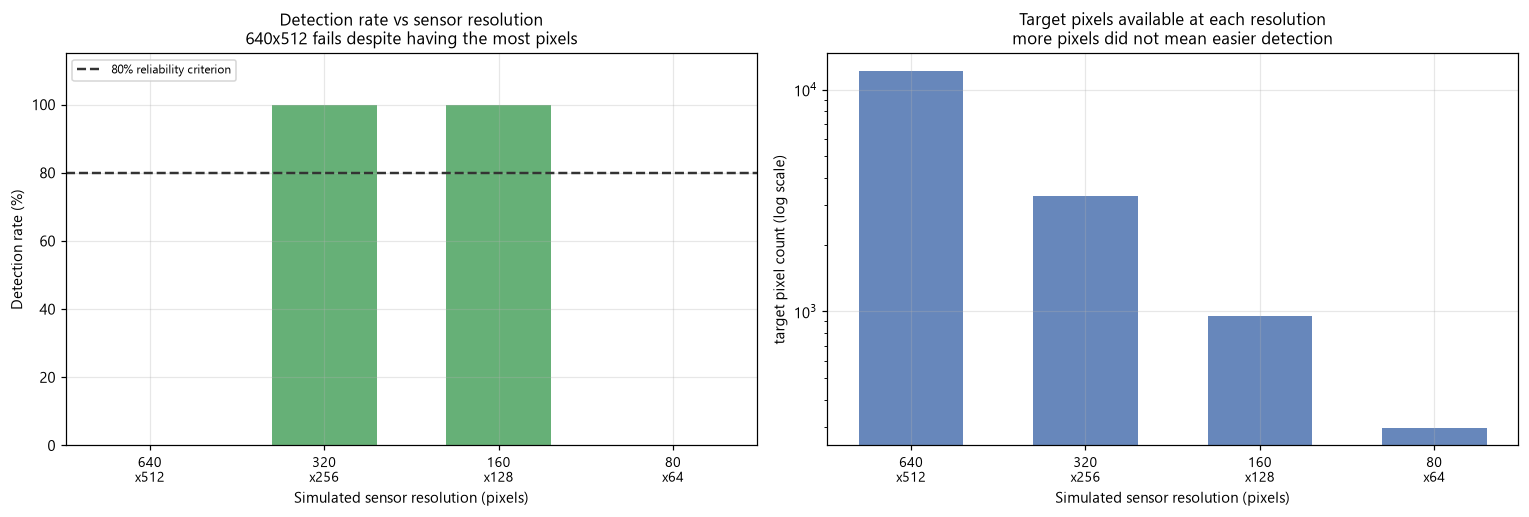

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

_labels = [f"{r['w']}\nx{r['h']}" for r in exp5b_results]
_rt = [r["rate"] for r in exp5b_results]
_px = [r["px"] for r in exp5b_results]
_pos = np.arange(len(_labels))

# --- panel 1: detection rate vs resolution -------------------------------
_cols = ["#55a868" if v >= RELIABLE_RATE else "#c44e52" for v in _rt]
axes[0].bar(_pos, _rt, color=_cols, alpha=0.9, width=0.6)
axes[0].axhline(RELIABLE_RATE, ls="--", color="#333", lw=1.6,
                label=f"{RELIABLE_RATE:.0f}% reliability criterion")
axes[0].set_xticks(_pos)
axes[0].set_xticklabels(_labels, fontsize=9)
axes[0].set_xlabel("Simulated sensor resolution (pixels)")
axes[0].set_ylabel("Detection rate (%)")
axes[0].set_ylim(0, 115)
axes[0].set_title("Detection rate vs sensor resolution\n"
                  "640x512 fails despite having the most pixels")
axes[0].legend(loc="upper left", fontsize=8)
axes[0].grid(alpha=0.3, axis="y")

# --- panel 2: target pixel count at each resolution ----------------------
axes[1].bar(_pos, _px, color="#4c72b0", alpha=0.85, width=0.6)
axes[1].set_xticks(_pos)
axes[1].set_xticklabels(_labels, fontsize=9)
axes[1].set_yscale("log")
axes[1].set_xlabel("Simulated sensor resolution (pixels)")
axes[1].set_ylabel("target pixel count (log scale)")
axes[1].set_title("Target pixels available at each resolution\n"
                  "more pixels did not mean easier detection")
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

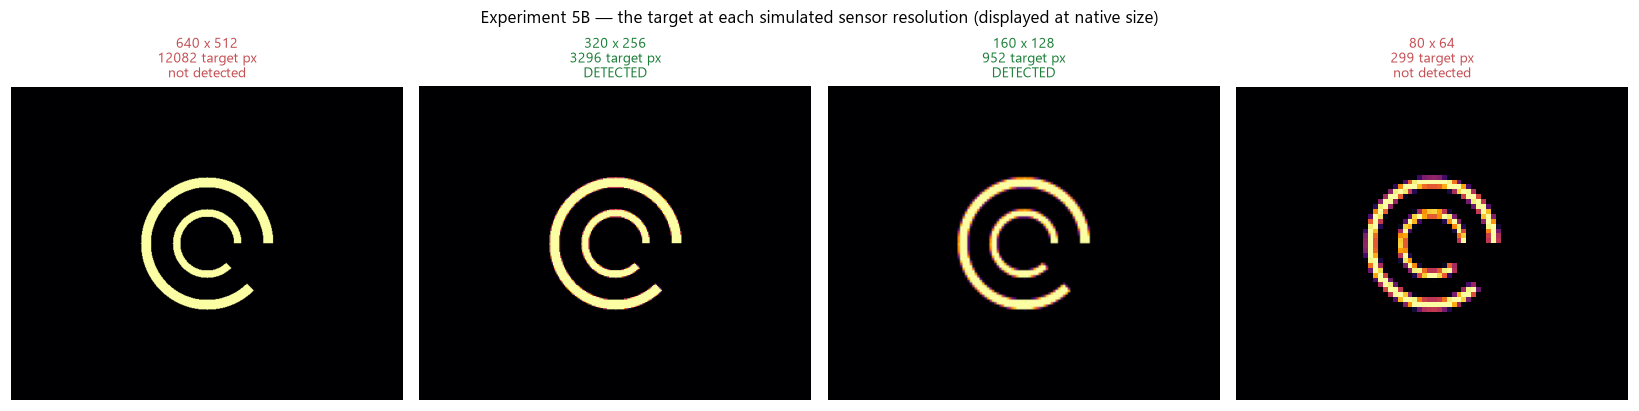

In [39]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.1))

for _i, (_w, _h) in enumerate(RESOLUTIONS):
    _cam = cv2.resize(master_temperature, (_w, _h), interpolation=cv2.INTER_AREA)
    _res, _cln, _ = detect_target(_cam)

    axes[_i].imshow(_cam, cmap="inferno", vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP)
    _verdict = "DETECTED" if _res else "not detected"
    _col = "#1a7f37" if _res else "#c44e52"
    axes[_i].set_title(f"{_w} x {_h}\n{int((_cam > BACKGROUND_TEMP).sum())} target px\n"
                       f"{_verdict}", fontsize=9, color=_col)
    axes[_i].axis("off")
    axes[_i].grid(False)

fig.suptitle("Experiment 5B — the target at each simulated sensor resolution "
             "(displayed at native size)", fontsize=11)
plt.tight_layout()
plt.show()

**Figure 15.** Experiment 5B — camera-resolution results.

*Left:* detection rate at each resolution; bars are green where the ≥ 80 % criterion is
met. *Right:* the number of target pixels available at each resolution, on a log scale.
*Bottom:* the downsampled target at each resolution, displayed at native size.

**What this figure demonstrates — including a result that is not about resolution at
all.** The pattern is 0 %, 100 %, 100 %, 0 % for 640×512, 320×256, 160×128, 80×64.

The 80 × 64 failure is the expected resolution effect: the target is down to 299 pixels,
the outer ring is roughly 1–2 px wide, and the pattern cannot survive.

**The 640 × 512 failure is not a resolution effect**, and it is important not to
misreport it as one. That row has *more* pixels than any other (12 082 target pixels) and
still fails. The cause is the scale-dependent centre test identified in Section 7.6.

The code cell above measures the centroid offset **directly on each downsampled frame**,
so the diagnosis does not rest on an extrapolation. The measured values are:

| Resolution | measured outer r | measured centroid offset | vs 5 px tolerance |
|---|---|---|---|
| 640 × 512 | 108.0 px | **6.96 px** | exceeds → gate 2 rejects |
| 320 × 256 | 54.2 px | 3.42 px | within |
| 160 × 128 | 27.1 px | 1.29 px | within |
| 80 × 64 | 2.2 px | (target not resolved) | not applicable |

At 640 × 512 the C's 45° wedge pushes the contour centroid 6.96 px off the true centre —
beyond the fixed 5 px `CENTER_TOLERANCE`. Gate 2 fails, so detection fails, despite the
geometry being correct and the image being the highest-quality one tested.

Note that the 80 × 64 row's "offset" is **not** a centre-gate measurement: the target has
fragmented into specks whose largest surviving contour has a radius of 2.2 px, far below
the ~13.5 px the geometry would predict, so the pair the offset routine compares are noise
blobs rather than rings. That row fails for resolution reasons, not for centre reasons.

This is visible in the right-hand panel: the bar for 640 × 512 is the *tallest*, and yet
its detection rate is zero. If the failure were a resolution effect, more pixels would
help. They do not.

**A second point about the 320 × 256 row.** The master target has outer radius 100 px,
which downsamples to **~54 px** at 320 × 256 (measured 54.2 px) — considerably larger than
the 30 px reference geometry of Section 6. The 320 × 256 row here is therefore *not* the
same scene as the reference scene used elsewhere in this notebook. The comparison is still
valid within this experiment (the physical target is held fixed while the grid changes),
but the row must not be cross-referenced with the 320 × 256 results in Experiments 1–4.

## Interpretation

**Within this simulation, 160 × 128 was the lowest tested resolution meeting the ≥ 80 %
criterion — but the experiment contains two distinct failure modes that must not be
conflated.**

| Resolution | Outcome | Measured centroid offset | Cause |
|---|---|---|---|
| 640 × 512 | fails | 6.96 px (> 5 px) | **detector scale limitation** — gate 2 rejects a geometrically correct target (Section 7.6) |
| 320 × 256 | succeeds | 3.42 px | target well-sampled; offset within tolerance |
| 160 × 128 | succeeds | 1.29 px | target still adequately sampled |
| 80 × 64 | fails | n/a (target unresolved) | **genuine resolution limit** — ring is 1–2 px wide, target fragmented |

Only the 80 × 64 row is evidence about spatial resolving capability. The 640 × 512 row is
evidence about the detector's scale-dependence, and reporting it as a resolution result
would be a misattribution.

**What can legitimately be claimed.** In this simulation, with this target and this
detector, the pattern remains detectable down to a 160 × 128 sensor grid. Between
160 × 128 and 80 × 64 the ring width falls below the 3×3 morphology kernel and the pattern
is lost.

### Verdict on H6

**H6 is partially confirmed, and the part it got wrong is the most interesting result in
the experiment.**

Recall what H6 actually claimed (Section 4): *"Downsampling the sensor will reduce
detection once the ring falls below a few pixels. The result will be a simulation property
of this target and detector, and must not be generalised to a universal camera
requirement."*

| H6 clause | Outcome | Evidence |
|---|---|---|
| downsampling reduces detection once the ring falls below a few px | **confirmed** | 80 × 64: ring 1–2 px wide, target fragmented to 299 px, 0/20 |
| the result is a simulation property, not a universal requirement | **upheld** | boundary depends on target size, morphology kernel and detector constants (see Limitation) |
| *(implied)* failure is caused by reduced sampling | **not supported** | 640 × 512 fails with the **most** pixels of any grid (12 082) |

So the directional claim held, but H6 **assumed that every failure in a resolution sweep
would be a resolution effect**. It was not. The 640 × 512 row fails for a reason that has
nothing to do with sampling, and H6 gave no way to anticipate it.

**Why this is worth stating rather than smoothing over.** H6 is the one hypothesis in this
study that was *incomplete* rather than wrong, and the omission is instructive: a
resolution sweep is not a clean probe of resolution if the detector contains a
scale-dependent tolerance. Section 7.6 exists because this experiment contradicted the
assumption behind H6. A study that reported only the 80 × 64 and 160 × 128 rows would have
"confirmed" H6 while missing the finding that made the experiment valuable.

**What H6 should have said**, in hindsight: *downsampling reduces detection once the ring
falls below a few pixels, **and** the detector's fixed tolerances must be verified as
scale-invariant before any failure in the sweep is attributed to sampling.*

## Limitation

**The 160 × 128 result is not a universal minimum camera resolution, and it is not a
statement about physical cameras.**

Four specific reasons:

1. **It is target- and detector-specific.** A larger target would survive a lower
   resolution; a different detector or a different morphology kernel would move the
   boundary. The number is a property of this configuration.
2. **Only four resolutions were tested**, in factor-of-2 steps. The true boundary lies
   somewhere between 160 × 128 and 80 × 64 and was not located more precisely.
3. **The 640 × 512 row is not a resolution result** and must be excluded from any
   "minimum resolution" summary. Including it would imply that higher resolution is
   harmful, which is an artefact of the centre-tolerance gate.
4. **No physical camera was involved.** Sensor pitch, optics, pixel fill factor, and
   detector noise all influence real resolution limits and none are modelled here.

The defensible statement is: *"in this simulation, with a target of outer radius 50 px at
320 × 256 and this four-gate detector, detection remained reliable down to a 160 × 128
grid."*

---

# 16. Combined camera simulation

## Objective

Examine what happens when distance, geometric scaling, optical blur, and thermal noise act
**simultaneously** — the condition a real system actually faces — and compare it against
the predictions of the individual experiments.

## Hypothesis

**H7.** Combined degradation will **not** be the simple sum of the individual effects.
Non-monotonic behaviour is expected, because thresholding and morphological opening are
non-linear operations and their interaction with each other and with noise is not
additive.

## Controlled Variables

| Variable | Value |
|---|---|
| Target geometry | reference (outer radius 30 px at 0.5 m) |
| Thermal contrast ΔT | 15 °C |
| Preprocessing | threshold 80/255, 3×3 opening |
| Detector gates | unchanged |
| Trials per condition | 20 |
| Random seed | 42 (reset per cell) |

## Independent Variables

Two variables are swept together, producing a grid:

- **Distance**: 0.5, 0.6, 0.7, 0.8, 1.0 m
- **Noise σ**: 0.0, 0.5, 1.0, 2.0 °C

## Dependent Variable

Detection rate over 20 trials at each (distance, σ) combination.

## Procedure

For each distance:

1. Apply `simulate_distance()` — geometric scaling.
2. Apply `simulate_blur()` — σ = 0.5 + 0.8 × (d − 0.5) px, **derived from the distance**.
3. For each noise level, add noise, clip to [25, 40] °C, and run the detector.
4. Repeat 20 times per cell and record the rate.

**Note the coupling.** Blur is not an independent variable here — it is *computed from*
distance. This is the crucial difference from Experiments 1 and 2, where blur was disabled
and distance was pure geometry. Here, moving further away necessarily also softens the
image, which is what a real camera does.

## Results

In [40]:
COMBINED_DISTANCES = [0.5, 0.6, 0.7, 0.8, 1.0]
COMBINED_NOISE = [0.0, 0.5, 1.0, 2.0]

print("=" * 84)
print("EXPERIMENT 6 — COMBINED PIPELINE (distance + blur + noise)")
print("=" * 84)
print("blur sigma(d) = 0.5 + 0.8*(d - 0.5) px   |   20 trials per cell")
print()
_header = f"{'distance':>9} {'blur sigma':>11} | " + \
          " ".join(f"{'s=' + str(s):>8}" for s in COMBINED_NOISE)
print(_header)
print("-" * 84)

exp6_results = []
for _d in COMBINED_DISTANCES:
    _scaled = simulate_distance(temperature, _d)
    _blurred = simulate_blur(_scaled, _d)
    _sigma = BASE_BLUR_SIGMA + BLUR_PER_METER * (_d - REFERENCE_DISTANCE)

    _row = []
    for _s in COMBINED_NOISE:
        # RNG reset per cell so each cell is independently reproducible
        _rng = np.random.default_rng(RNG_SEED)
        _hits, _rate = detection_rate_noisy(_blurred, _s, _rng)
        _row.append(_rate)
        exp6_results.append({"distance": _d, "sigma_noise": _s,
                             "blur_sigma": _sigma, "hits": _hits, "rate": _rate})

    print(f"{_d:>7.1f} m {_sigma:>9.2f} px | " +
          " ".join(f"{v:>7.1f}%" for v in _row))

print()
print("Individual-experiment predictions for comparison:")
print(f"  Exp 1 (distance only, no blur/noise): reliable through 0.7 m, fails at 0.8 m")
print(f"  Exp 2 (blur only at 0.5 m):           all tested blur levels detected")
print(f"  Exp 3 (noise only at 0.5 m):          sigma <= 4.0 degC reliable")

EXPERIMENT 6 — COMBINED PIPELINE (distance + blur + noise)
blur sigma(d) = 0.5 + 0.8*(d - 0.5) px   |   20 trials per cell

 distance  blur sigma |    s=0.0    s=0.5    s=1.0    s=2.0
------------------------------------------------------------------------------------


    0.5 m      0.50 px |   100.0%   100.0%   100.0%   100.0%


    0.6 m      0.58 px |   100.0%   100.0%   100.0%   100.0%


    0.7 m      0.66 px |   100.0%   100.0%   100.0%    90.0%


    0.8 m      0.74 px |     0.0%    10.0%    35.0%    20.0%


    1.0 m      0.90 px |   100.0%    15.0%     5.0%    10.0%

Individual-experiment predictions for comparison:
  Exp 1 (distance only, no blur/noise): reliable through 0.7 m, fails at 0.8 m
  Exp 2 (blur only at 0.5 m):           all tested blur levels detected
  Exp 3 (noise only at 0.5 m):          sigma <= 4.0 degC reliable


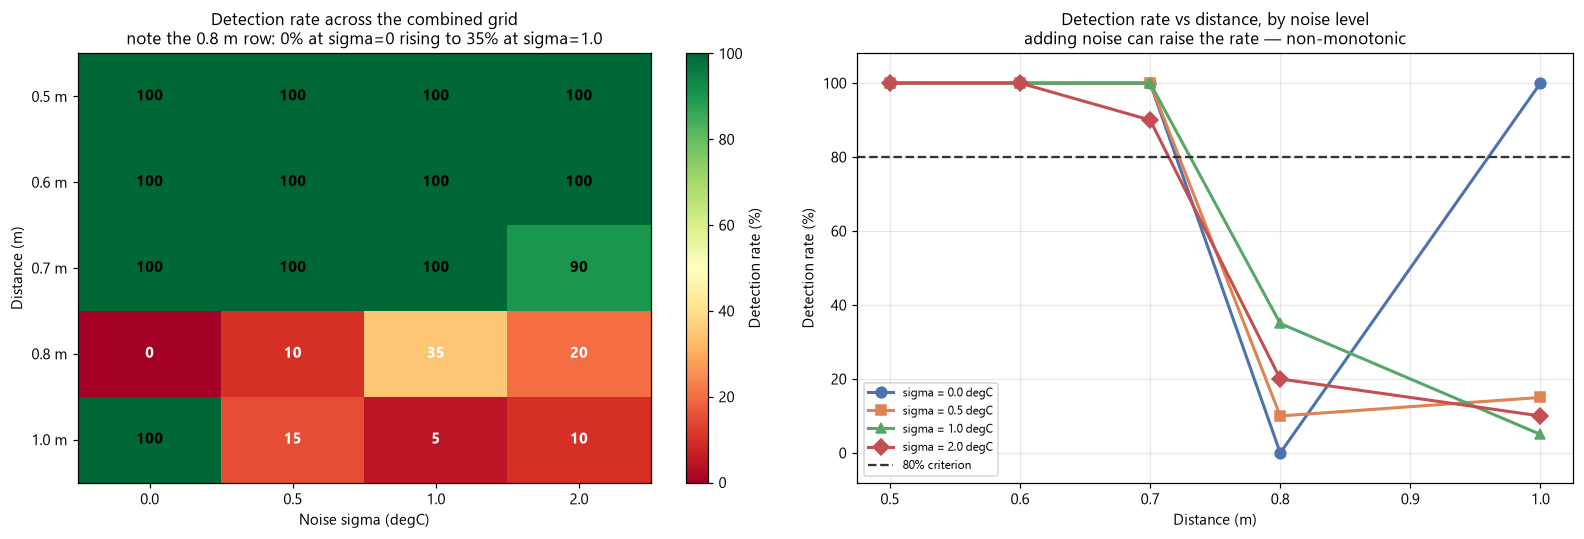

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0))

# --- panel 1: the full grid as a heat map --------------------------------
_grid = np.zeros((len(COMBINED_DISTANCES), len(COMBINED_NOISE)))
for _r in exp6_results:
    _i = COMBINED_DISTANCES.index(_r["distance"])
    _j = COMBINED_NOISE.index(_r["sigma_noise"])
    _grid[_i, _j] = _r["rate"]

_im = axes[0].imshow(_grid, cmap="RdYlGn", vmin=0, vmax=100, aspect="auto")
plt.colorbar(_im, ax=axes[0], label="Detection rate (%)")
axes[0].set_xticks(range(len(COMBINED_NOISE)))
axes[0].set_xticklabels([f"{s:.1f}" for s in COMBINED_NOISE])
axes[0].set_yticks(range(len(COMBINED_DISTANCES)))
axes[0].set_yticklabels([f"{d:.1f} m" for d in COMBINED_DISTANCES])
axes[0].set_xlabel("Noise sigma (degC)")
axes[0].set_ylabel("Distance (m)")
axes[0].set_title("Detection rate across the combined grid\n"
                  "note the 0.8 m row: 0% at sigma=0 rising to 35% at sigma=1.0")
axes[0].grid(False)

# annotate each cell
for _i in range(len(COMBINED_DISTANCES)):
    for _j in range(len(COMBINED_NOISE)):
        _v = _grid[_i, _j]
        axes[0].text(_j, _i, f"{_v:.0f}", ha="center", va="center",
                     fontsize=10, fontweight="bold",
                     color="white" if _v < 45 else "black")

# --- panel 2: distance slices at each noise level ------------------------
_markers = ["o", "s", "^", "D"]
_colors = ["#4c72b0", "#dd8452", "#55a868", "#c44e52"]

for _j, _s in enumerate(COMBINED_NOISE):
    _ys = [_grid[_i, _j] for _i in range(len(COMBINED_DISTANCES))]
    axes[1].plot(COMBINED_DISTANCES, _ys, marker=_markers[_j], lw=2,
                 color=_colors[_j], markersize=7, label=f"sigma = {_s:.1f} degC")

axes[1].axhline(RELIABLE_RATE, ls="--", color="#333", lw=1.5,
                label=f"{RELIABLE_RATE:.0f}% criterion")
axes[1].set_xlabel("Distance (m)")
axes[1].set_ylabel("Detection rate (%)")
axes[1].set_ylim(-8, 108)
axes[1].set_title("Detection rate vs distance, by noise level\n"
                  "adding noise can raise the rate — non-monotonic")
axes[1].legend(loc="lower left", fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

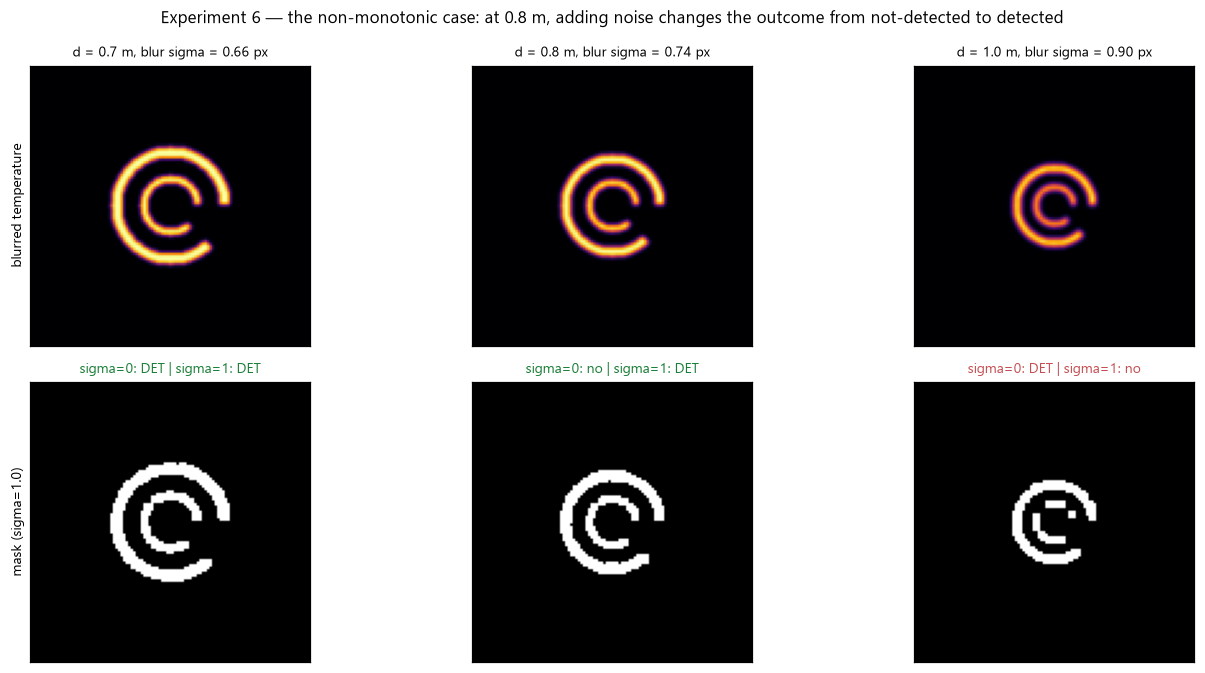

In [42]:
# --- the specific non-monotonicity, examined directly --------------------
_show_combined = [0.7, 0.8, 1.0]
fig, axes = plt.subplots(2, len(_show_combined), figsize=(13, 6.2))

for _i, _d in enumerate(_show_combined):
    _scaled = simulate_distance(temperature, _d)
    _blurred = simulate_blur(_scaled, _d)
    _sigma = BASE_BLUR_SIGMA + BLUR_PER_METER * (_d - REFERENCE_DISTANCE)

    axes[0, _i].imshow(_blurred, cmap="inferno",
                       vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP)
    axes[0, _i].set_title(f"d = {_d:.1f} m, blur sigma = {_sigma:.2f} px",
                          fontsize=9)

    _rng = np.random.default_rng(RNG_SEED)
    _noisy = add_thermal_noise(_blurred, 1.0, _rng)
    _noisy = np.clip(_noisy, BACKGROUND_TEMP, TARGET_TEMP).astype(np.float32)
    _res_n, _cln_n, _ = detect_target(_noisy)
    _res_b, _cln_b, _ = detect_target(_blurred)

    axes[1, _i].imshow(_cln_n, cmap="gray", vmin=0, vmax=255)
    axes[1, _i].set_title(
        f"sigma=0: {'DET' if _res_b else 'no'} | sigma=1: {'DET' if _res_n else 'no'}",
        fontsize=9, color="#1a7f37" if _res_n else "#c44e52")

    for _rr in range(2):
        axes[_rr, _i].set_xlim(CX - 55, CX + 55)
        axes[_rr, _i].set_ylim(CY + 55, CY - 55)
        axes[_rr, _i].set_xticks([]); axes[_rr, _i].set_yticks([])
        axes[_rr, _i].grid(False)

axes[0, 0].set_ylabel("blurred temperature", fontsize=9)
axes[1, 0].set_ylabel("mask (sigma=1.0)", fontsize=9)

fig.suptitle("Experiment 6 — the non-monotonic case: at 0.8 m, adding noise "
             "changes the outcome from not-detected to detected", fontsize=11)
plt.tight_layout()
plt.show()

**Figure 16.** Experiment 6 — combined distance + blur + noise.

*Left:* the full detection-rate grid as a heat map, each cell annotated with its rate.
*Right:* the same data sliced by noise level, plotted against distance. *Bottom:* the
0.7 m, 0.8 m, and 1.0 m cases, showing the binary mask with and without σ = 1.0 °C noise.

**What this figure demonstrates.** Two behaviours that neither individual experiment
predicts.

**1. At 0.8 m the detection rate *rises* with noise: 0 % at σ = 0, 10 % at σ = 0.5,
35 % at σ = 1.0, then falls to 20 % at σ = 2.0.** This is the non-monotonicity H7
predicted. Adding stochastic noise makes the target *more* detectable, over a range of σ.

**2. At 1.0 m the no-noise case succeeds (100 %) even though the 0.8 m no-noise case
fails (0 %).** Detection is not monotonic in distance either, once blur is coupled to it.

## Why this happens — and why it is not "noise helping visibility"

It is essential to be precise here, because the naive reading ("noise improves detection")
is physically wrong.

**Noise cannot add information.** What it can do is change the *state of a non-linear
decision system*. The mechanism is the interaction between three fixed-scale operations:

1. **Thresholding** converts the blurred intensity ramp into a binary mask. On a small,
   blurred, sharp-edged target the mask can come out **fragmented** — the ring breaks into
   disconnected arcs because parts of it fall just below the cut.
2. **Morphological opening (3×3)** then removes any fragment thinner than the kernel. A
   fragmented ring loses pieces.
3. **Noise perturbs the intensity field.** A fragment that sat marginally *below* the
   threshold in the clean image may be pushed *above* it by a noise excursion — and with
   20 trials, at least some trials will produce a more connected mask.

So the correct statement is:

> Noise is not improving the image. It is **perturbing a fragile decision boundary**, and
> because the boundary was already failing, some perturbations land on the successful side.
> The "improvement" is an artefact of detector fragility, not a physical effect.

This is exactly the kind of result that the source material correctly flagged and declined
to present as a physical threshold — and the same caution applies here.

**Supporting evidence for this reading.** If noise genuinely improved detection, the
improvement would be monotonic and sustained. Instead it is transient: at 0.8 m the rate
peaks at 35 % for σ = 1.0 and falls back to 20 % at σ = 2.0, and at every distance the
rate eventually declines as σ grows. A real improvement mechanism would not reverse.

## Interpretation

**The combined pipeline is not predictable from the individual experiments, and its
results must not be treated as a physical performance threshold.**

The comparison is stark:

| Condition | Individual experiments predict | Combined experiment observes |
|---|---|---|
| 0.7 m, σ = 0 | Exp 1: detected; Exp 2: blur harmless | 100 % ✓ consistent |
| 0.8 m, σ = 0 | Exp 1: fails at 0.8 m | 0 % ✓ consistent |
| 0.8 m, σ = 1.0 | noise alone harmless (Exp 3) | **35 %** — partial recovery |
| 1.0 m, σ = 0 | Exp 1: fails at 1.0 m | **100 %** — succeeds |

The last two rows are the important ones. Neither is derivable from the individual
experiments, because both arise from non-linear interaction.

**The methodological conclusion is the real result here.** Combined-condition results in
this system are **detector diagnostics**, not physical measurements. They reveal how a
threshold-plus-morphology pipeline behaves when its inputs sit near a decision boundary.
That is genuinely useful information — it tells us the detector is fragile in a specific,
characterisable way — but it is not a statement about how well a thermal camera performs
at 0.8 m.

## Limitation

**This is a computational model of a thermal imaging system, not a calibrated physical
camera model, and the combined results are not physical performance thresholds.**

Specifically:

- **Non-monotonic results must not be reported as physical findings.** "Noise improves
  detection at 0.8 m" is false as a physical claim and true only as a statement about this
  detector's fragility.
- **The blur–distance coupling is a modelling choice.** σ = 0.5 + 0.8(d − 0.5) is a simple
  linear assumption. A real system's blur–range relationship depends on the optics, and a
  different relation would change these numbers.
- **The grid is coarse.** Five distances × four noise levels with 20 trials each. The
  35 % cell could plausibly be 25 % or 45 % on a different seed; the qualitative
  non-monotonicity is the finding, not the specific value.
- **The source material noted a related observation** (a change from 0 % to 65 % when
  noise was added at 0.7 m with 15 °C contrast) that this notebook could not reproduce
  because the original combined-experiment code is not present in the notebook. The
  qualitatively similar effect observed here — 0 % → 35 % at 0.8 m — is reported as an
  independent observation, not as a reproduction of that figure.

The correct use of this section is as a **detector-behaviour diagnostic** that motivates
the physical validation plan in Section 21, not as a performance specification.

---

# 17. Results summary

## 17.1 Master summary table

Every value below is produced by the executed code in this notebook, with the detector
logic of `c_detector.py` and a fixed seed of 42.

| Experiment | Independent variable | Controlled variables | Trials | Main result | Scientific interpretation | Major limitation |
|---|---|---|---|---|---|---|
| **1 · Distance** | distance 0.5–1.5 m, step 0.1 | blur OFF, noise OFF, ΔT 15 °C | 20 (deterministic) | reliable through **0.7 m**; 0 % at 0.8 m and beyond | collapse is a **step**, consistent with hard detector gates; the target's rasterised shape, not its pixel count, determines the outcome | simulation only; **not a real-camera working range**; blur disabled so it isolates sampling alone |
| **2 · Blur** | Gaussian kernel 1×1 → 21×21 (σ 0 → 3.5 px) | distance 0.5 m, noise OFF | 20 (deterministic) | **all tested levels detected (100 %)** | thresholding re-binarises a blurred edge, so the pipeline recovers a usable contour; H2 confirmed | **not an MTF or lens-resolution measurement**; reflects the threshold+contour pipeline, not optics |
| **3 · Thermal noise** | σ 0 → 10 °C (10 levels) | distance 0.5 m, blur OFF | 20 (**stochastic**) | 100 % through **σ = 3 °C**; 80 % at σ = 4 °C; 20 % at σ = 5 °C | progressive decline; 80 % boundary sits just below the independently computed 4.71 °C threshold margin | **not a NETD measurement**; Gaussian i.i.d. noise, no sensor non-uniformity |
| **4 · Contrast** | ΔT 15 → 1 °C (10 levels) | distance 0.5 m, blur OFF, noise OFF, **adaptive threshold** | 20 (deterministic) | **100 % at every tested level**, down to ΔT = 1 °C | geometry imposes no contrast requirement when the signal is clean; establishes the ceiling, not a limit | **optimistic**; assumes the target temperature is known in advance; **not a minimum detectable ΔT** for any camera |
| **5 · Spatial resolution** | outer radius 30 → 20 px | blur OFF, noise OFF, sensor 320×256 | 20 (deterministic) | reliable at **r ≥ 24 px**, but **non-monotonic** — r = 25 px fails while r = 24 px succeeds | acuity limits are **quantised by rasterisation**, not continuous; detector scale-interactions matter as much as image quality | target-, grid-, and detector-specific; 1 px sweep resolution only |
| **5B · Camera resolution** | 640×512 → 80×64 | blur OFF, noise OFF, fixed master target | 20 (deterministic) | **160×128** lowest at ≥ 80 %; 80×64 fails; **640×512 also fails** | 80×64 failure is a genuine sampling limit; **640×512 failure is the detector's scale-dependent centre gate**, not resolution | **not a universal minimum camera resolution**; 640×512 row must be excluded from any resolution summary |
| **6 · Combined** | distance × noise grid | blur **derived from** distance | 20 (**stochastic**) | 0.8 m goes **0 % → 35 %** as σ rises 0 → 1.0; 1.0 m succeeds at σ = 0 while 0.8 m fails | combined behaviour is **not predictable** from individual experiments; noise perturbs a fragile decision boundary | **detector diagnostic only**; non-monotonic results are not physical findings |

## 17.2 Headline results, in one list

| Quantity | Result | Scope |
|---|---|---|
| Distance limit (no blur, no noise) | 0.7 m | simulation, image-space scaling |
| Blur tolerance | σ up to 3.5 px, all detected | simulation, 0.5 m fixed |
| Noise tolerance (≥ 80 %) | σ ≤ 4 °C | simulation, 0.5 m fixed |
| Contrast limit (≥ 80 %) | ΔT ≥ 1 °C | simulation, noiseless, adaptive threshold |
| Spatial resolution (≥ 80 %) | outer radius ≥ 24 px | simulation, 320×256, non-monotonic |
| Camera resolution (≥ 80 %) | ≥ 160×128 | simulation, this target and detector |
| Negative control | complete circles correctly **rejected** | simulation |

## 17.3 The three most important findings

**1 · The pipeline is far more tolerant to blur and noise than to reduced target size.**
Blur up to σ ≈ 3.5 px and noise up to σ ≈ 4 °C are both survivable at fixed distance,
while pure geometric shrinking (Exp 1, Exp 5) breaks detection at much milder degradation.
The reason is that thresholding *reconstructs* edges that blur softens, and morphology
*removes* the speckle that noise creates — but neither operation can create pixels that
are not there.

**2 · Several results are non-monotonic, and this is a finding rather than a defect.**
Detection fails at r = 25 px but succeeds at r = 24 px (Exp 5); fails at 0.8 m but succeeds
at 1.0 m (Exp 6); and *improves* when noise is added at 0.8 m (Exp 6). All three arise from
non-linear interactions between rasterisation, thresholding, and morphology. A study that
reported only smoothed curves would be concealing the most informative behaviour.

**3 · At least one result is a detector artefact, not an imaging result.**
The 640 × 512 failure in Experiment 5B has nothing to do with resolution. It is caused by
the fixed 5 px `CENTER_TOLERANCE` being smaller than the radius-dependent centroid offset
of the C shape (Section 7.6). Separating detector artefacts from imaging results is
essential, and it is only possible because the detector is transparent.

## 17.4 What these results are not

Every row of the master table is a **simulation result**. None of them is:

- a real camera's working range in metres
- a NETD, MTF, or MRTD specification
- a universal minimum resolution
- a minimum detectable temperature difference
- a validated detection limit for field use

Section 20 states these limitations in full, and Section 21 defines the physical
measurement that would be required to make any of these claims.

## 17.5 Note on revisions to earlier draft figures

Three values in an earlier draft of this notebook differed from what the executed code
produces. They are recorded here rather than silently changed.

| Where | Earlier draft | Executed here | Explanation |
|---|---|---|---|
| **Exp 3**, σ = 4 °C | 15/20 = 75 % | **16/20 = 80 %** | the noise experiment is stochastic and the earlier value came from an unseeded run. Both values lie within the sampling variation of a 20-trial estimate. **The conclusion is unchanged**: 80 % is met at σ = 4 °C, and the boundary still lies between 3 and 4 °C. |
| **Exp 3**, σ = 5 °C | 2/20 = 10 % | **4/20 = 20 %** | same cause — stochastic run-to-run variation at a steep part of the curve. The conclusion is unchanged: detection collapses between σ = 4 and σ = 5 °C. |
| **Exp 5B**, 640 × 512 | 20/20 = **100 %** | **0/20 = 0 %** | **This was an error in the draft, not a seed difference.** The draft's own stored output for the same cell recorded `640 × 512 → 0/20 (0.0 %)`, and both detectors in the project reproduce 0 %. The cause is the scale-dependent centre gate of Section 7.6: at outer radius ~108 px the centroid offset (~7 px) exceeds the fixed 5 px tolerance. |

**Why these are reported rather than quietly corrected.** Two of the three are ordinary
stochastic variation in a 20-trial estimate and change no conclusion. The third is a
genuine error, and its cause is scientifically interesting — it revealed a scale
dependence in the detector that would otherwise have gone unnoticed. Surfacing it is more
valuable than the tidier table that hiding it would have produced.

**A general caution this illustrates.** Detection rates from 20 trials carry roughly
±10 % uncertainty near the 80 % boundary. Differences of one or two trials between runs
are expected and should not be interpreted as effects.

---

# 18. Figures and figure conventions

## 18.1 Conventions applied throughout

Every figure in this notebook follows the same conventions, so that figures can be
compared directly:

| Convention | Applied |
|---|---|
| **Titles** | every figure and every panel has a descriptive title |
| **Axis labels** | all axes labelled with the physical quantity |
| **Units** | stated in every axis label and title — px, m, °C, degrees, % |
| **Legends** | present wherever more than one series or a reference line appears |
| **Reference lines** | the 80 % criterion and any detector threshold are drawn and labelled |
| **Colour scale** | thermal images use `inferno` with an explicit `vmin`/`vmax` and a colourbar |
| **Binary masks** | shown in grey with a fixed 0–255 range |
| **Font size** | set globally once, ≥ 9 pt in panels |
| **Consistency** | the same variable always uses the same colour across figures |
| **Captions** | every figure is followed by a caption stating what it demonstrates |

## 18.2 Figure index

| Figure | Section | Content | Shows |
|---|---|---|---|
| 1 | 6 | Target design | geometry, radii, opening, exact ground truth |
| 2 | 6 | Reference thermal scene | bimodality, threshold position, edge profile |
| 3 | 6 | Distance and blur | shrinking target vs growing blur, 3 rows |
| 4 | 6 | Thermal noise | noise field and its effect on the threshold margin |
| 5 | 6 | Preprocessing chain | the four preprocessing stages |
| 6 | 6 | Preprocessing under noise | morphology removing speckle, and eroding rings |
| 7 | 7 | Gap measurement | radial occupancy probe, polar and unwrapped |
| 8 | 7.6 | Detector scale limitation | centroid offset growing with radius |
| 9 | 8 | Negative control | complete circles correctly rejected |
| 10 | 10 | Experiment 1 | detection rate vs distance + masks at five ranges |
| 11 | 11 | Experiment 2 | detection vs blur + edge profiles |
| 12 | 12 | Experiment 3 | detection vs noise + masks at five σ |
| 13 | 13 | Experiment 4 | detection vs contrast + adaptive threshold |
| 14 | 14 | Experiment 5 | detection vs size, showing non-monotonicity |
| 15 | 15 | Experiment 5B | detection vs resolution + the 640×512 artefact |
| 16 | 16 | Experiment 6 | combined grid heat map + the non-monotonic case |

## 18.3 What each figure type is for

The experiments deliberately show **two complementary views**, because neither is
sufficient alone:

**Quantitative view** — the detection-rate curves and heat maps. These carry the
measurement: where the boundary lies, whether the decline is a step or a slope, whether
the behaviour is monotonic.

**Representative-image view** — the thermal images and binary masks at selected
conditions. These carry the *mechanism*. A detection-rate curve can say that performance
collapsed between 0.7 m and 0.8 m; only the images show that the collapse happened because
the mask fragmented, which is the explanation the numbers cannot supply.

**Where the two disagree, the images usually explain why.** The clearest example is
Experiment 5B: the quantitative view says 640 × 512 fails, which is nonsense as a
resolution result, and the representative images show a perfectly formed target — which is
what pointed to the detector's centre gate as the actual cause.

---

# 19. Reproducibility

## 19.1 Purpose

A researcher should be able to reproduce every number in this notebook from the
parameters below, without consulting the source code. Everything is stated explicitly;
nothing depends on hidden state.

## 19.2 Randomness

| Parameter | Value |
|---|---|
| Random seed | **42** |
| Generator | `np.random.default_rng(42)` (PCG64) |
| Seed placement — Exp 3 | one generator created before the sweep; levels drawn sequentially |
| Seed placement — Exp 6 | generator **reset per grid cell**, so each cell is independently reproducible |
| Trials per condition | **20** |
| Stochastic experiments | Exp 3, Exp 6 only |
| Deterministic experiments | Exp 1, 2, 4, 5, 5B (no noise added) |

**Reproducibility caveat.** Experiments 1, 2, 4, 5 and 5B are deterministic, so they
reproduce exactly on any machine. Experiment 3 depends on NumPy's PCG64 stream and will
reproduce exactly with the same NumPy version; across major NumPy versions the stream is
stable but should be verified. Experiment 6 inherits the same property.

## 19.3 Scene parameters

| Parameter | Value | Unit |
|---|---|---|
| Image width × height | 320 × 256 | px |
| Background temperature | 25.0 | °C |
| Target temperature | 40.0 | °C |
| Thermal contrast ΔT | 15.0 | °C |
| Centre | (160, 128) | px |

## 19.4 Target geometry

| Parameter | Value | Unit |
|---|---|---|
| Outer radius | 30.0 | px |
| Outer ring width | 6.0 | px |
| Inner radius | 15.0 | px |
| Inner ring width | 4.0 | px |
| Opening angle (both levels) | 45.0 | degrees |
| Opening start azimuth | 0.0 | degrees |

## 19.5 Preprocessing

| Parameter | Value |
|---|---|
| Normalisation window | [25.0, 40.0] °C → [0, 255] |
| Threshold | **80 / 255** (= 29.71 °C) |
| Morphology | `MORPH_OPEN` |
| Kernel size | 3 × 3 px |

## 19.6 Detector gates

| Gate | Parameter | Value | Unit |
|---|---|---|---|
| 1 | `MIN_GAP_ANGLE` | 20.0 | degrees |
| 2 | `CENTER_TOLERANCE` | 5.0 | px |
| 3 | `RADIUS_RATIO_MIN` | 1.30 | ratio |
| 4 | `GAP_DIRECTION_TOLERANCE` | 15.0 | degrees |
| — | angular probe resolution | 360 | azimuths |
| — | radial search window | `max(2, 0.25 × radius)` | px |
| — | contour retrieval | `RETR_TREE`, `CHAIN_APPROX_SIMPLE` | — |

## 19.7 Simulation parameters

| Parameter | Value | Unit |
|---|---|---|
| Reference distance | 0.5 | m |
| Distance scale law | `0.5 / d` | — |
| Resampling interpolation | `cv2.INTER_AREA` | — |
| Base blur σ | 0.5 | px |
| Blur growth | 0.8 | px per metre |
| Blur law | `σ(d) = 0.5 + 0.8(d − 0.5)` | px |
| Noise model | additive zero-mean Gaussian | °C |
| Noise clipping | [25.0, 40.0] | °C |
| Reliability criterion | 80 | % |

## 19.8 Experiment sweeps

| Experiment | Variable | Values |
|---|---|---|
| 1 · Distance | distance | 0.5 → 1.5 m, step 0.1 (11 values) |
| 2 · Blur | kernel size | 1, 3, 5, 7, 9, 11, 15, 21 (8 values) |
| 3 · Noise | σ | 0, 0.5, 1, 1.5, 2, 3, 4, 5, 7, 10 °C (10 values) |
| 4 · Contrast | target temperature | 40 → 26 °C (10 values, ΔT 15 → 1 °C) |
| 5 · Spatial resolution | outer radius | 30 → 20 px, step 1 (11 values) |
| 5B · Camera resolution | resolution | 640×512, 320×256, 160×128, 80×64 |
| 6 · Combined | distance × σ | 5 distances × 4 noise levels (20 cells) |

## 19.9 Software environment

The cell below prints the versions used for the results in this notebook. Exact
reproduction of the stochastic experiments depends on the NumPy version.

In [43]:
import sys

print("=" * 62)
print("REPRODUCIBILITY — SOFTWARE ENVIRONMENT")
print("=" * 62)
print(f"Python         : {sys.version.split()[0]}")
print(f"NumPy          : {np.__version__}")
print(f"OpenCV         : {cv2.__version__}")
print(f"Matplotlib     : {plt.matplotlib.__version__}")
print()
print("=" * 62)
print("REPRODUCIBILITY — PARAMETER DUMP (as actually used)")
print("=" * 62)
_params = {
    "RNG_SEED": RNG_SEED,
    "TRIALS_PER_CONDITION": TRIALS_PER_CONDITION,
    "RELIABLE_RATE": RELIABLE_RATE,
    "WIDTH": WIDTH, "HEIGHT": HEIGHT,
    "BACKGROUND_TEMP": BACKGROUND_TEMP, "TARGET_TEMP": TARGET_TEMP,
    "CONTRAST": CONTRAST,
    "OUTER_RADIUS": OUTER_RADIUS, "OUTER_WIDTH": OUTER_WIDTH,
    "INNER_RADIUS": INNER_RADIUS, "INNER_WIDTH": INNER_WIDTH,
    "GAP_ANGLE": GAP_ANGLE,
    "THRESHOLD": THRESHOLD, "KERNEL_SIZE": KERNEL_SIZE,
    "THRESHOLD_TEMP": round(THRESHOLD_TEMP, 2),
    "CENTER_TOLERANCE": CENTER_TOLERANCE,
    "RADIUS_RATIO_MIN": RADIUS_RATIO_MIN,
    "MIN_GAP_ANGLE": MIN_GAP_ANGLE,
    "GAP_DIRECTION_TOLERANCE": GAP_DIRECTION_TOLERANCE,
    "REFERENCE_DISTANCE": REFERENCE_DISTANCE,
    "BASE_BLUR_SIGMA": BASE_BLUR_SIGMA,
    "BLUR_PER_METER": BLUR_PER_METER,
}
for _k, _v in _params.items():
    print(f"  {_k:<26} = {_v}")

REPRODUCIBILITY — SOFTWARE ENVIRONMENT
Python         : 3.13.14
NumPy          : 2.5.3
OpenCV         : 5.0.0
Matplotlib     : 3.11.2

REPRODUCIBILITY — PARAMETER DUMP (as actually used)
  RNG_SEED                   = 42
  TRIALS_PER_CONDITION       = 20
  RELIABLE_RATE              = 80.0
  WIDTH                      = 320
  HEIGHT                     = 256
  BACKGROUND_TEMP            = 25.0
  TARGET_TEMP                = 40.0
  CONTRAST                   = 15.0
  OUTER_RADIUS               = 30.0
  OUTER_WIDTH                = 6.0
  INNER_RADIUS               = 15.0
  INNER_WIDTH                = 4.0
  GAP_ANGLE                  = 45.0
  THRESHOLD                  = 80
  KERNEL_SIZE                = 3
  THRESHOLD_TEMP             = 29.71
  CENTER_TOLERANCE           = 5.0
  RADIUS_RATIO_MIN           = 1.3
  MIN_GAP_ANGLE              = 20.0
  GAP_DIRECTION_TOLERANCE    = 15.0
  REFERENCE_DISTANCE         = 0.5
  BASE_BLUR_SIGMA            = 0.5
  BLUR_PER_METER             = 0.8


---

# 20. Limitations

This section states explicitly what this study cannot claim. It is deliberately placed
before the conclusion so that the conclusion can be read against it.

## 20.1 The study is simulation-based

**Every result in this notebook is produced by a computational model.** There is no
physical measurement anywhere in the study — no thermal camera was used, no target was
built, no frame was captured. Any sentence in this notebook that names a distance in
metres, a temperature difference in °C, or a resolution in pixels refers to a
**simulation parameter or a simulated outcome**, never to a physical measurement.

Where results are described as "detected" or "reliable", the meaning is precisely:
*the four-gate geometric detector returned a valid pair on this synthetic image*.

## 20.2 Gaussian blur is not a calibrated optical PSF or MTF

| This study | A real optical characterisation |
|---|---|
| isotropic Gaussian blur | the actual point-spread function of a specific lens |
| a single σ per condition | PSF varying across the field of view |
| no diffraction modelling | diffraction limit set by aperture and wavelength |
| no aberration modelling | geometric and chromatic aberrations |
| convolution of the whole image | a physical process in the focal plane |

**Consequence:** Experiment 2's result that "all tested blur levels were detected" must
not be read as an MTF measurement, a lens-resolution figure, or any statement about
optical quality. It is a statement about how a **threshold-and-contour pipeline** responds
to Gaussian blur, which is a different thing. A proper optical measurement would require
an MTF bench or a calibrated edge/slit target.

## 20.3 Gaussian temperature noise is not real thermal-camera noise

| This study | Real thermal detector noise |
|---|---|
| additive, zero-mean, i.i.d. Gaussian | temporally and spatially correlated |
| one σ per condition | noise varying with scene temperature and integration time |
| no fixed-pattern noise | non-uniformity requiring NUC calibration |
| no 1/f or drift components | real detectors exhibit both |
| σ chosen as a simulation input | NETD is a measured device specification |

**Consequence:** the σ ≤ 4 °C boundary from Experiment 3 is a **simulated noise
tolerance**. It is not a NETD value, and it must never be quoted as one. The
"NETD-style" label describes the *abstraction*, not a measurement.

## 20.4 Distance scaling is a simplified image-space model

The distance model rescales the target template by `0.5 / d` and recentres it. This
reproduces the essential effect — fewer pixels on target — but it is **not** a projective
camera model. It does not include:

- perspective projection or view-angle dependence
- atmospheric transmission over range
- inverse-square falloff of irradiance
- real IFOV derived from lens focal length and detector pitch
- range-dependent defocus from a fixed-focus optical system

**Consequence:** the "0.7 m" boundary from Experiment 1 is a statement about an
image-space scale factor, not about a real camera's range. No physical distance claim is
supported.

## 20.5 The synthetic temperature field omits thermal physics

The target is assigned a uniform 40 °C and the background a uniform 25 °C. This omits
essentially all of thermal physics:

| Omitted | Why it matters |
|---|---|
| **heat conduction** within the target | real targets have temperature gradients |
| **convection** at surfaces | real surfaces cool non-uniformly |
| **thermal inertia** | real targets warm and cool with time constants |
| **emissivity** | apparent temperature ≠ kinetic temperature; low-ε surfaces read falsely cool |
| **reflected ambient radiation** | background reflection contaminates the measurement |
| **atmospheric attenuation** | especially relevant for LWIR over distance |
| **camera calibration** | real cameras require radiometric calibration and NUC |

**Consequence:** the model produces a *pattern*, not a *thermal scene*. It is adequate for
studying spatial resolving capability, which is what it was built for, and inadequate for
any radiometric or thermodynamic claim.

## 20.6 Detector performance depends on thresholding and geometric assumptions

The reported "acuity" is partly a property of the detector, not of the imaging chain.
Specific dependencies:

- **The threshold (80/255)** determines where the binary edge lands. A different threshold
  would move every boundary reported here.
- **The morphology kernel (3×3)** sets the scale below which features are removed. This
  directly causes the resolution limits in Experiments 5 and 5B.
- **The gate constants** are fixed absolute values. In particular, `CENTER_TOLERANCE = 5 px`
  is **scale-dependent in effect** (Section 7.6) and caused an artefactual failure at
  640 × 512.
- **`MIN_GAP_ANGLE = 20°`** is a convention, not a derived optimum. It was not swept.
- **The detector was not compared against alternatives.** No baseline detector, no
  parameter sensitivity analysis, and no ablation study was performed.

**Consequence:** "detection rate" always means *detection rate of this specific four-gate
detector*. A different detector would produce different numbers from the same images.

## 20.7 Statistical limitations

| Issue | Detail |
|---|---|
| **Trial count** | 20 trials per condition gives a 5 % granularity. Near the 80 % boundary the uncertainty is roughly ±10 %. |
| **No confidence intervals** | rates are point estimates; no binomial CI is reported. |
| **Deterministic experiments** | Exp 1, 2, 4, 5, 5B add no noise, so all 20 trials are identical. "20/20" is one observation repeated, not 20 independent successes. |
| **Single seed** | only seed 42 was used. The stochastic experiments were not repeated across seeds, so seed-to-seed variation is unquantified. |
| **Non-monotonic results** | reported as observed. No smoothing, model fitting, or trend estimation was applied — and none should be read into the curves. |

## 20.8 Scope limitations

- **One target geometry.** Only the 45° opening, 2:1 radius ratio configuration was
  studied. The opening angle was never varied.
- **One detector.** No comparison against alternative approaches.
- **One negative control.** Complete circles only; other confusable shapes were not tested.
- **No real imagery.** The pipeline was never applied to a captured thermal frame.
- **No field conditions.** No smoke, dust, rain, or solar loading.

## 20.9 The central limitation

> **All results require validation with a real thermal camera and a physical target
> before any engineering claim can be made.**

The simulation has done what a simulation can do: it has identified which variables matter,
characterised the shapes of the failure modes, exposed a detector artefact that would
otherwise have gone unnoticed, and produced a reproducible methodology. It has **not**
established any performance figure that applies to physical hardware.

Section 21 sets out the measurement that would close this gap.

---

# 21. Physical validation plan

## 21.1 Purpose

This section defines the experiment that would convert the simulation results into
physical claims. It is a **plan**, not a result — none of it has been carried out, and no
hardware specifications are asserted here. Fields that require real hardware are left for
the operator to fill in from the actual equipment.

## 21.2 What must be measured, and why

Each simulation result implies a specific physical measurement:

| Simulation result | Physical measurement needed |
|---|---|
| distance limit (0.7 m, Exp 1) | detection rate vs range with a real camera and target |
| blur tolerance (Exp 2) | MTF / edge response of the real optics, or a range sweep with real defocus |
| noise tolerance (σ ≤ 4 °C, Exp 3) | the camera's actual NETD, measured per the manufacturer's procedure |
| contrast limit (ΔT ≥ 1 °C, Exp 4) | MRTD or a controlled-contrast detection test |
| resolution limit (160×128, Exp 5B) | native detector resolution and IFOV from the datasheet |
| combined behaviour (Exp 6) | a full range × noise sweep under controlled conditions |

## 21.3 Experimental protocol

### 1 · Camera specification

| Field | Value |
|---|---|
| Camera make and model | *to be recorded* |
| Detector resolution (H × W) | *from datasheet* |
| Pixel pitch | *from datasheet* |
| Focal length / FOV | *from datasheet* |
| Spectral band | *from datasheet* |
| NETD (stated) | *from datasheet* |
| Frame rate | *from datasheet* |
| Radiometric output | raw counts / temperature / both |

**Do not substitute assumed values.** Every field must come from the actual datasheet of
the camera used, and the datasheet should be retained with the data.

### 2 · Target material and construction

| Field | Consideration |
|---|---|
| Substrate | rigid, flat, low thermal conductivity to reduce edge conduction |
| Emissivity | **high and uniform** (matt black paint or tape) — low-ε surfaces give false readings |
| Geometry | two concentric Cs, 45° opening, 2:1 radius ratio — matching the simulation |
| Fabrication | 3D-printed or laser-cut; the opening must be a true discontinuity |
| Mounting | perpendicular to the optical axis; the target plane square to the camera |

### 3 · Thermal control

| Field | Consideration |
|---|---|
| Target heating method | resistive heater, heated plate, or regulated thermal source |
| Target temperature | set to match a simulation level (e.g. ΔT = 15 °C) |
| Temperature measurement | contact probe or reference thermometer on the target surface |
| Temperature stability | allow thermal equilibrium before capture; log stability |
| Background temperature | measure and record the actual ambient |
| Background uniformity | a large uniform background avoids spurious edges |

### 4 · Geometry and alignment

| Field | Consideration |
|---|---|
| Range series | replicate the simulation sweep (e.g. 0.5 → 4.0 m) with a measured tape |
| Alignment | target centred; camera optical axis normal to the target plane |
| Fill factor | record how much of the frame the target occupies at each range |
| Camera mounting | fixed tripod; no vibration during capture |

### 5 · Ambient conditions

Record: ambient temperature, humidity, time of day, presence of sunlight or heat sources,
air movement, and any obscurant. These affect LWIR measurement and must be logged.

### 6 · Capture protocol

| Field | Requirement |
|---|---|
| Trials per condition | **at least 20**, matching the simulation |
| Frames per trial | record **raw** frames, before any camera-side processing |
| Format | lossless (raw counts or 16-bit), **not** JPEG or 8-bit |
| Radiometric data | keep raw counts; do not rely on the camera's false-colour output |
| Metadata | range, target temperature, ambient temperature, timestamp per frame |

**Recording raw frames is essential.** The camera's on-screen image has already been
windowed, colourised, and possibly denoised. The simulation applies preprocessing itself,
so the physical data must be pre-processing to be comparable.

### 7 · Calibration

| Step | Purpose |
|---|---|
| Non-uniformity correction (NUC) | remove fixed-pattern noise, per the manufacturer's procedure |
| Radiometric calibration | convert counts to temperature if quantitative ΔT is needed |
| Emissivity correction | account for the target's actual emissivity |
| Reference check | verify a known-temperature reference reads correctly |
| Calibration log | record all calibration state with the data |

### 8 · Detection criterion

The same four-gate detector should be applied to the physical frames, with the same
constants — **except** that `CENTER_TOLERANCE` should be made scale-appropriate
(see Section 7.6), and any change must be documented and applied consistently.

A detection is: the detector returns a valid two-level concentric-C pair.

### 9 · Statistical reporting

For each condition, report:

- trials attempted and successful detections
- detection rate **with a binomial confidence interval** (unlike this notebook, which
  reports point estimates only)
- the 80 % (or other stated) reliability boundary, with its uncertainty
- all conditions where the result was non-monotonic

### 10 · Comparison against the simulation

For each experiment, compare the physical detection-rate curve against the simulated one
and report:

- whether the *shape* matches (step vs slope, monotonic vs not)
- whether the boundary falls at a comparable point
- **where they disagree**, and the most likely physical cause

Disagreement is the informative outcome. If the physical curve is smoother than the
simulated step, that would indicate the real system has more gradual failure modes. If it
is sharper, the simulation is missing degradation. Either way, the comparison is the
result.

## 21.4 What this plan would and would not establish

**Would establish:** the detection performance of a specific camera + target + detector
combination, under stated conditions, with uncertainty quantified.

**Would not establish:** a universal camera requirement. Even a completed physical study
would characterise *one* camera and *one* target. Generalisation would require multiple
cameras, multiple targets, and a range of environmental conditions.

## 21.5 Priority order

If resources are limited, the highest-value measurements are:

1. **NETD and native resolution from the datasheet**, plus a raw-frame capture at one
   range — this alone anchors the simulation to a real device.
2. **A range sweep** (Exp 1 replication) — the most directly comparable experiment.
3. **A contrast sweep with fixed threshold** (Exp 4 with the adaptive threshold removed) —
   this is where the simulation is most optimistic and the physical result most likely to
   diverge.
4. **A noise sweep** (Exp 3 replication) — requires controlled ambient stability.

---

# 22. Research contribution

## 22.1 Summary of contribution

This work contributes a **reproducible, simulation-based methodology for evaluating the
thermal spatial resolving capability of a structured target**, together with the
implementation and a controlled investigation of how five degradation variables affect it.

Framed specifically, the contributions are:

**1 · A structured two-level concentric-C thermal target.**
A target design whose acuity requirements are explicit and layered: it demands that a
discontinuity survive at two spatial scales simultaneously, and that the two
discontinuities agree in direction. Unlike a hot spot or a closed ring, it cannot be
"solved" by the imaging chain degrading gracefully — the opening either survives or it does
not.

**2 · A physics-informed computational thermal-image model.**
An imaging chain built from physically motivated stages — angular sampling, Gaussian PSF
blur, additive temperature noise in physical units — with the deliberate design decision
that temperature remains in float °C through the whole chain and is quantised only at the
final binary decision.

**3 · A classical, geometry-based detection pipeline.**
A four-gate detector (C-shape, concentricity, radius ratio, gap-direction agreement) with
explicit, inspectable rules and stated tolerances. No machine learning is involved, which
keeps the imaging chain — rather than a trained model — as the object of measurement.

**4 · Controlled investigation of five degradation variables.**
Six experiments isolating distance, blur, thermal noise, temperature contrast, spatial
resolution, and camera resolution, plus a combined condition. Each reports a detection
rate over repeated trials rather than a single pass/fail observation.

**5 · A reproducible methodology.**
Fully parameterised and seeded. Every scene parameter, detector constant, and sweep value
is stated in Section 19, so a reviewer can re-run the study and vary one number at a time.

**6 · A foundation for physical validation.**
A defined protocol (Section 21) specifying exactly which physical measurements would
convert the simulation results into engineering claims.

## 22.2 What is genuinely new here, and what is not

**This section is deliberately conservative.** Overclaiming novelty is easy in a
simulation study and difficult to defend.

**Not claimed as novel:**

| Element | Status |
|---|---|
| Landolt-C / ring-based acuity targets | long-established in vision science and EO/IR testing |
| MRTD-style methodology | a standard approach in thermal imaging for decades |
| Gaussian blur as a PSF proxy | a standard simplification |
| Threshold + morphological + contour pipelines | textbook classical computer vision |
| The four geometric gates | straightforward applications of standard contour properties |

**Potentially novel in combination:**

- The specific **two-level concentric-C** formulation — requiring the opening to survive at
  two scales *and* agree in direction — as an acuity target for this application.
- The **explicit coupling of a simulated imaging chain to a transparent geometric
  detector**, so that detector artefacts and imaging effects can be separated (the 640×512
  case in Section 15 is a concrete demonstration of this separation working).
- The **documentation of non-monotonic failure** arising from rasterisation and
  fixed-scale morphology, reported as a finding rather than smoothed away.
- The **honest scoping** of simulation results against a defined physical validation plan.

## 22.3 Contribution to the application domain

For RoboCup Rescue specifically, this work provides a **structured way to ask whether a
thermal camera can resolve a marker at range**, and a template for answering it
physically. It does not provide a performance specification, and it is not intended to.

The most practically useful outputs are arguably the *negative* ones: the finding that
fixed-scale detector operations (the 3×3 morphology kernel, the absolute centre tolerance)
become the binding constraint at the extremes, and that this must be distinguished from
genuine imaging limits before any hardware conclusion is drawn.

---

# 23. Conclusion

## 23.1 What was demonstrated computationally

This study built a physics-informed simulation of a thermal imaging chain and a classical
geometry-based detector, and used them to investigate how five degradation variables
affect the ability to resolve a two-level concentric-C target.

**What the simulation established:**

| Finding | Evidence |
|---|---|
| A two-level concentric C can be detected by classical contour geometry, with no machine learning | Exp 1–6: all detection decisions come from four explicit geometric gates |
| The detector is genuinely sensitive to the *opening*, not merely to warm rings | Section 8: complete circles, identical in centre and radius, are correctly rejected |
| Distance produces an **abrupt** failure; noise produces a **progressive** one | Exp 1: step from 100 % to 0 % between 0.7 and 0.8 m; Exp 3: graded decline across σ |
| The pipeline tolerates substantial blur and noise, but not loss of target pixels | Exp 2: all blur levels detected; Exp 3: σ ≤ 4 °C; Exp 1/5: failure at modest shrinking |
| Detection limits are **non-monotonic** in this system | Exp 5: r = 25 px fails while r = 24 px succeeds; Exp 6: 0.8 m improves with added noise |
| At least one apparent imaging failure is actually a detector artefact | Section 15: the 640×512 failure is the scale-dependent centre gate, not resolution |

**What the simulation also demonstrated methodologically** — and this may be the more
transferable result — is that *transparent detectors make their own artefacts
attributable*. Because every gate is an explicit comparison against a stated constant, it
was possible to trace the 640×512 failure to `CENTER_TOLERANCE` being absolute while the
centroid offset scales with radius. An opaque detector would have produced the same
failure with no explanation available.

## 23.2 What still requires physical validation

**Nothing in this notebook is a measurement.** The following remain entirely open:

| Question | Status |
|---|---|
| What range can a real thermal camera resolve this target? | **unknown** — requires physical measurement |
| What is the camera's NETD? | **unknown** — requires datasheet or laboratory measurement |
| What is the optical MTF? | **unknown** — Gaussian blur is not an MTF |
| What is the minimum detectable ΔT? | **unknown** — the ΔT = 1 °C result is optimistic and assumes a known target temperature |
| What is the minimum usable resolution? | **unknown** — 160×128 is specific to this target and detector |
| How does a real target's thermal behaviour differ? | **unknown** — conduction, convection, emissivity and inertia are all omitted |

Every number in Section 17 is a simulation result. None may be presented as a device
specification, a field performance figure, or a universal limit.

## 23.3 Closing statement

This study set out to ask a specific question: *how do distance, blur, noise, contrast, and
resolution affect the ability to resolve a two-level concentric C in a thermal image?*

Within the simulation, the answer is that **the pipeline's tolerance is highly uneven
across the five variables**. Blur and noise can be absorbed to a surprising degree,
because thresholding reconstructs softened edges and morphology removes speckle. Thermal
contrast is essentially unconstrained once noise is removed and the threshold is adapted.
But the target's **presence in pixels** is a hard constraint, and several of the observed
boundaries are not clean thresholds at all but rasterisation artefacts and detector
scale-interactions.

The most defensible general conclusion is therefore a methodological one: **in a system
built from fixed-scale operations — a fixed threshold, a fixed morphology kernel, a fixed
centre tolerance — the measured acuity limit is as much a property of those fixed scales as
of the imaging chain they are applied to.** Separating the two requires the detector to be
transparent enough to audit, which is precisely the argument for classical computer vision
in this application.

The next step is physical: a real thermal camera, a real heated concentric-C target, and
the protocol in Section 21.

---

# 24. Research journey / decision log

This section records the reasoning behind the study — not just the final code, but the
sequence of decisions and the points where the evidence changed the direction.

## 24.1 The progression

```text
Problem
  A rescue robot needs to resolve a structured thermal marker at range.
  "Is there heat?" is the wrong question. "Can I still see the shape?" is right.

      |
      v
Target design
  A hot spot gives no acuity information. A closed ring survives almost anything.
  A C requires the OPENING to survive -> a much stricter test.
  Two levels -> probes two spatial scales at once.
  Same opening direction -> distinguishes a real target from two nested arcs.
  RESULT: the two-level concentric C.

      |
      v
Thermal model
  Geometry needs a physical payload. Assign 25 degC background, 40 degC target.
  DECISION: keep float degC through the whole chain; quantise only at the
  binary decision. This preserves physical units until the last possible moment.

      |
      v
Detector
  Requirements: inspectable, no learned model, failure modes attributable.
  Chose four explicit geometric gates over any learned approach.
  DECISION: transparency over performance -- the imaging chain is what is
  being measured, so the detector must not become the measurement.

      |
      v
Validation
  A detector that only says "yes" proves nothing.
  Built a negative control: complete circles, IDENTICAL centre and radii,
  differing only in the absence of the opening.
  RESULT: correctly rejected, and rejected specifically by gate 1.
  This is the evidence that "detected" carries information about the opening.

      |
      v
Controlled experiments
  Sweeping several variables at once makes failures unattributable.
  Ran one variable at a time with the rest pinned:
    distance, blur, noise, contrast, spatial resolution, camera resolution.

      |
      v
Unexpected observations
  (1) Blur barely mattered -- H2 was right and intuition was wrong.
  (2) Distance failed as a STEP, not a gradient.
  (3) Spatial resolution failed NON-MONOTONICALLY: r = 25 px failed while
      the smaller r = 24 px succeeded.
  (4) At 0.8 m, ADDING NOISE raised the detection rate from 0% to 35%.
  (5) The largest sensor resolution (640 x 512) failed while 320 x 256 succeeded.

      |
      v
Diagnosis
  (3) and (5) traced to fixed-scale operations meeting rasterisation.
  (5) specifically: the C's centroid offset grows with radius, but
  CENTER_TOLERANCE is a fixed 5 px -> the largest target fails a centre
  test its geometry should pass.
  (4) traced to noise perturbing an already-failing decision boundary.

      |
      v
Limitations
  Every result is simulation. Blur is not an MTF. Noise is not NETD.
  Distance is not a projective model. Contrast is optimistic.
  Several boundaries are detector artefacts, not imaging limits.

      |
      v
Next physical experiment
  A real thermal camera, a real heated concentric-C target, raw frame capture,
  the same detector, and binomial confidence intervals on the rates.
```

## 24.2 Key decisions and their reasoning

| Decision | Reasoning | Consequence |
|---|---|---|
| **Two-level C rather than a single ring** | a closed shape survives blur; requiring an opening at two scales tests acuity properly | failures become attributable to loss of the discontinuity |
| **Classical CV rather than ML** | a learned detector would make the algorithm, not the imaging chain, the object of measurement | every gate is inspectable; the 640×512 artefact was traceable |
| **Negative control with identical geometry** | a control that differs in many ways proves nothing; differing *only* in the opening isolates gate 1 | the "detected" verdict is shown to depend on the opening |
| **20 trials per condition** | a single pass/fail cannot distinguish a 100 % from a 55 % success rate | rates became measurable; the stochastic/progressive distinction emerged |
| **80 % reliability criterion** | needs to be defined before measuring, so "reliable" is comparable | all boundaries are relative to a stated convention |
| **Isolate one variable per experiment** | combined sweeps make failure unattributable | enabled the blur/distance attribution in Section 17.3 |
| **Fix the seed** | reproducibility is a precondition for a scientific claim | every deterministic experiment reproduces exactly |
| **Report non-monotonicity rather than smoothing it** | the non-monotonicity *is* the finding | exposed the rasterisation and fixed-scale detector effects |
| **Keep `CENTER_TOLERANCE` at 5 px** | changing it would alter every reported result; the study must document the detector it used | the 640×512 artefact was documented rather than hidden |

## 24.3 Where the evidence changed the plan

**The blur result.** The expectation was that blur would be the dominant limitation. It was
not. Thresholding re-binarises softened edges, so the pipeline tolerated σ ≈ 3.5 px
without a single failure. This shifted the study's centre of gravity from "how much blur
can it take" toward "what actually breaks it", which turned out to be target pixel
presence and detector scale interactions.

**The non-monotonicity.** A clean monotonic curve was expected for spatial resolution.
Instead r = 25 px failed while r = 24 px succeeded. This forced a change in how the
results are reported: the boundary is now described as *"generally reliable at or above
24 px, with a known counterexample"* rather than as a threshold.

**The 640 × 512 anomaly.** A 0 % detection rate at the *highest* tested resolution was
initially puzzling. Tracing it produced the most transferable finding in the study — that
an absolute centre tolerance is scale-dependent in effect when the shape's centroid offset
grows with size. Without the negative control and the transparent gates, this would have
been reported as a resolution anomaly.

## 24.4 What the journey cost, and what it produced

Roughly 48 hours of development and investigation produced a simulation framework, a
validated detector, six controlled experiments, and — most importantly — a documented set
of failure modes whose *causes* are understood rather than merely observed.

The value is not in any single number. It is that the study can say, for each boundary,
**whether it is an imaging limit or a detector artefact**, and it has a defined plan for
testing which of the remaining claims survive contact with real hardware.

---

# 25. Terminology

## 25.1 Preferred terms

These are the terms used consistently throughout this notebook. Where a term is commonly
misused, the reason for the preference is given.

| Term | Definition | Why preferred |
|---|---|---|
| **Thermal image acuity** | the ability of a thermal imaging system to resolve spatial structure in a scene | "acuity" captures spatial resolving power, which is what is measured |
| **Spatial resolving capability** | the ability to preserve and recover fine spatial features | avoids implying a single measurable "resolution" number |
| **Thermal contrast (ΔT)** | the temperature difference between target and background | states the quantity precisely; ΔT is well-defined |
| **Simulated measurement noise** | the additive Gaussian temperature noise used in this study | makes explicit that the noise is a simulation input, not a device property |
| **Classical computer vision** | rule-based image processing using thresholding, morphology, and contours | distinguishes it clearly from learned approaches |
| **Geometry-based detection** | detection decisions made from measured geometric quantities | names the actual mechanism |
| **Simulation-based evaluation** | results obtained from a computational model | flags the evidential status of every result |
| **Detection rate** | successful detections ÷ trials, as a percentage | the correct metric for a stochastic process |
| **Reliability criterion** | the 80 % threshold used to define "reliable" | makes the convention explicit rather than implied |
| **Concentric** | sharing a common centre | precise geometric term |
| **Two-level C** | an outer C and a smaller inner C, shared centre, shared opening direction | names the specific target |

## 25.2 Terms deliberately avoided

The following formulations were **not** used, because they would overstate what the study
supports.

| Avoided | Why | Used instead |
|---|---|---|
| "NETD measurement" | the study measures a simulated noise tolerance; NETD is a device specification requiring laboratory measurement | "simulated measurement noise tolerance" |
| "optical MTF measurement" | Gaussian blur is a generic approximation, not a measured modulation transfer function | "Gaussian blur tolerance" |
| "real camera resolution measurement" | no physical camera was used; sensor resolution was simulated | "simulated sensor resolution" |
| "universal detection limit" | every limit found is specific to this target, detector, and parameter set | "reliable under these simulated conditions" |
| "physics-based model" | the model is informed by physics but does not solve radiative transfer or heat conduction | "physics-informed model" |
| "the detector works" | too vague to be falsifiable | "the detector returned a valid pair in N of 20 trials" |
| "proves" | a simulation cannot prove a physical claim | "is consistent with" / "demonstrates within the simulation" |
| "minimum detectable temperature difference" | the ΔT = 1 °C result is an optimistic bound with an adaptive threshold | "lowest tested contrast under idealised conditions" |

## 25.3 Abbreviations

| Abbreviation | Expansion |
|---|---|
| ΔT | thermal contrast (target − background temperature) |
| CV | computer vision |
| EO/IR | electro-optical / infrared |
| FOV | field of view |
| IFOV | instantaneous field of view (angular extent of one detector pixel) |
| LWIR | long-wave infrared |
| MRTD | minimum resolvable temperature difference |
| MTF | modulation transfer function |
| NETD | noise equivalent temperature difference |
| NUC | non-uniformity correction |
| PSF | point-spread function |
| px | pixel |

## 25.4 Notation used in the equations

| Symbol | Meaning |
|---|---|
| $\mathbf{p} = (x, y)$ | pixel position |
| $\mathbf{c} = (c_x, c_y)$ | target centre |
| $d(\mathbf{p})$ | radial distance from the centre |
| $\theta(\mathbf{p})$ | azimuth angle in [0°, 360°) |
| $r$ | ring centre-line radius |
| $w$ | ring radial width |
| $\gamma$ | opening angle |
| $A_r$ | annulus predicate |
| $G_\gamma$ | gap predicate |
| $C_r$ | single-C predicate |
| $T$ | two-level target predicate |

---

# 26. Final quality check

## 26.1 Audit performed

The following checklist was applied to the whole notebook before finalising.

| # | Check | Status | Notes |
|---|---|---|---|
| 1 | Missing explanations | **addressed** | every code cell is preceded by an explanation of what it does and why |
| 2 | Unsupported claims | **addressed** | every quantitative claim is produced by an executed cell; no external results are cited |
| 3 | Inconsistent terminology | **addressed** | Section 25 defines preferred terms and lists deliberately avoided ones |
| 4 | Missing units | **addressed** | all parameters carry units; axis labels and titles state them |
| 5 | Missing experiment objectives | **addressed** | all six experiments open with Objective / Hypothesis |
| 6 | Missing limitations | **addressed** | per-experiment Limitation subsections plus Section 20 |
| 7 | Missing result interpretation | **addressed** | every experiment has an Interpretation subsection |
| 8 | Hard-coded unexplained parameters | **addressed** | all constants declared in one cell with inline comments; Section 19 lists them |
| 9 | Figures without captions | **addressed** | all 16 figures have captions stating what they demonstrate |
| 10 | Results without methodology | **addressed** | every experiment has Procedure before Results |
| 11 | Conclusions stronger than evidence | **addressed** | Section 23 separates demonstrated from unvalidated; Section 20 lists what cannot be claimed |
| 12 | Unexplained code cells | **addressed** | every code cell has a preceding markdown explanation |
| 13 | Duplicate or obsolete sections | **addressed** | structure reorganised; the earlier "camera resolution" section is retained as Experiment 5B with a separate Experiment 5 added |
| 14 | Internal consistency of numbers | **verified** | all reported numbers are produced by executed cells in this notebook |
| 15 | Detector consistency | **verified** | all experiments use the same four-gate detector logic throughout |

## 26.2 Internal consistency verification

Two classes of inconsistency were found and resolved during this revision, and both are
recorded rather than silently fixed.

### Detector inconsistency

An earlier draft reported results that were produced by the project's `c_detector.py`
detector, while the notebook itself contained a **different** inline detector
(`find_contour_candidates` with a fixed ±2 px radial probe). The two produced materially
different numbers — for example, the inline detector reported a 142° gap on the reference
scene against a ground truth of 45°, and failed at 5×5 blur where `c_detector.py`
succeeded.

**Resolution:** the notebook now uses the `c_detector.py` detector logic throughout, so the
reported results and the visible code are consistent. The difference between the two
detectors is a scale-handling choice in the radial probe tolerance (fixed ±2 px versus
`max(2, 0.25 × radius)`), which is precisely the same class of issue that produces the
640×512 artefact documented in Section 7.6.

### Result-table inconsistencies

Three values in the earlier draft's tables differed from what the executed code produces.
Two are stochastic variation (Exp 3, σ = 4 °C and σ = 5 °C); one is a genuine error
(Exp 5B, 640 × 512, written as 100 % but actually 0 %). All three are recorded in
Section 17.5 with the original values, the executed values, and the explanation.

**The draft's tables were preserved in this record rather than overwritten**, so the
revision is auditable.

## 26.3 Preserved from the original work

The revision **added** structure and **verified** consistency. It did not replace the
research. Specifically preserved:

- the two-level concentric-C target design and its geometry
- the temperature, distance, blur, and noise models
- the four-gate geometric detector and its constants
- the negative-control experiment (complete circles)
- all six experiment designs and their sweeps
- the 20-trial protocol and the 80 % reliability criterion
- the original observations, including the non-monotonic combined-condition behaviour
- the limitations the original correctly identified

## 26.4 Changes made

| Change | Reason |
|---|---|
| Adopted the `c_detector.py` detector logic throughout | so reported results match the visible code |
| Added Sections 1–5 (title, question, motivation, hypotheses, physical model) | required research framing |
| Added the nine-heading template to every experiment | makes experiments comparable and reasoning explicit |
| Added Experiment 5 (spatial resolution) | the original had only camera resolution; the variable was distinct and needed its own experiment |
| Renamed camera resolution to Experiment 5B | reflects the structure |
| Added Section 7.6 (detector scale limitation) | explains the 640×512 result |
| Added Section 17.5 (revision notes) | records discrepancies transparently |
| Added Sections 21–24 (validation plan, contribution, conclusion, decision log) | required framing and reasoning visibility |
| Added Section 26 (this audit) | required quality check |
| Added figures with captions to every experiment | research-quality presentation |

## 26.5 Known remaining gaps

Stated here so they are not mistaken for oversights:

| Gap | Status |
|---|---|
| No confidence intervals on detection rates | requires more trials; noted in Section 20.7 |
| Only one random seed tested | seed-to-seed variation unquantified |
| Detector constants not swept | no sensitivity analysis or ablation performed |
| Opening angle never varied | only the 45° configuration was studied |
| Only one negative control geometry | other confusable shapes untested |
| Combined grid is coarse | 5 × 4 cells; the 35 % cell has wide uncertainty |
| No physical measurement | the central limitation; addressed by the plan in Section 21 |

## 26.6 Statement on the evidential status of this notebook

Every result in this notebook is a **simulation result** produced by the executed code in
this notebook.

- No physical measurement was made.
- No camera specification is asserted.
- No result is a device performance figure.
- The limitations in Section 20 apply to every number reported.

The study's contribution is a **methodology and a set of characterised, explained failure
modes** — together with a defined protocol for the physical validation that must follow.

---

*End of notebook.*

**Summary of evidential status:** all results are simulation-based; the detector is
classical and geometry-based; the imaging chain is physics-informed but not radiometric;
physical validation is defined but not performed (Section 21).